In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28    # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 64          # Dimension of noise input to generator
HIDDEN_DIM = 2048      # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 10,132,240
Discriminator parameters: 10,002,433
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=2048, out_features=1, bias=True)
    (7)

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.392940	G_loss: 0.687189
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.432785	G_loss: 0.732818
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.470049	G_loss: 0.758508
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.432966	G_loss: 0.777007
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.372726	G_loss: 0.752953
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.288844	G_loss: 0.794100
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.381655	G_loss: 0.799778
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.263732	G_loss: 0.878679
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.641769	G_loss: 5.560755
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.720177	G_loss: 3.293662
====> Epoch: 1 Train D_loss: 1.3298, Train G_loss: 1.4595
====> Epoch: 1 Val D_loss: 1.7759, Val G_loss: 0.3404
📈 Epoch 1 Summary:
   Train D Loss: 1.3298, Val D Loss: 1.7759
   Train G Loss: 1.4595, Val G Loss: 0.3404

📊 Epoch 2/100
------------------------

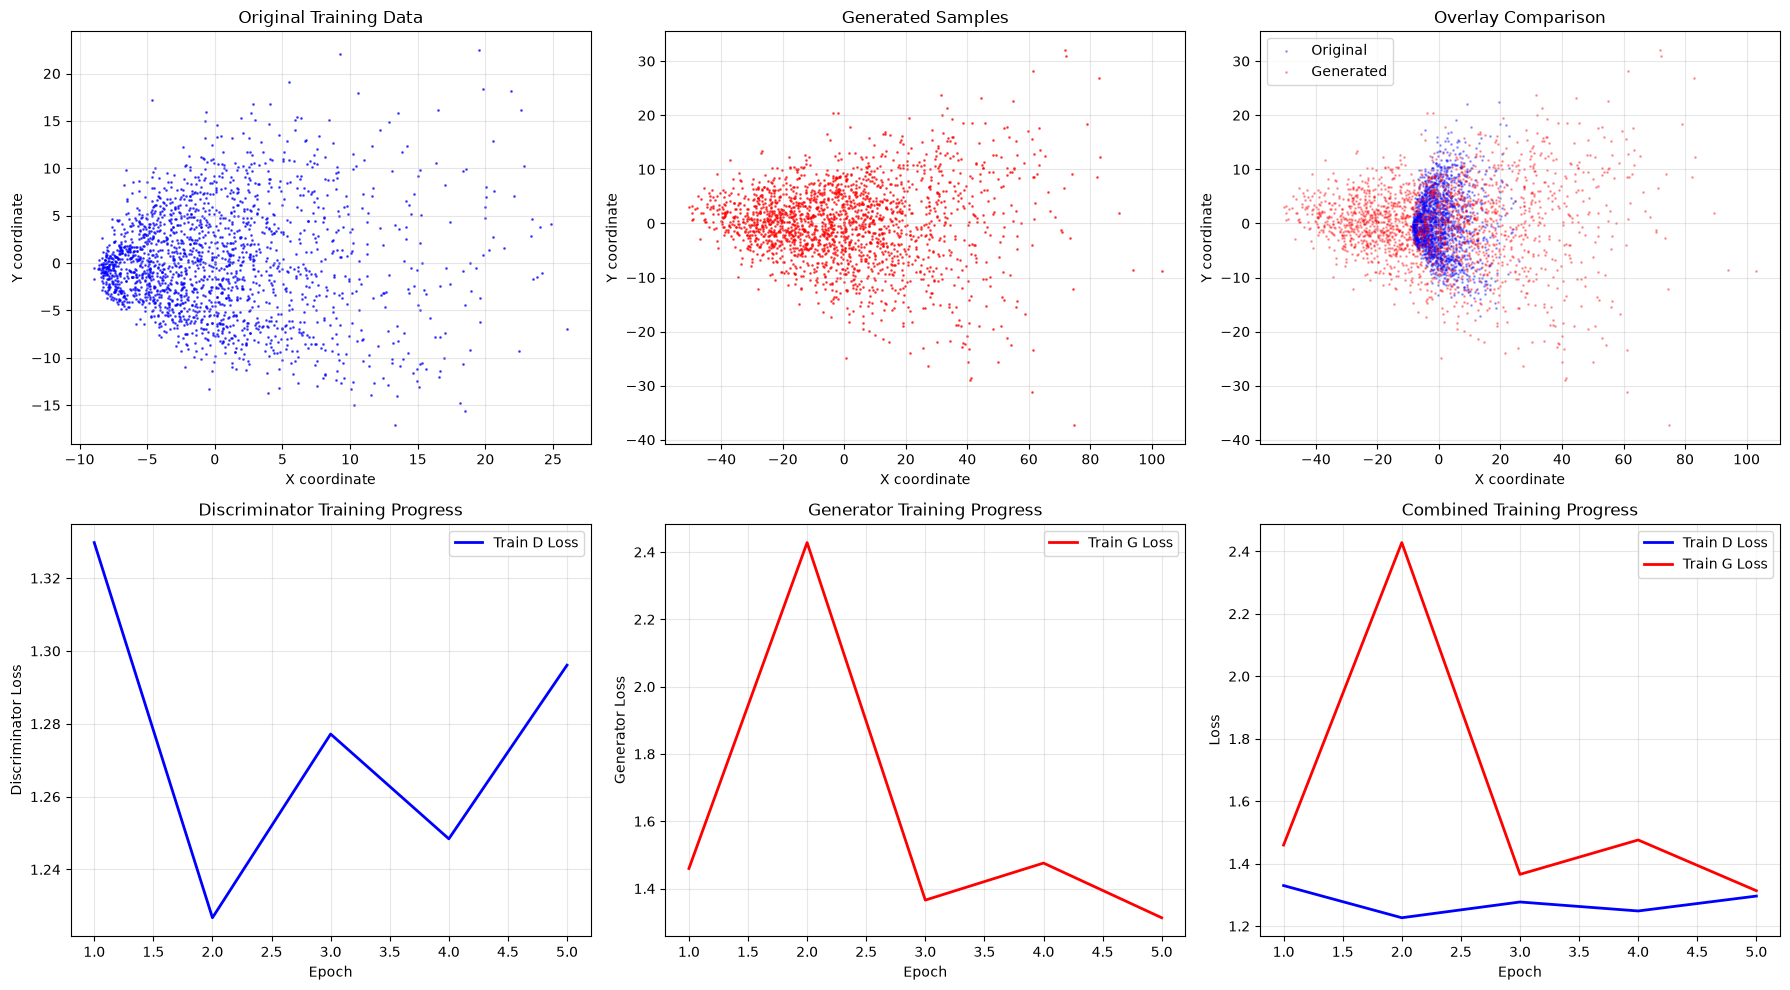

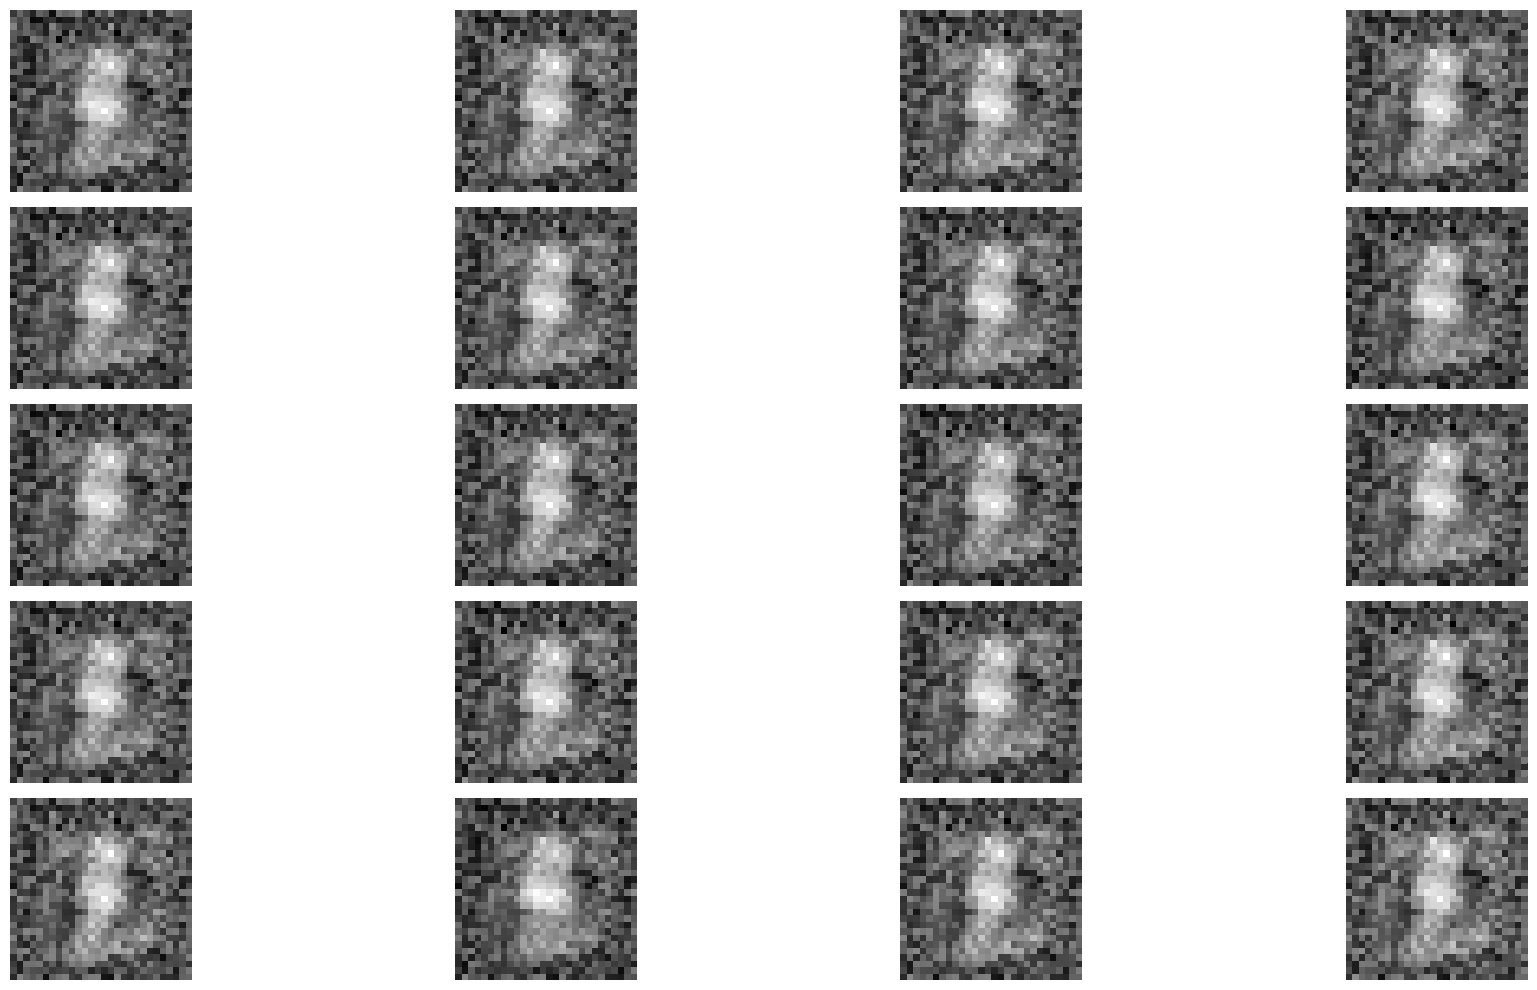

📈 Epoch 5 Summary:
   Train D Loss: 1.2961, Val D Loss: 1.2188
   Train G Loss: 1.3133, Val G Loss: 0.7786

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.212617	G_loss: 1.198699
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.217586	G_loss: 1.524377
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.887483	G_loss: 1.742830
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.518566	G_loss: 1.088565
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.002717	G_loss: 1.874009
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.387200	G_loss: 1.636432
Epoch: 6 [38400/60000 (64%)]	D_loss: 2.934576	G_loss: 1.648588
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.361972	G_loss: 1.019608
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.006900	G_loss: 1.220210
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.469216	G_loss: 1.391576
====> Epoch: 6 Train D_loss: 1.2381, Train G_loss: 1.4816
====> Epoch: 6 Val D_loss: 0.9278, Val G_loss: 1.1572
📈 Epoch 6 Summary:
   Train D Loss: 1.2381, Val D Loss: 0.9278
   Train G Loss: 1.4816, Val G Loss: 1

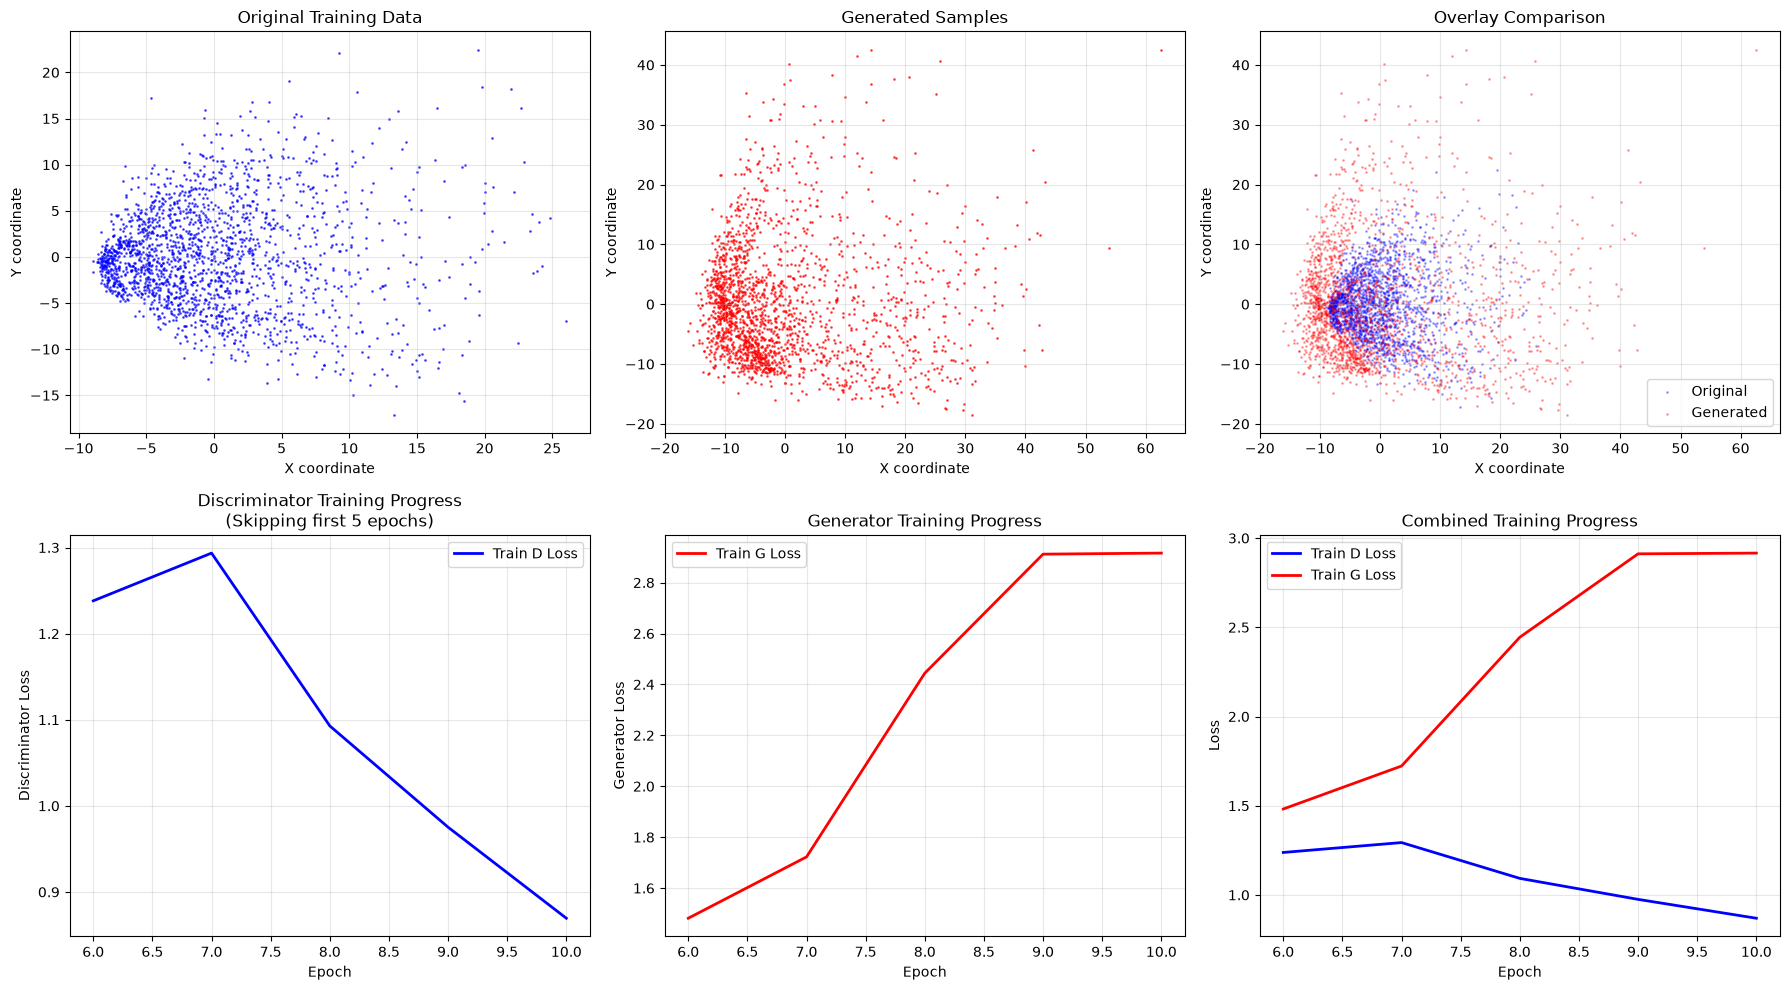

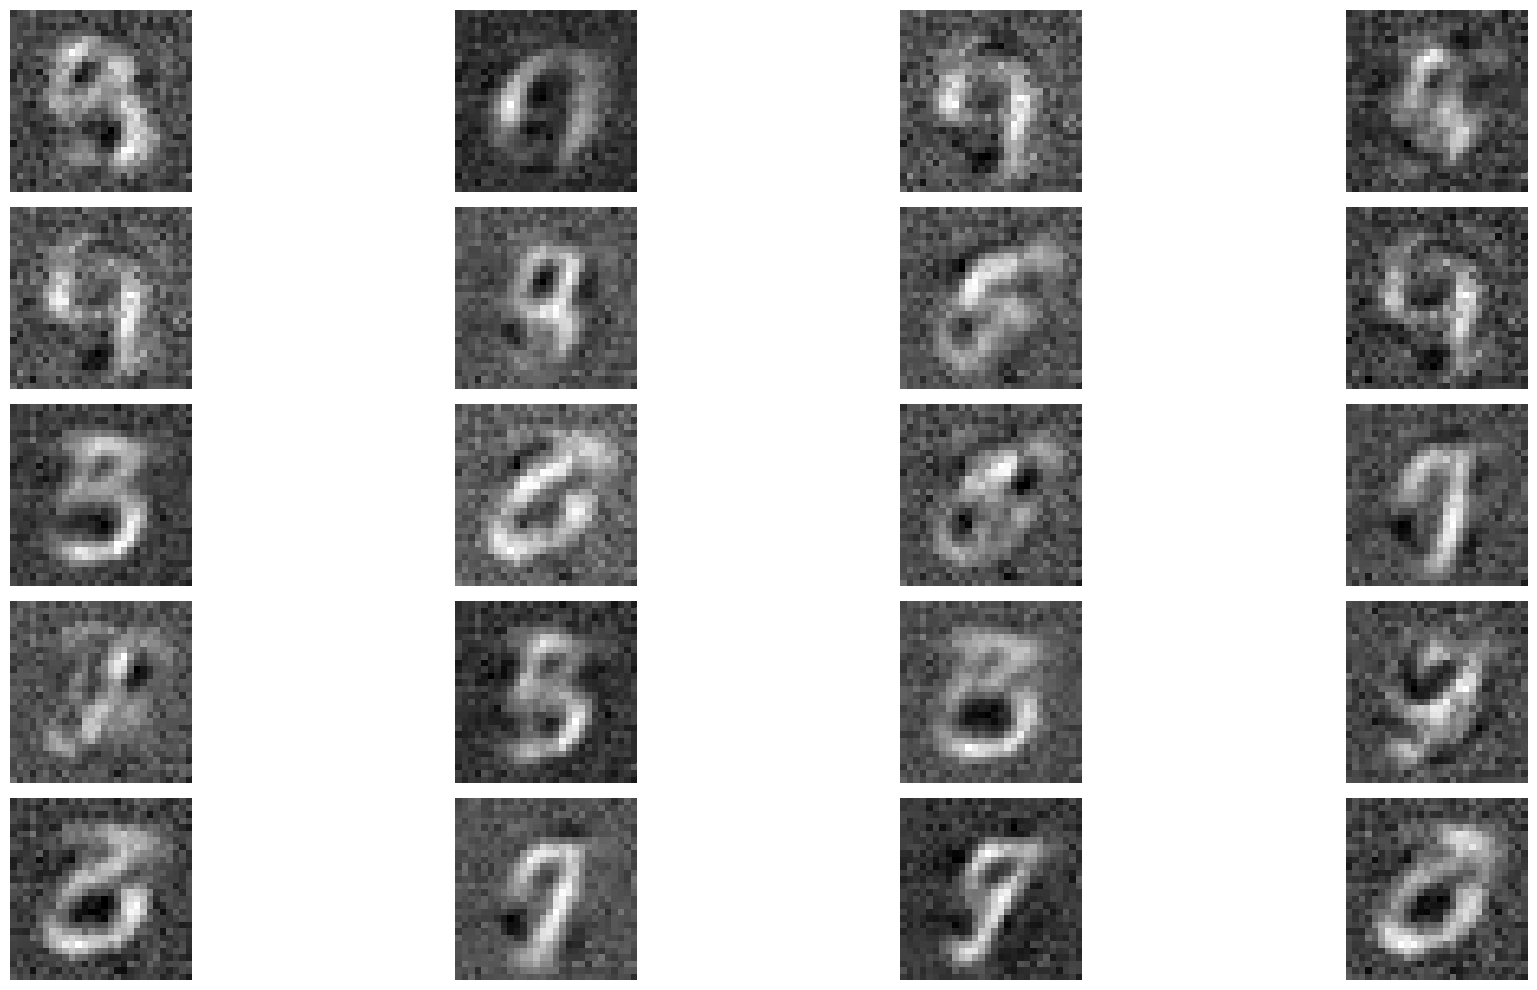

📈 Epoch 10 Summary:
   Train D Loss: 0.8695, Val D Loss: 1.0414
   Train G Loss: 2.9159, Val G Loss: 1.1750

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.143451	G_loss: 3.700909
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.947560	G_loss: 2.145137
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.577806	G_loss: 2.772799
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.936880	G_loss: 2.655274
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.912913	G_loss: 2.596714
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.712755	G_loss: 3.056621
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.688925	G_loss: 3.034749
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.934155	G_loss: 2.708838
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.710840	G_loss: 3.754738
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.786574	G_loss: 2.521280
====> Epoch: 11 Train D_loss: 0.9016, Train G_loss: 2.5942
====> Epoch: 11 Val D_loss: 0.7960, Val G_loss: 1.4571
📈 Epoch 11 Summary:
   Train D Loss: 0.9016, Val D Loss: 0.7960
   Train G Loss: 2.5942

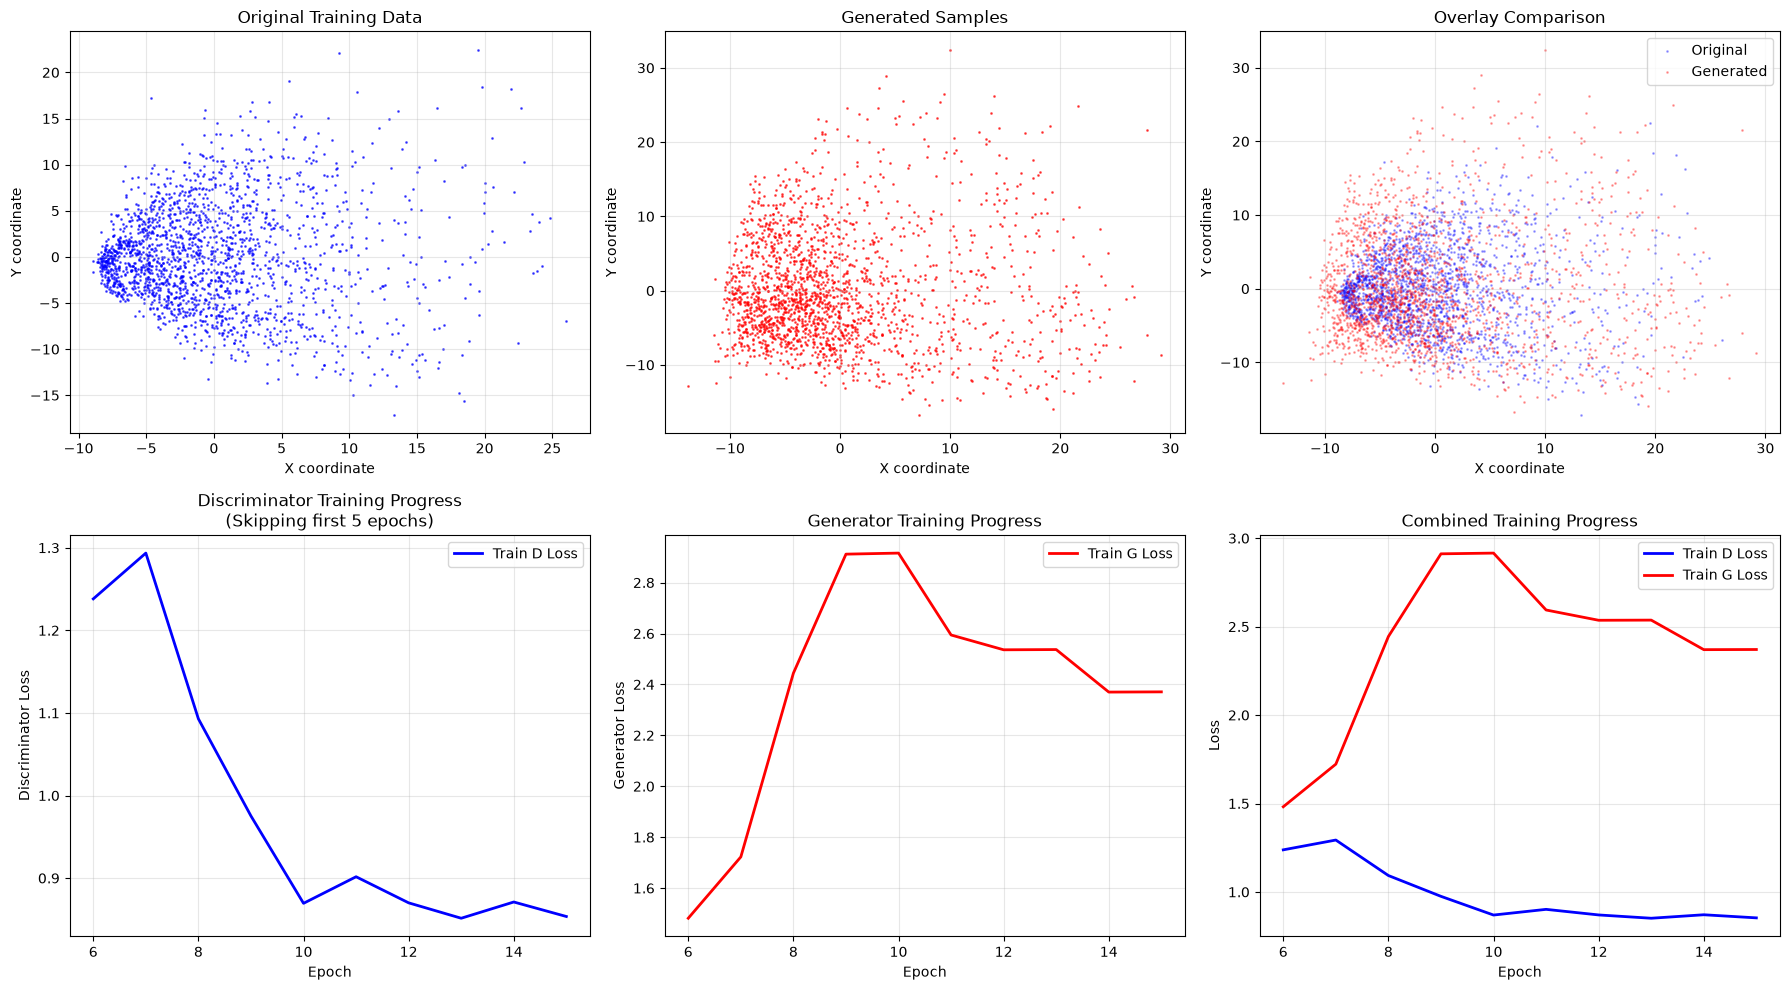

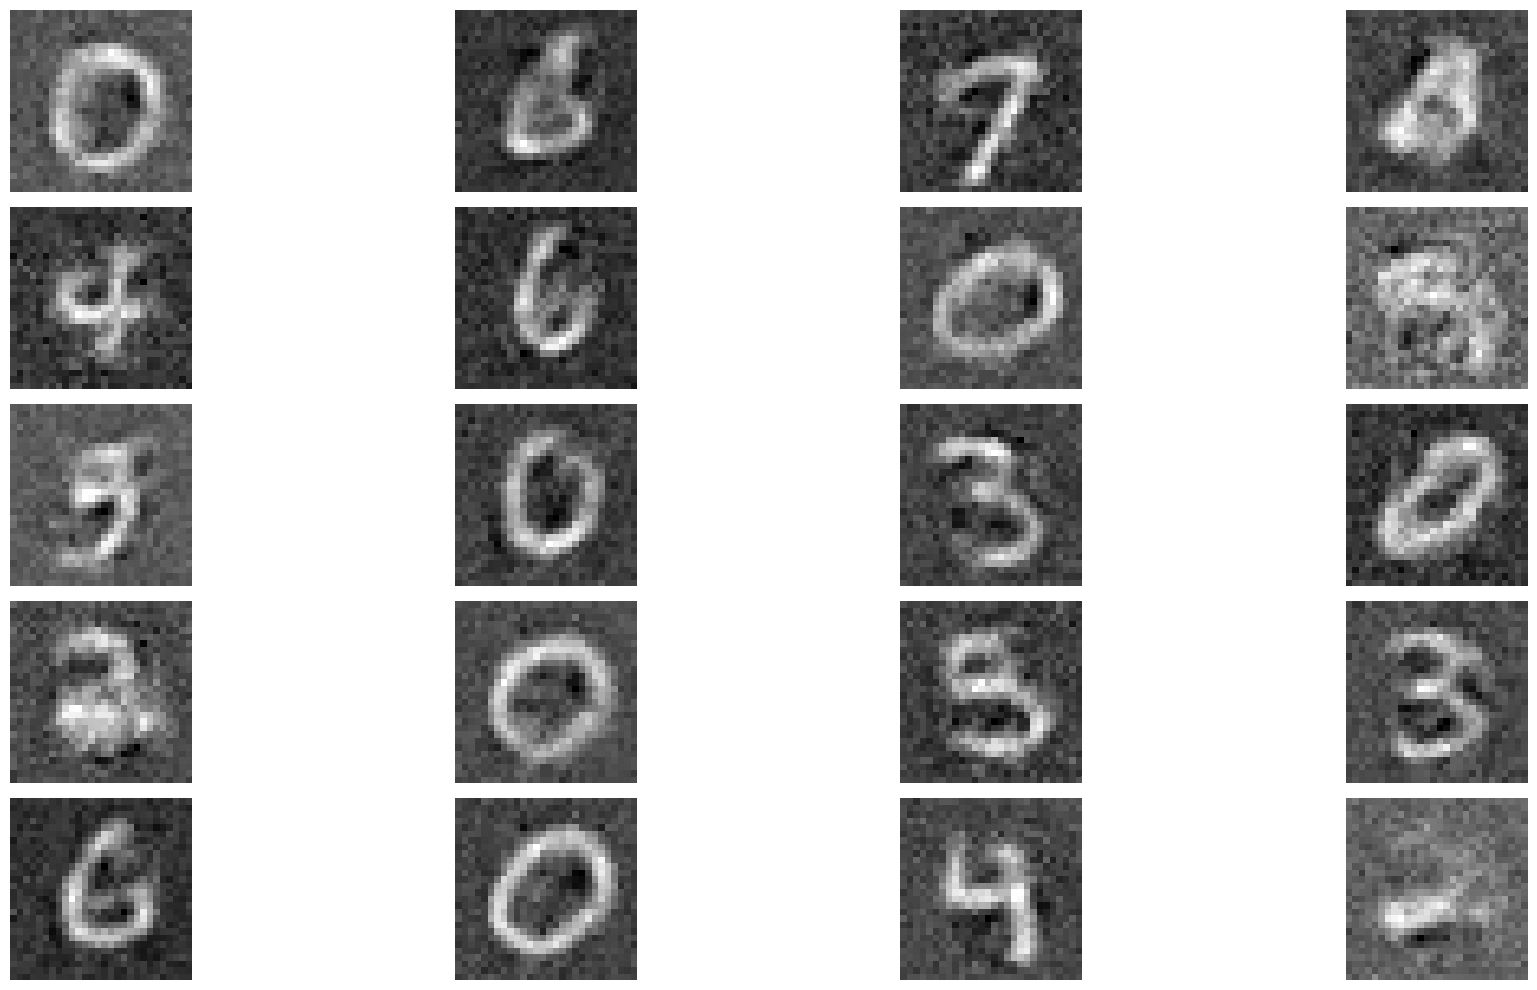

📈 Epoch 15 Summary:
   Train D Loss: 0.8535, Val D Loss: 0.7173
   Train G Loss: 2.3708, Val G Loss: 1.6967

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.744467	G_loss: 2.136039
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.638596	G_loss: 3.189848
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.867722	G_loss: 3.097841
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.754437	G_loss: 2.424800
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.744058	G_loss: 2.106069
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.904028	G_loss: 1.542461
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.107882	G_loss: 1.186603
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.778761	G_loss: 2.123282
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.679907	G_loss: 1.883462
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.741574	G_loss: 1.752852
====> Epoch: 16 Train D_loss: 0.8344, Train G_loss: 2.4113
====> Epoch: 16 Val D_loss: 0.7318, Val G_loss: 1.2855
📈 Epoch 16 Summary:
   Train D Loss: 0.8344, Val D Loss: 0.7318
   Train G Loss: 2.4113

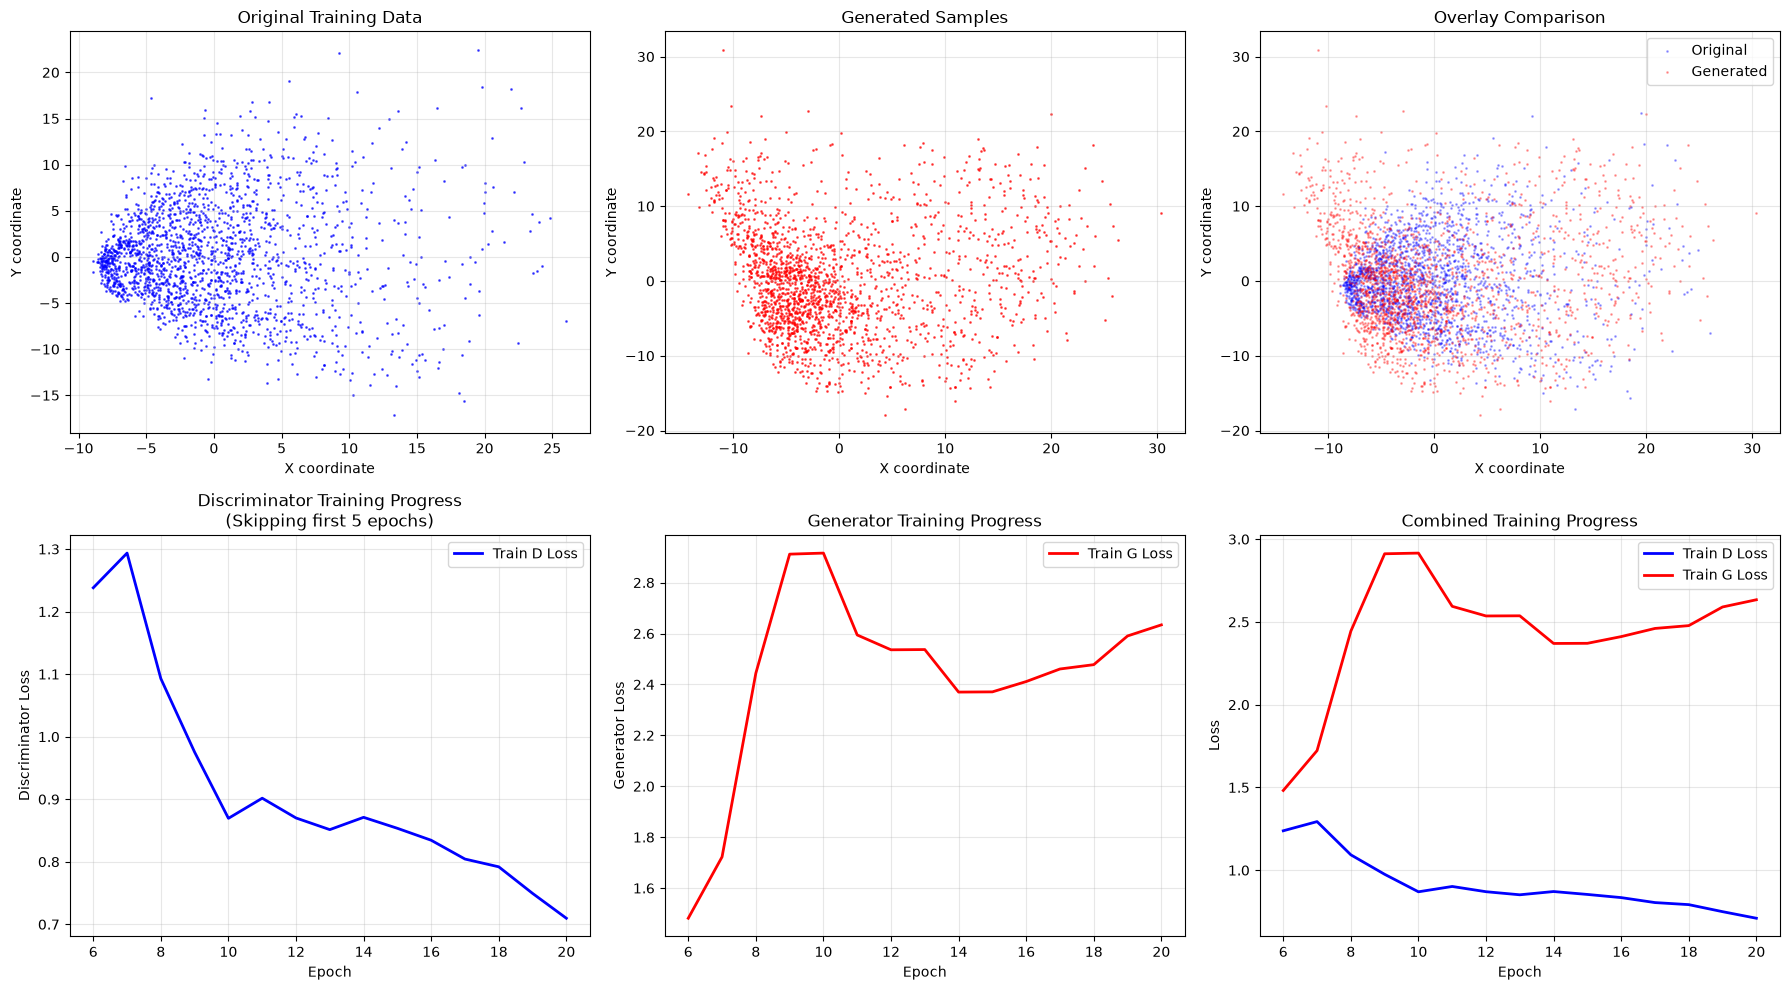

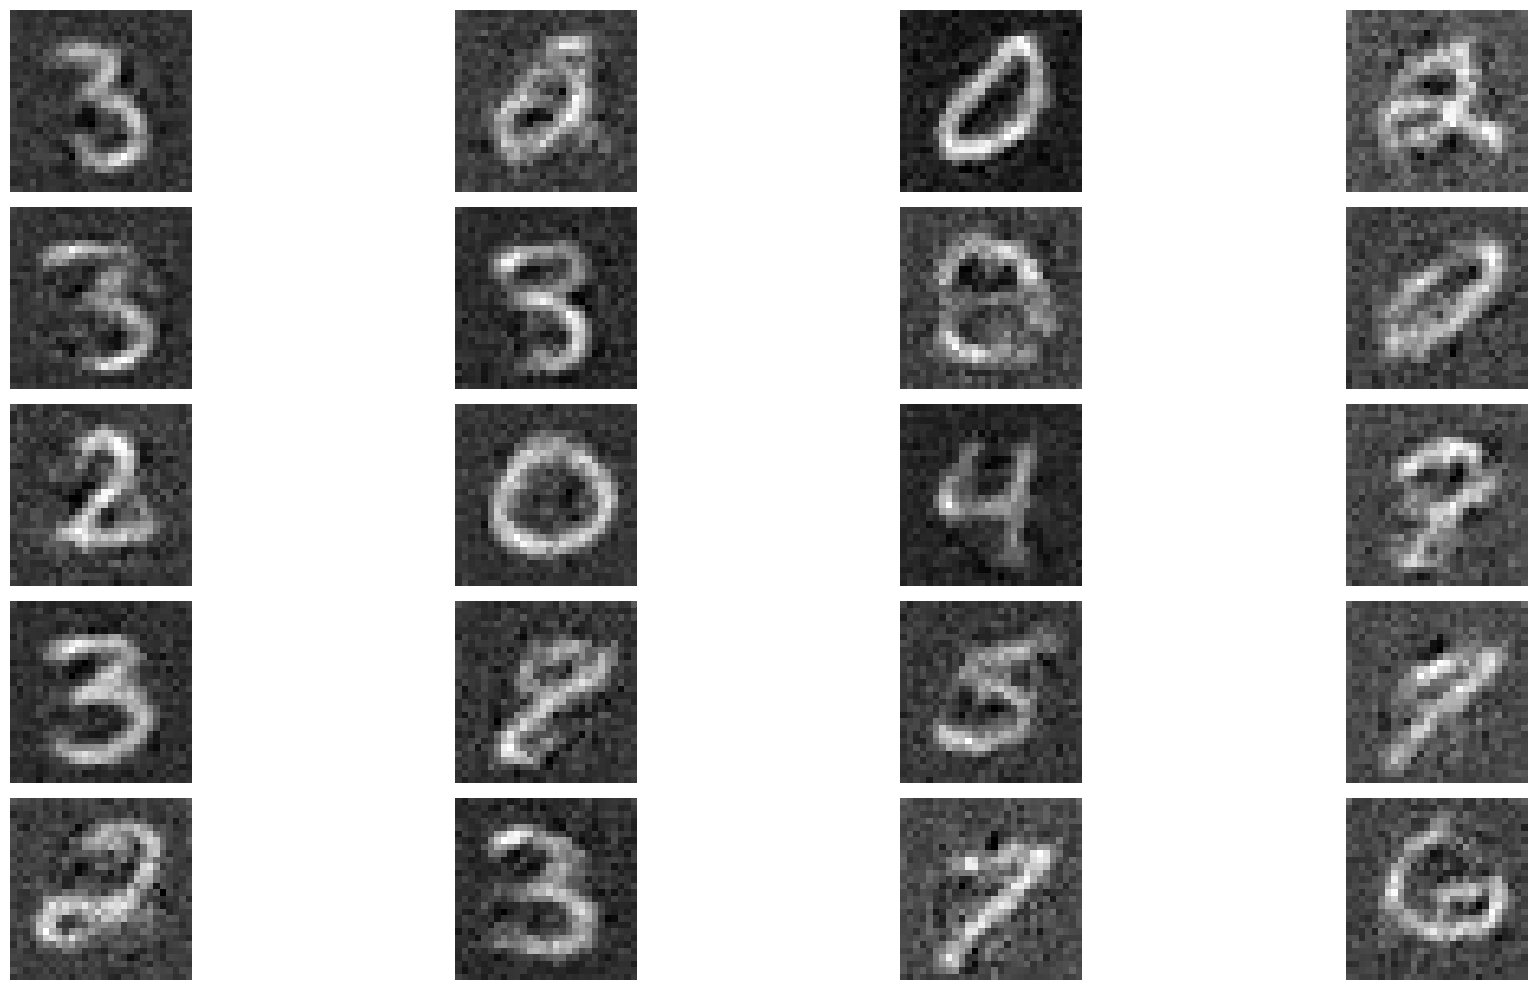

📈 Epoch 20 Summary:
   Train D Loss: 0.7097, Val D Loss: 0.5917
   Train G Loss: 2.6340, Val G Loss: 1.9463

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.572748	G_loss: 2.823761
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.582054	G_loss: 1.744884
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.592813	G_loss: 2.999316
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.833109	G_loss: 2.476132
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.704498	G_loss: 2.304444
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.480012	G_loss: 2.688485
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.638833	G_loss: 2.715437
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.695726	G_loss: 2.466879
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.593864	G_loss: 2.747710
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.638601	G_loss: 2.560299
====> Epoch: 21 Train D_loss: 0.6746, Train G_loss: 2.7186
====> Epoch: 21 Val D_loss: 0.6987, Val G_loss: 2.6021
📈 Epoch 21 Summary:
   Train D Loss: 0.6746, Val D Loss: 0.6987
   Train G Loss: 2.7186

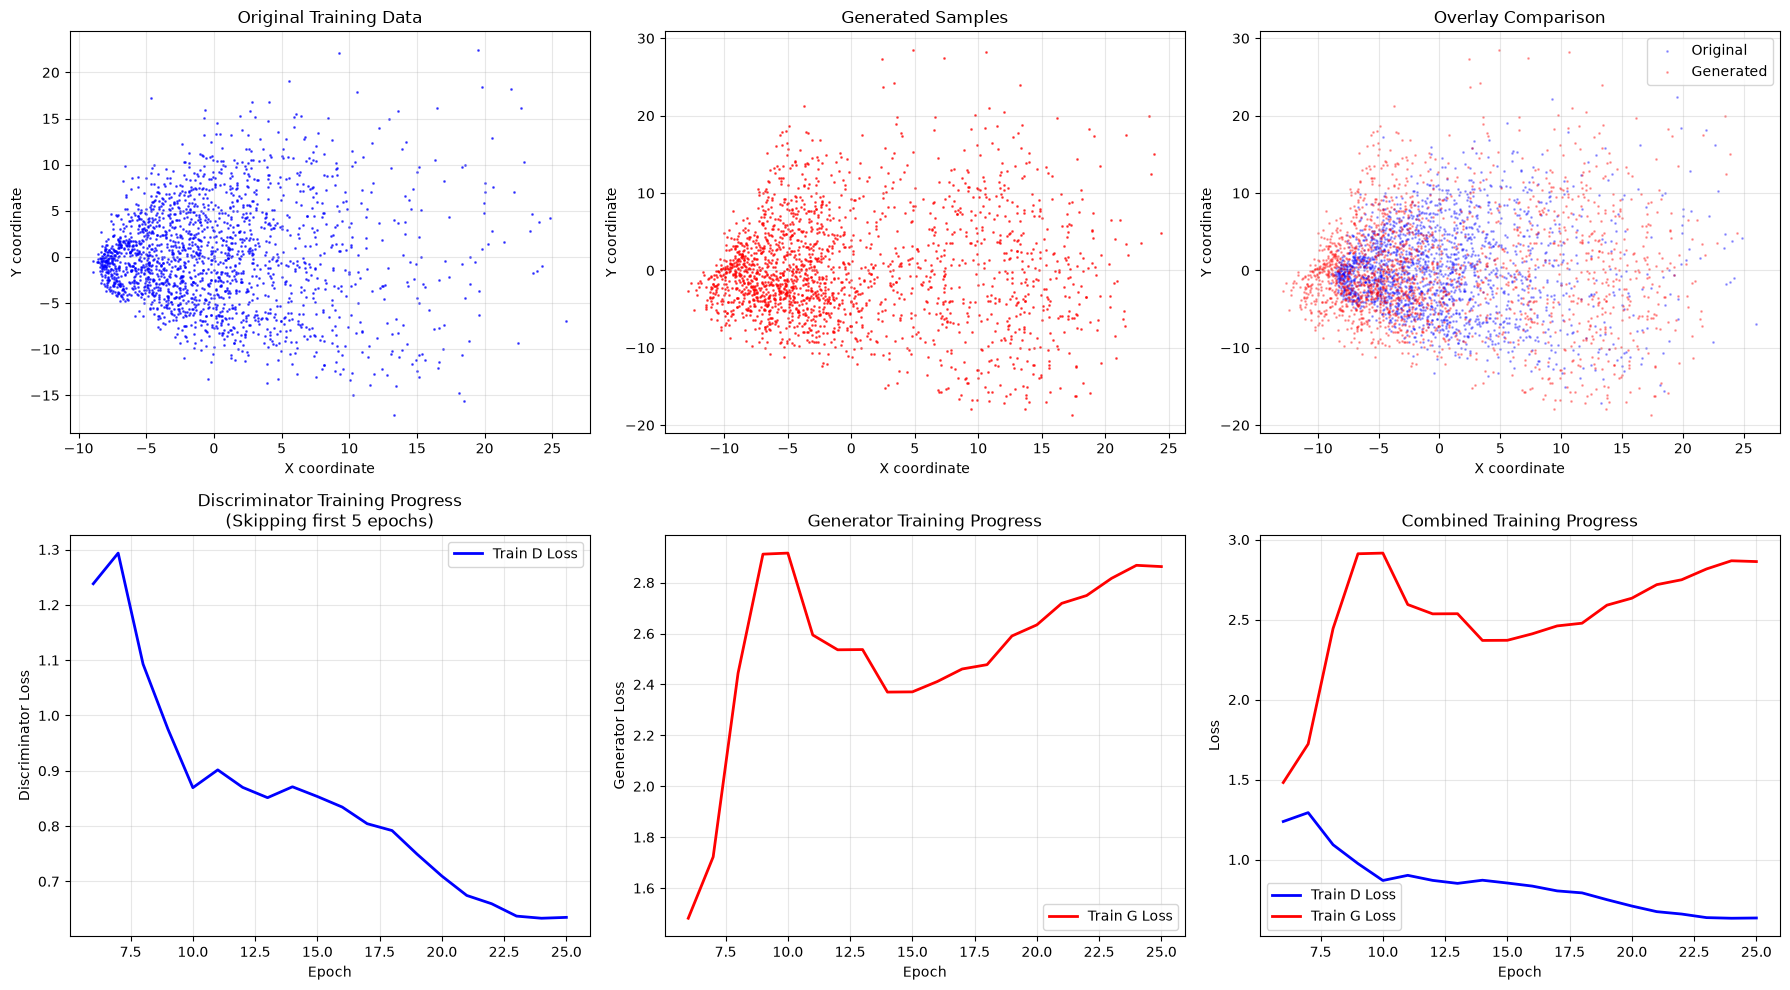

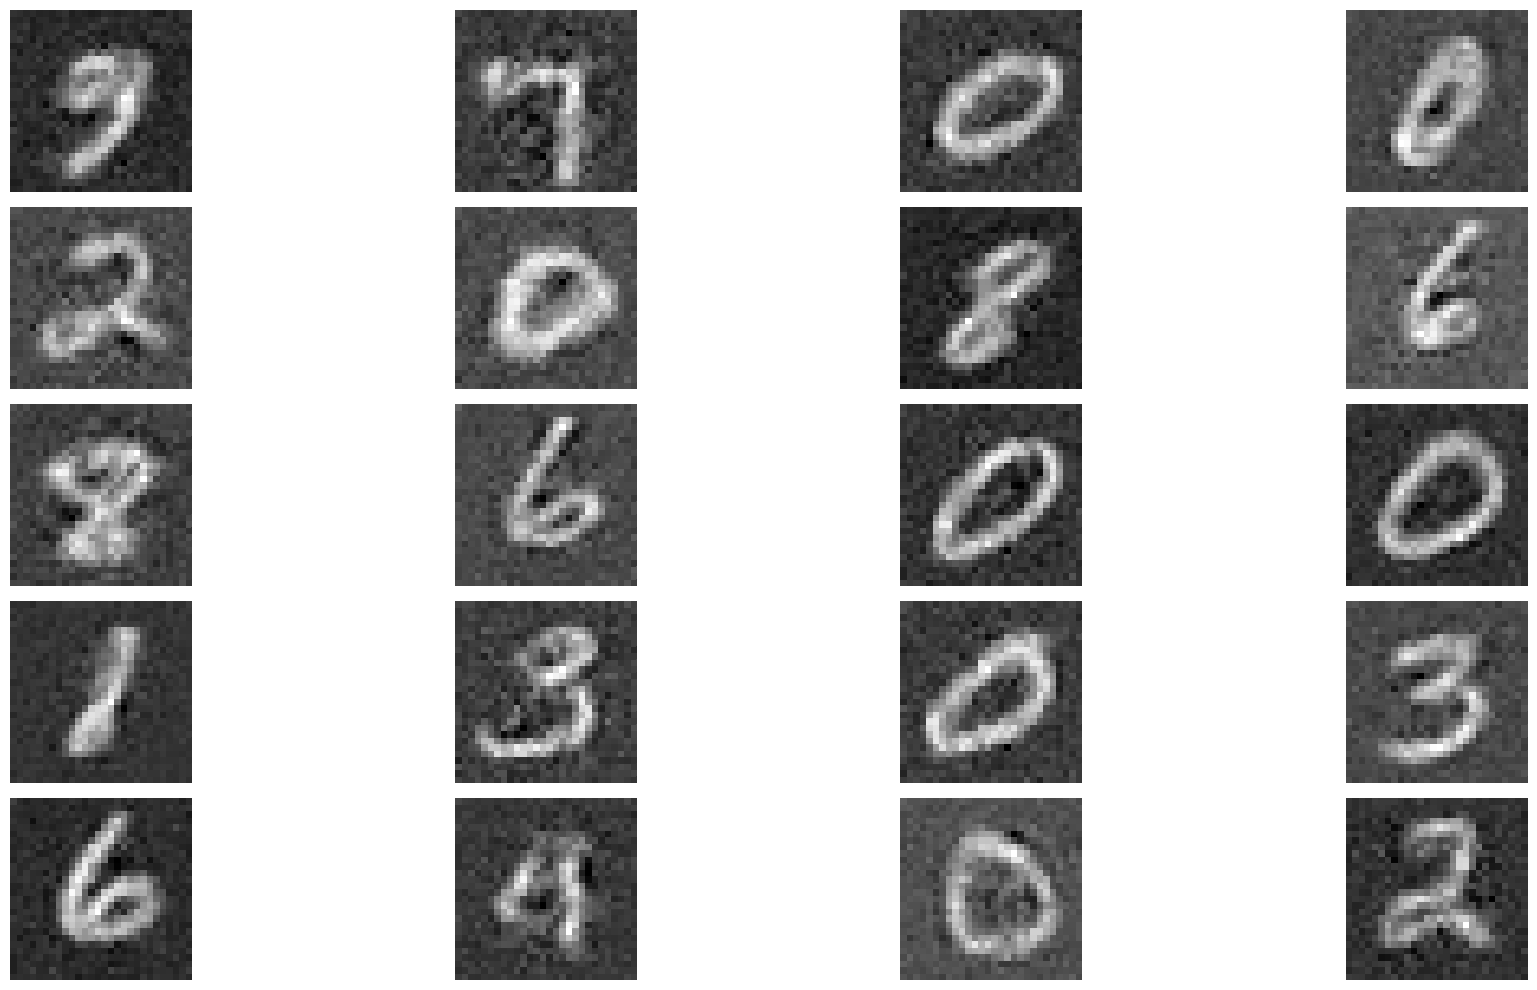

📈 Epoch 25 Summary:
   Train D Loss: 0.6350, Val D Loss: 0.6451
   Train G Loss: 2.8629, Val G Loss: 2.2608

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.446451	G_loss: 3.148943
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.578540	G_loss: 2.455120
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.579228	G_loss: 5.264449
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.591523	G_loss: 2.993688
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.519256	G_loss: 2.620529
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.605540	G_loss: 3.408229
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.724344	G_loss: 1.885851
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.593139	G_loss: 3.664549
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.383496	G_loss: 2.871385
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.618045	G_loss: 3.277528
====> Epoch: 26 Train D_loss: 0.6172, Train G_loss: 2.9380
====> Epoch: 26 Val D_loss: 0.6684, Val G_loss: 2.1171
📈 Epoch 26 Summary:
   Train D Loss: 0.6172, Val D Loss: 0.6684
   Train G Loss: 2.9380

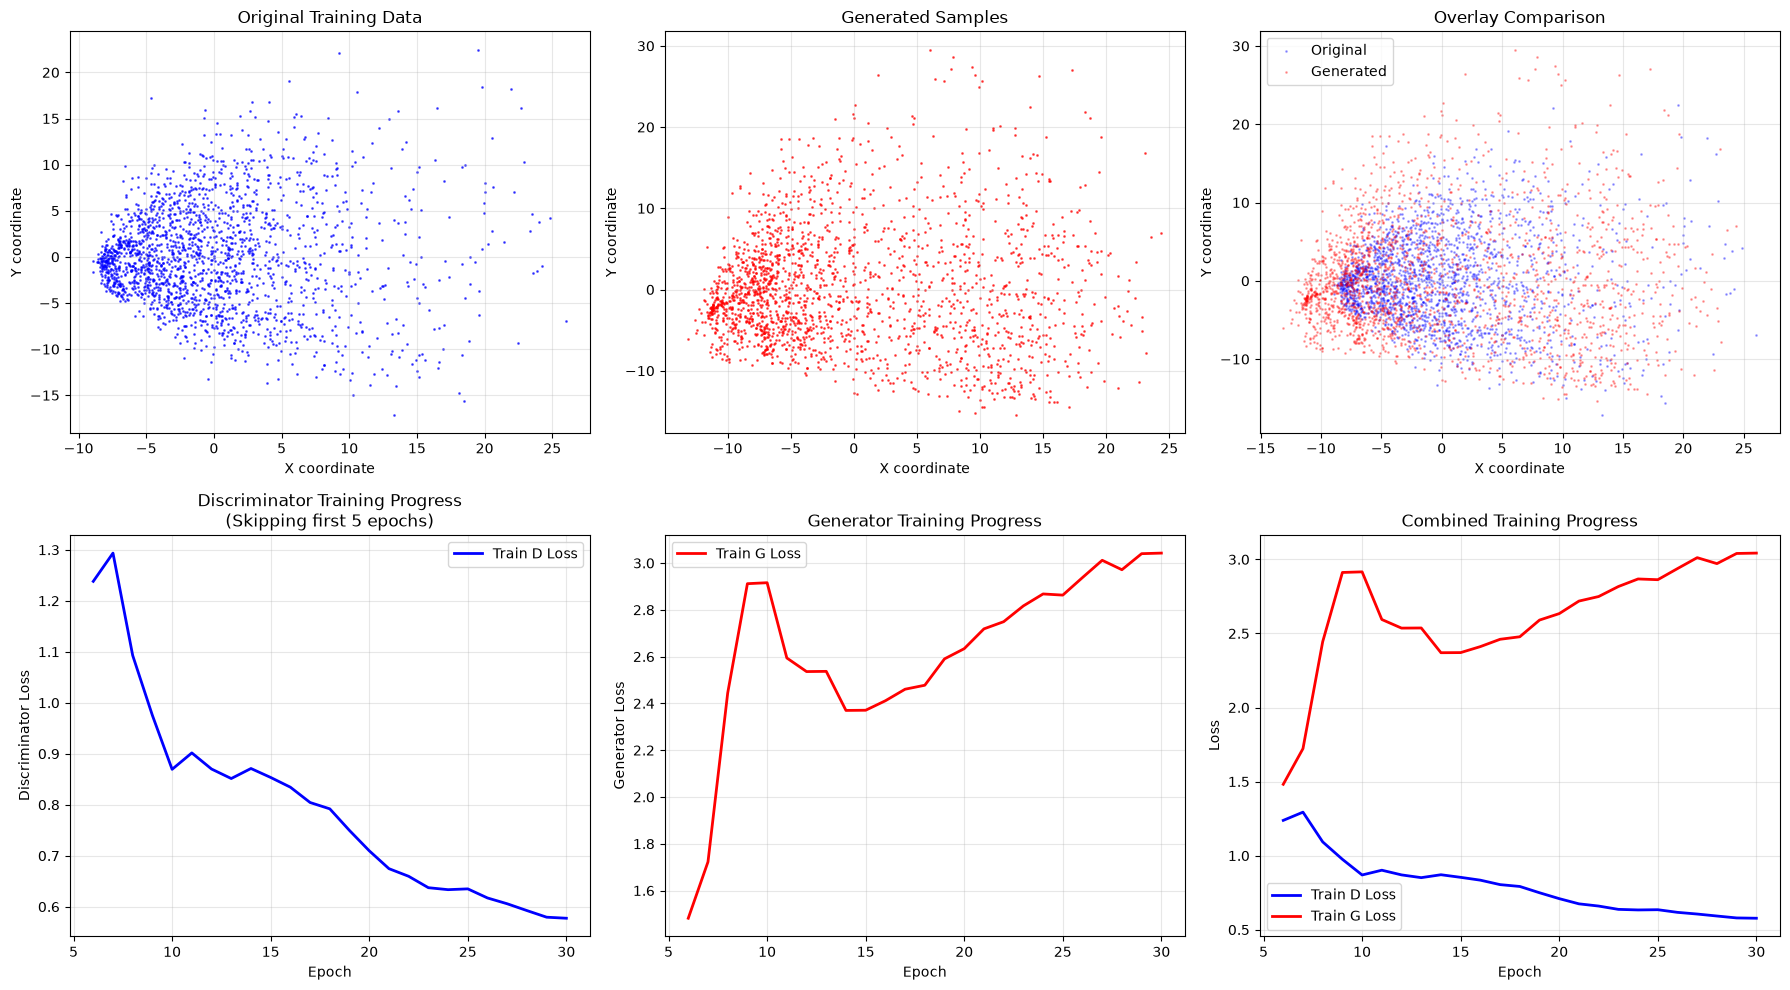

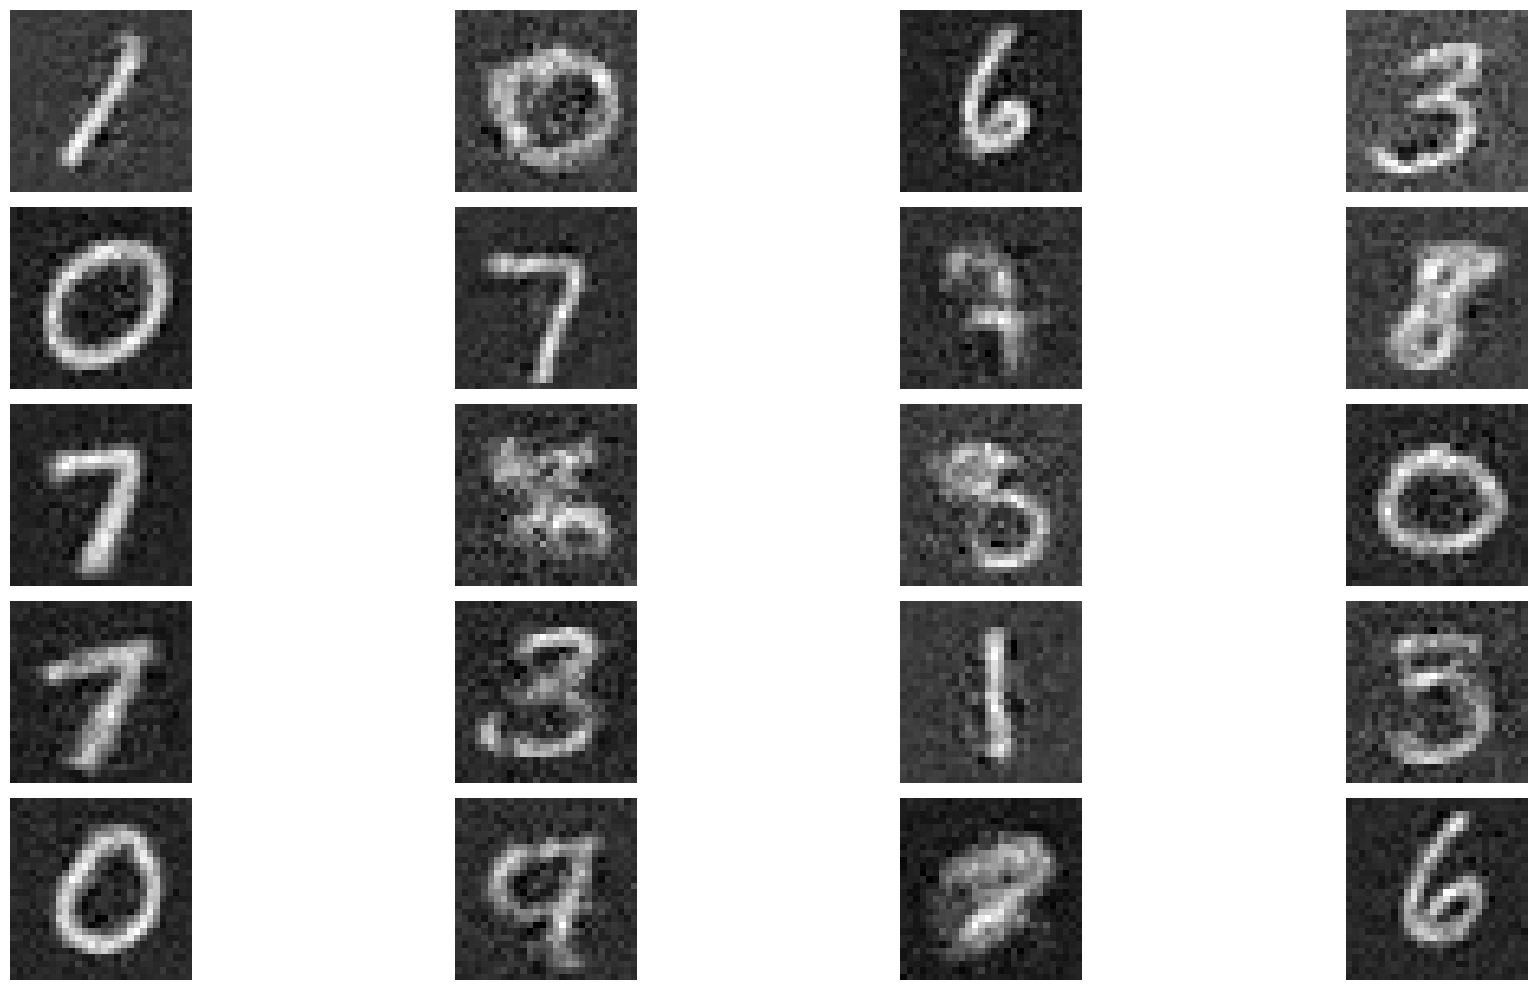

📈 Epoch 30 Summary:
   Train D Loss: 0.5774, Val D Loss: 0.4578
   Train G Loss: 3.0425, Val G Loss: 2.7876

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.395910	G_loss: 2.613441
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.531245	G_loss: 3.519229
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.532228	G_loss: 2.827710
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.515339	G_loss: 3.532441
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.657564	G_loss: 3.080690
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.444899	G_loss: 2.799150
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.547834	G_loss: 1.983765
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.635274	G_loss: 3.078354
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.503671	G_loss: 3.016486
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.630067	G_loss: 3.486105
====> Epoch: 31 Train D_loss: 0.5595, Train G_loss: 3.0858
====> Epoch: 31 Val D_loss: 0.4933, Val G_loss: 2.2097
📈 Epoch 31 Summary:
   Train D Loss: 0.5595, Val D Loss: 0.4933
   Train G Loss: 3.0858

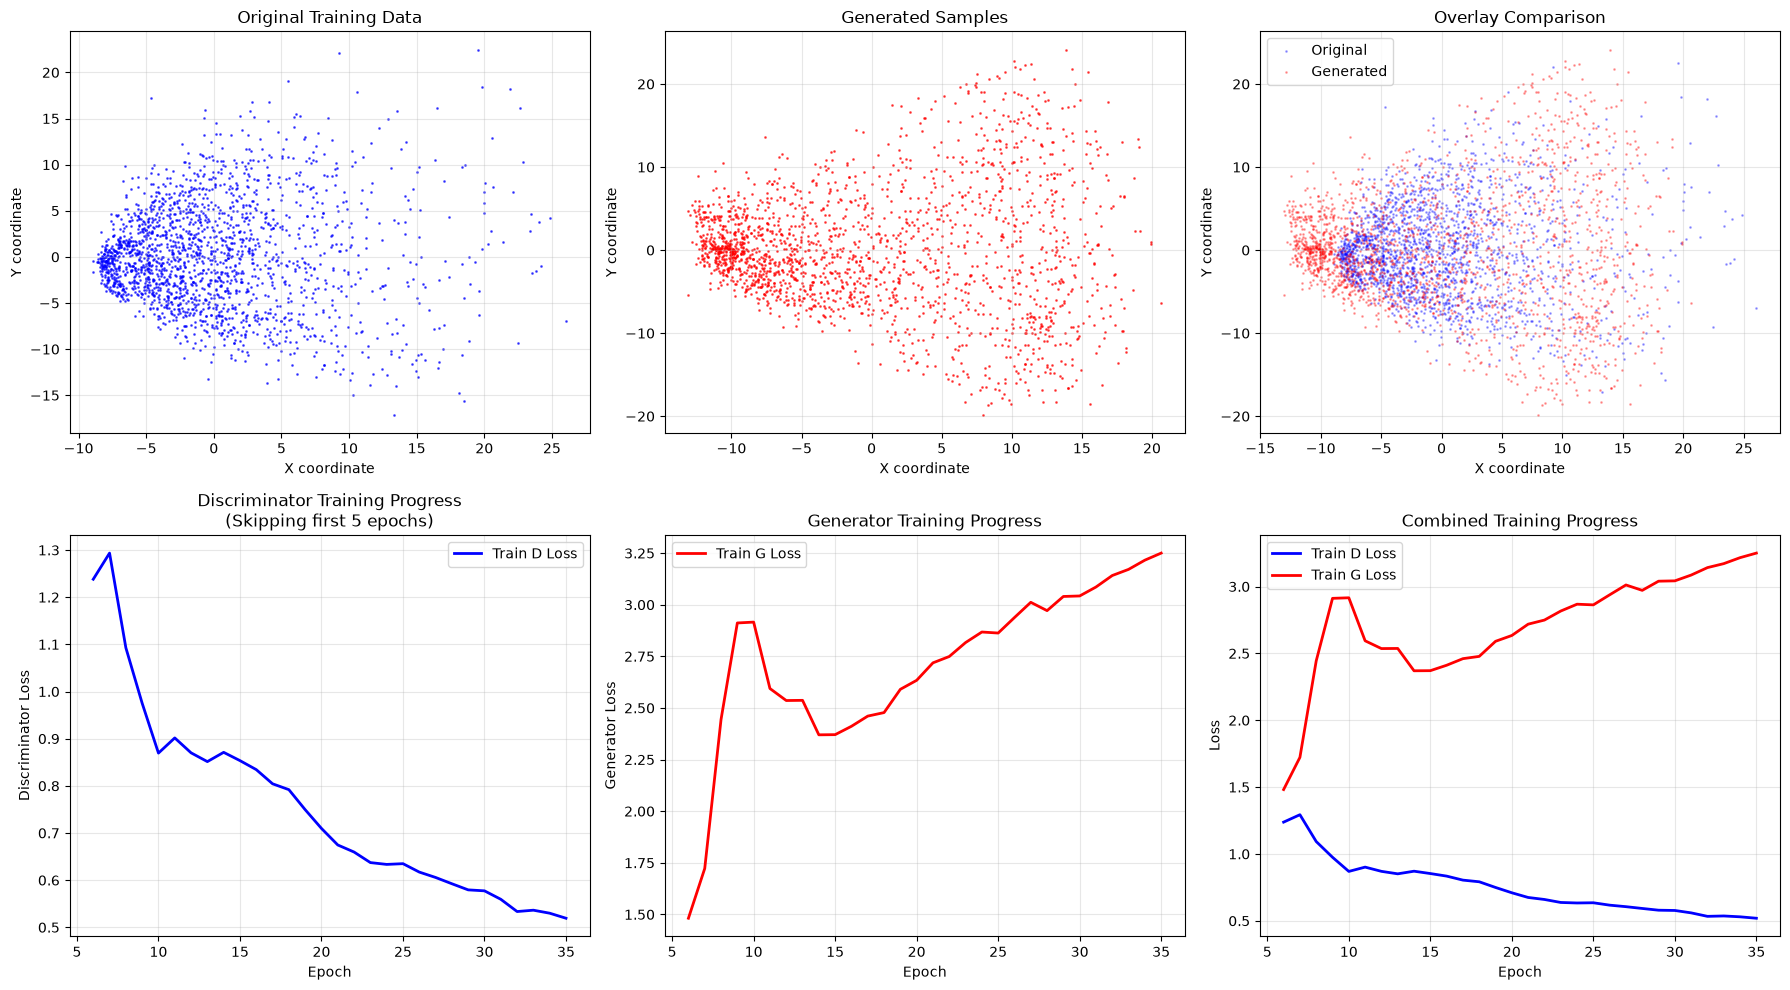

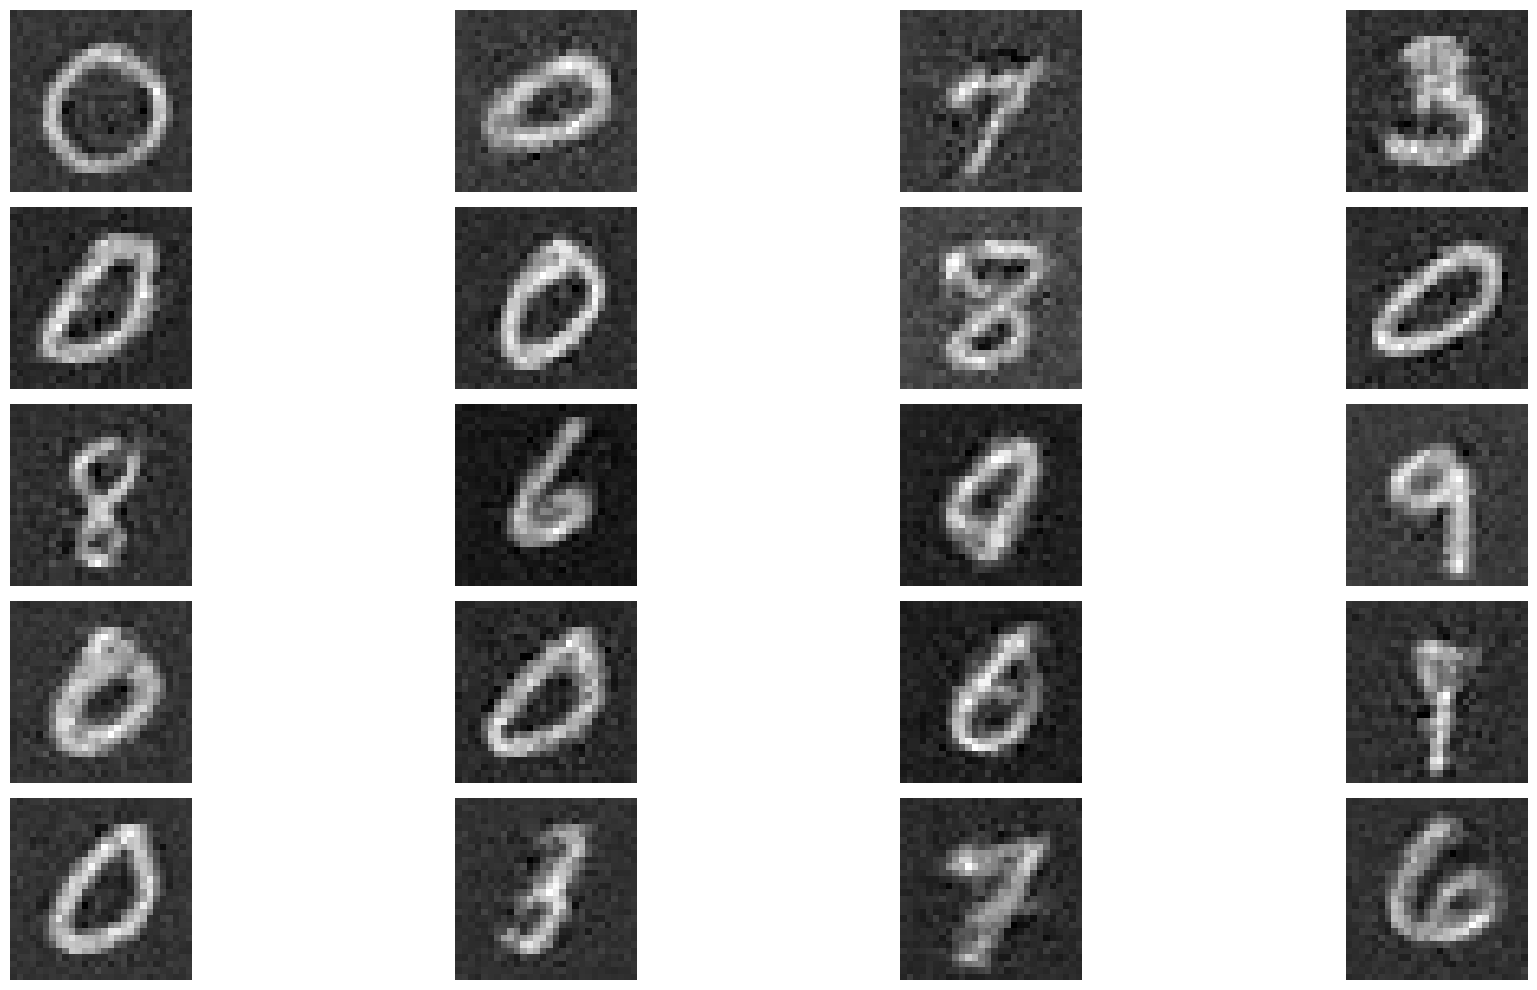

📈 Epoch 35 Summary:
   Train D Loss: 0.5193, Val D Loss: 1.0723
   Train G Loss: 3.2501, Val G Loss: 4.6429

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.760426	G_loss: 2.523485
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.675729	G_loss: 3.151256
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.348823	G_loss: 2.947732
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.388113	G_loss: 3.038773
Epoch: 36 [25600/60000 (43%)]	D_loss: 1.133274	G_loss: 1.894748
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.391276	G_loss: 2.876577
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.478407	G_loss: 2.719086
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.419144	G_loss: 2.796252
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.623379	G_loss: 4.829808
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.589369	G_loss: 2.651279
====> Epoch: 36 Train D_loss: 0.5337, Train G_loss: 3.2437
====> Epoch: 36 Val D_loss: 0.6531, Val G_loss: 1.4767
📈 Epoch 36 Summary:
   Train D Loss: 0.5337, Val D Loss: 0.6531
   Train G Loss: 3.2437

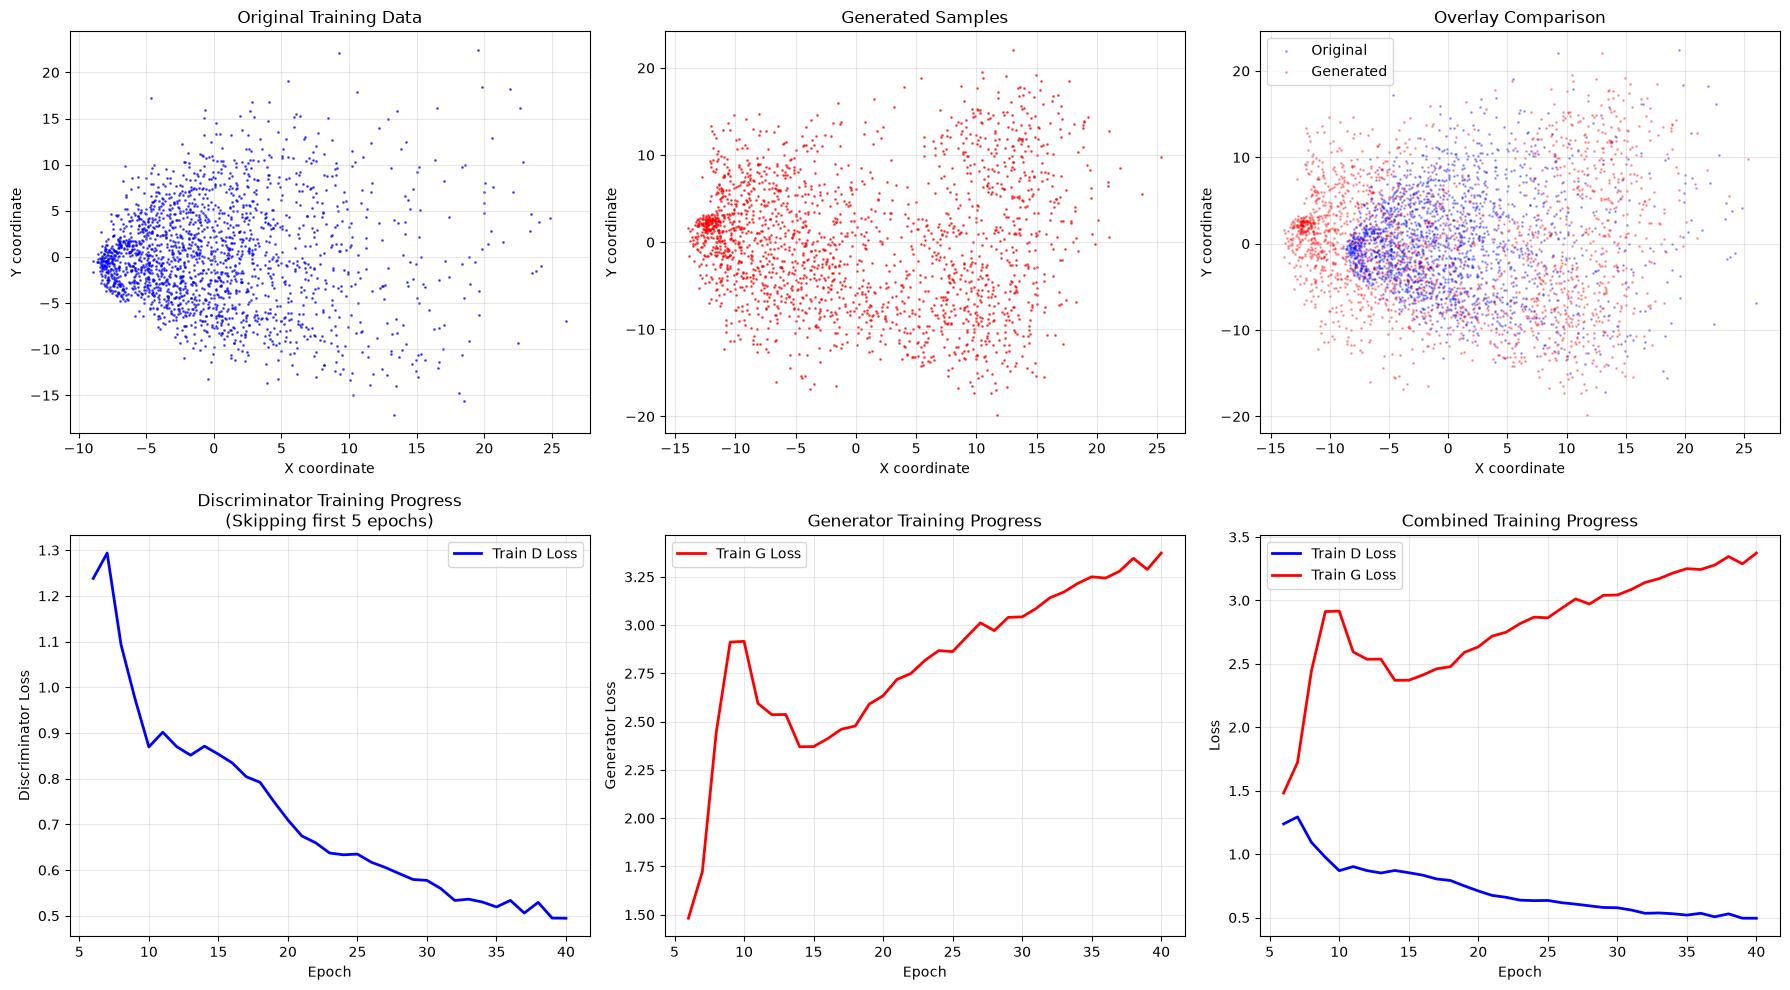

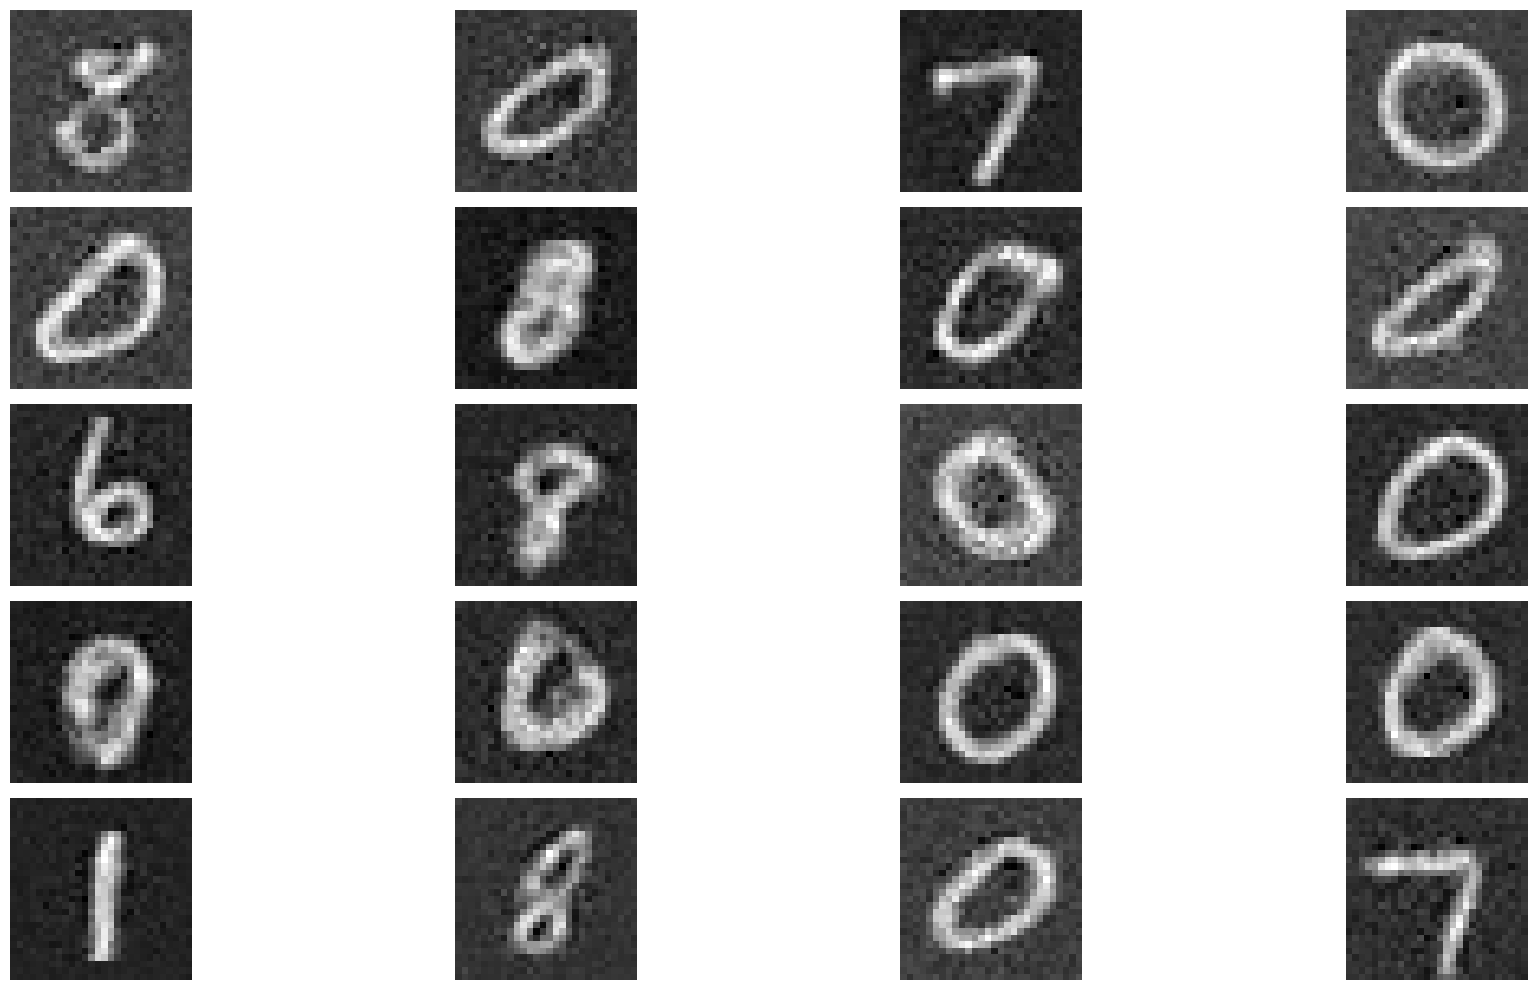

📈 Epoch 40 Summary:
   Train D Loss: 0.4946, Val D Loss: 0.4577
   Train G Loss: 3.3730, Val G Loss: 2.5012

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.359481	G_loss: 3.201540
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.545939	G_loss: 2.803830
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.424493	G_loss: 3.455026
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.512508	G_loss: 2.645292
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.644933	G_loss: 2.160158
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.402848	G_loss: 4.161477
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.288292	G_loss: 3.833134
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.401825	G_loss: 3.750662
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.402023	G_loss: 3.962175
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.416828	G_loss: 3.747172
====> Epoch: 41 Train D_loss: 0.4835, Train G_loss: 3.4705
====> Epoch: 41 Val D_loss: 0.4750, Val G_loss: 2.5555
📈 Epoch 41 Summary:
   Train D Loss: 0.4835, Val D Loss: 0.4750
   Train G Loss: 3.4705

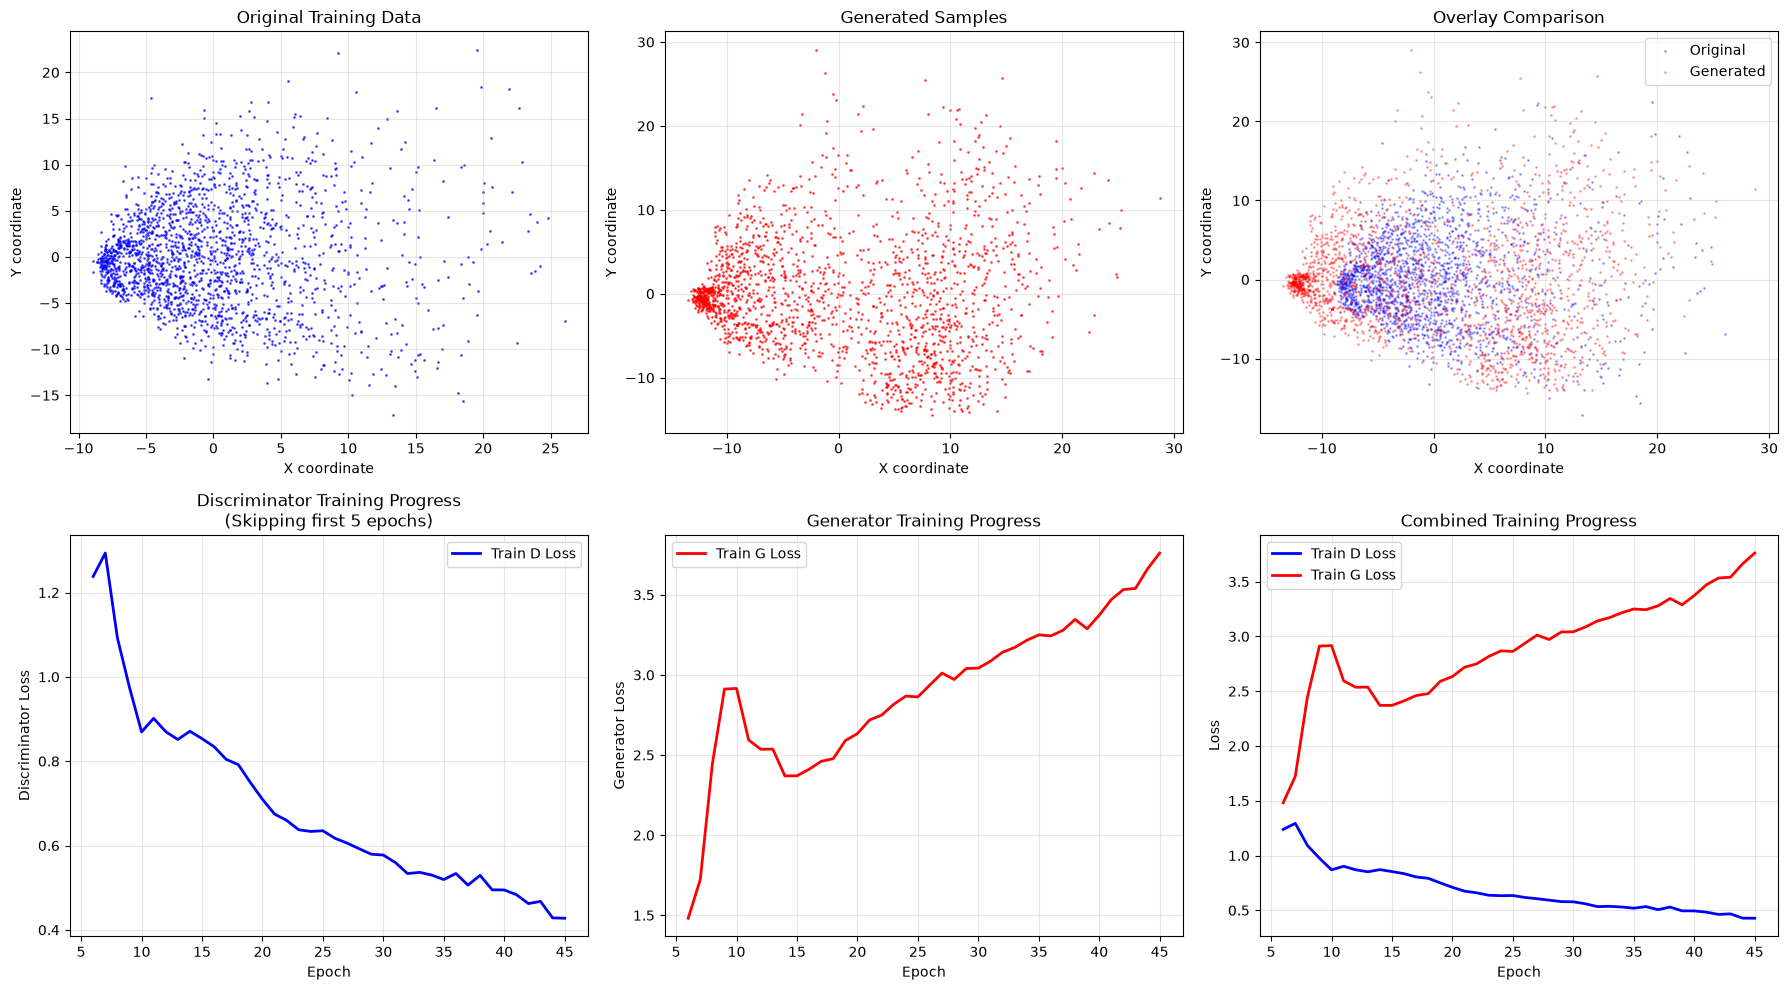

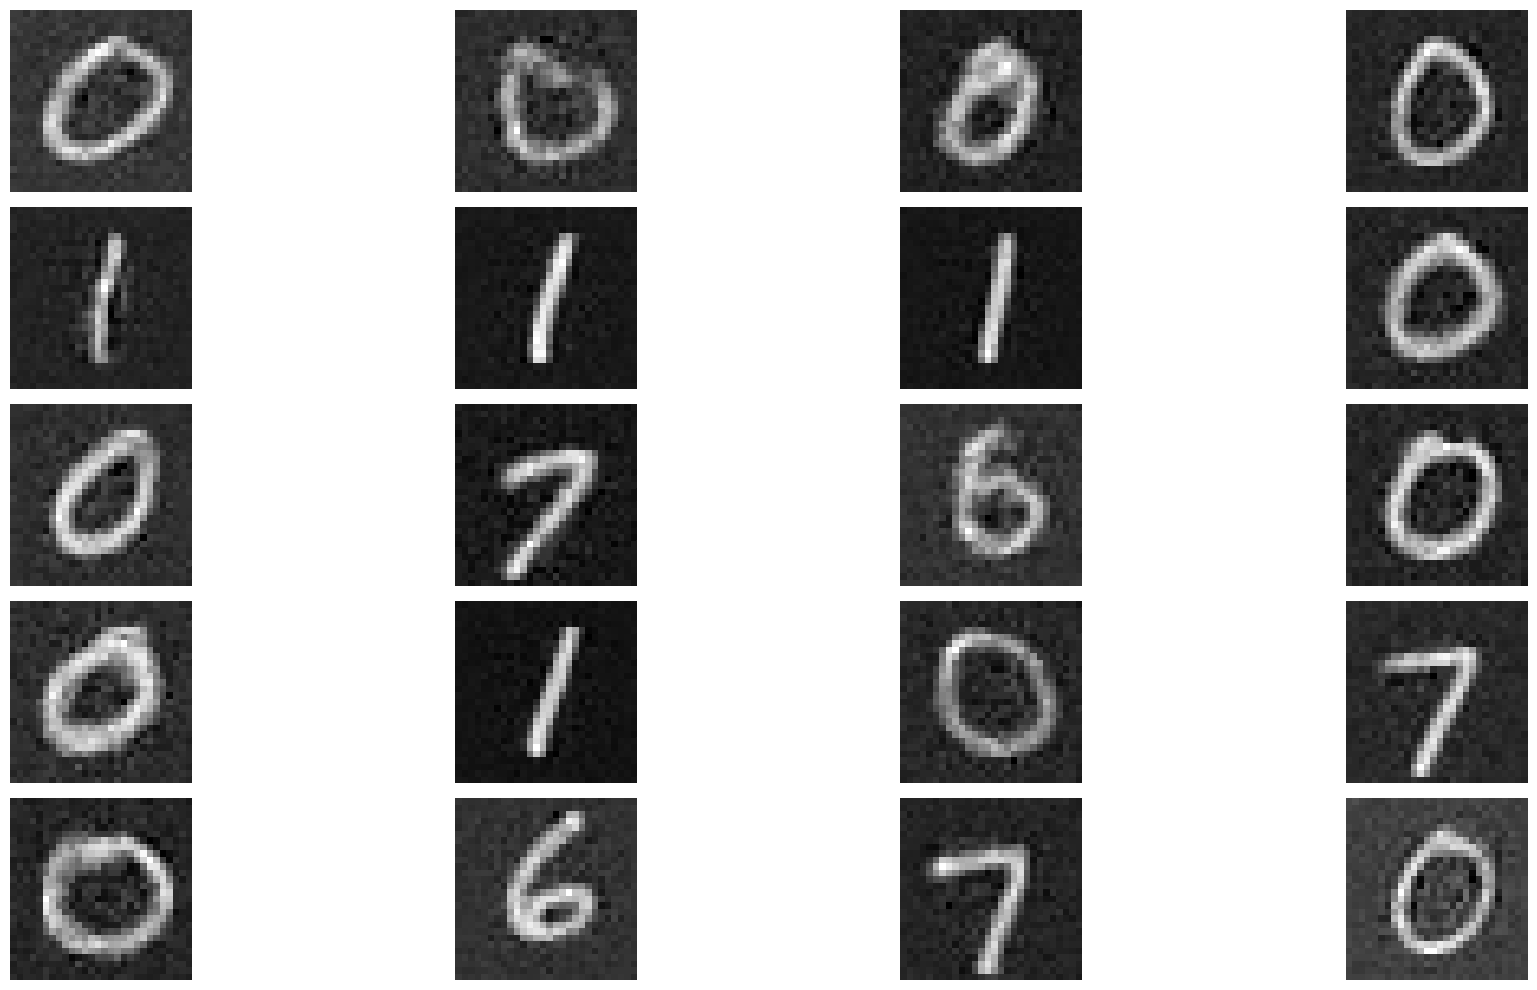

📈 Epoch 45 Summary:
   Train D Loss: 0.4275, Val D Loss: 0.5519
   Train G Loss: 3.7604, Val G Loss: 3.0153

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.504451	G_loss: 3.615875
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.390695	G_loss: 2.731120
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.667023	G_loss: 4.572616
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.310856	G_loss: 3.518868
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.614844	G_loss: 6.346779
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.416942	G_loss: 4.011760
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.324407	G_loss: 4.088533
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.235098	G_loss: 4.128028
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.459481	G_loss: 3.946188
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.419251	G_loss: 3.405650
====> Epoch: 46 Train D_loss: 0.4175, Train G_loss: 3.7287
====> Epoch: 46 Val D_loss: 0.4412, Val G_loss: 2.1527
📈 Epoch 46 Summary:
   Train D Loss: 0.4175, Val D Loss: 0.4412
   Train G Loss: 3.7287

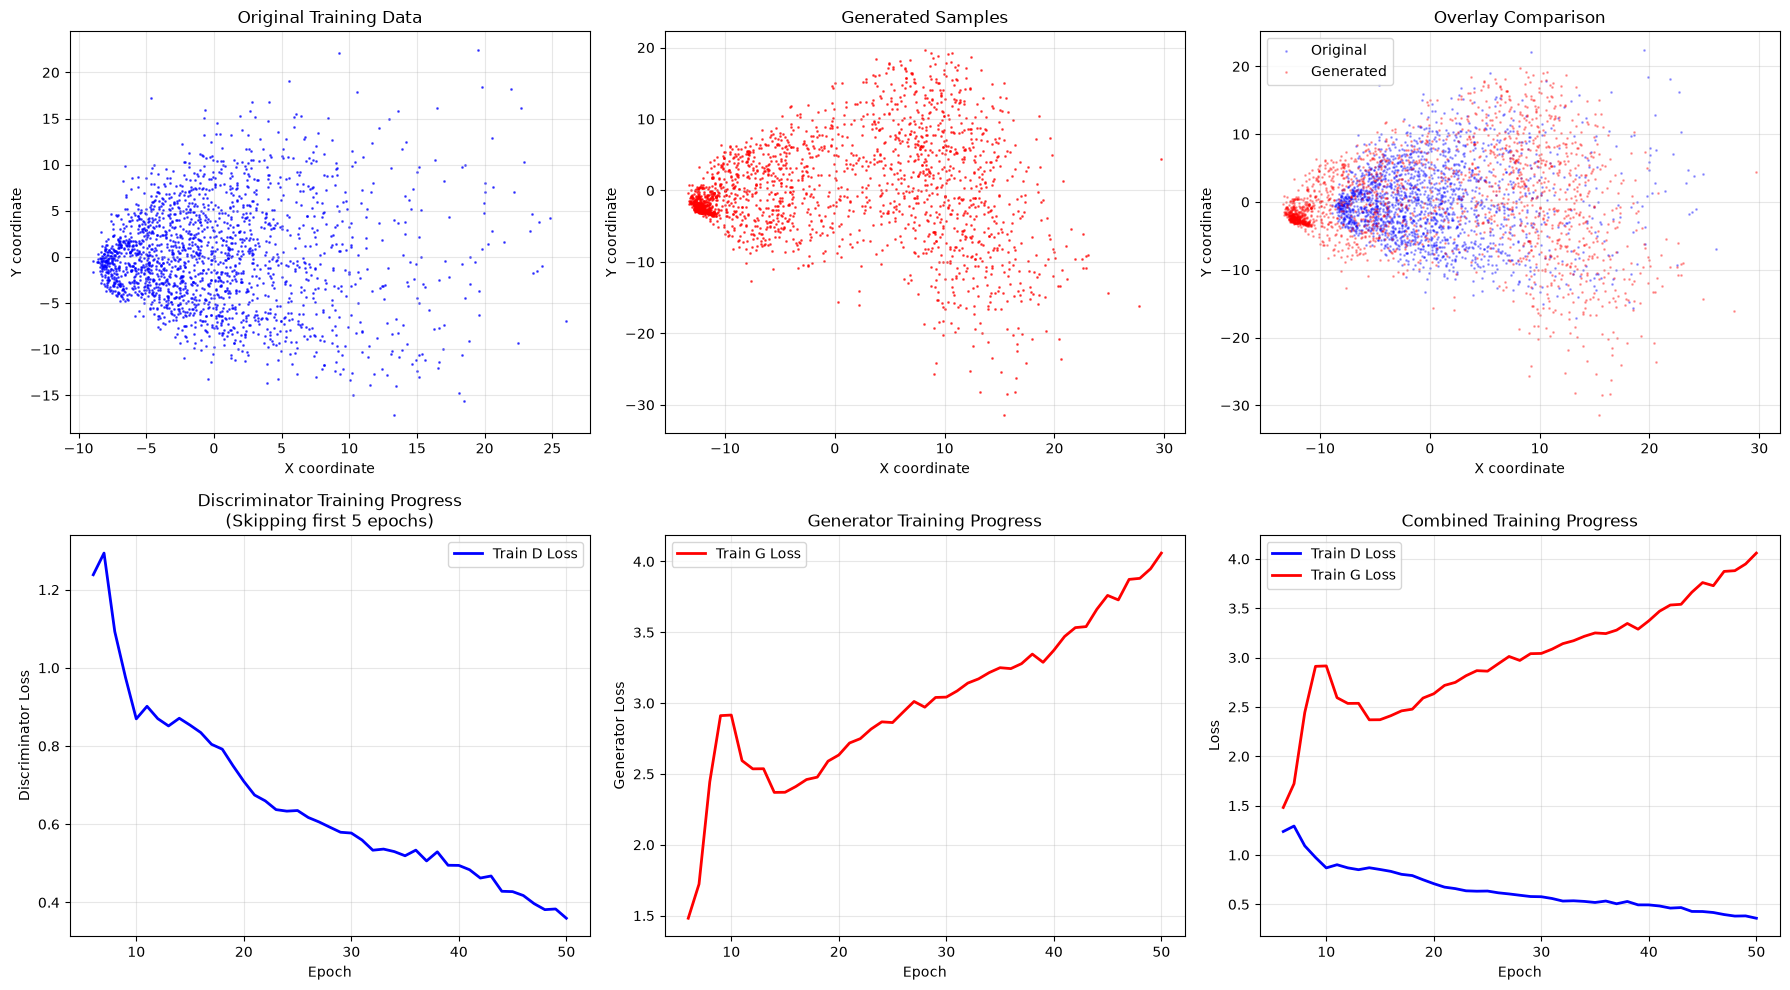

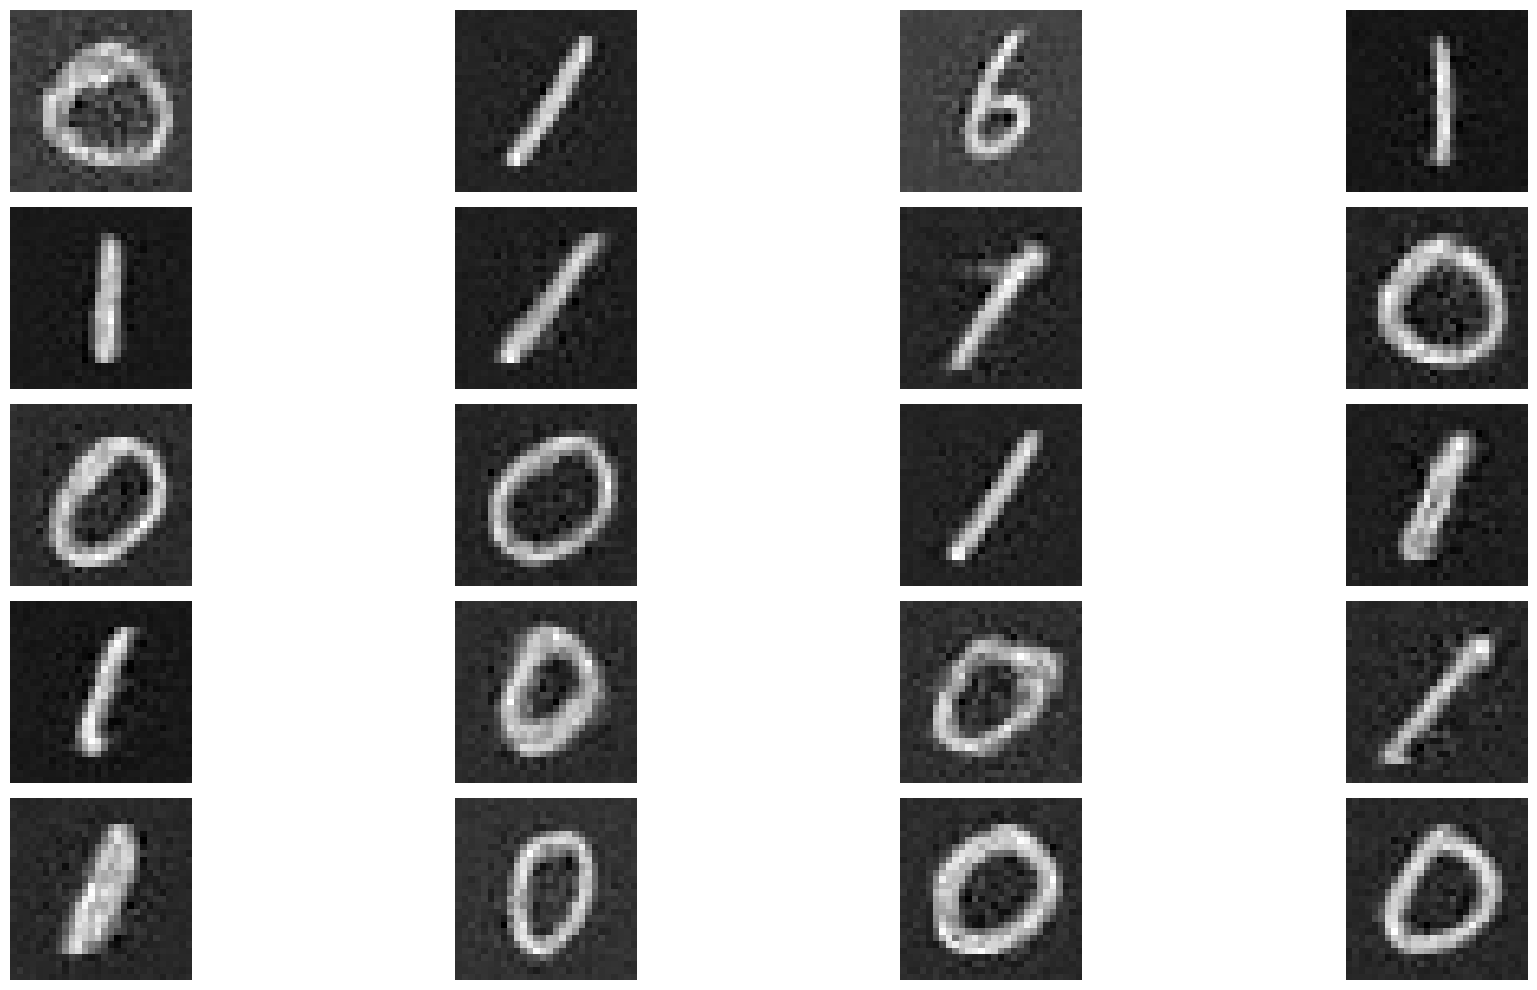

📈 Epoch 50 Summary:
   Train D Loss: 0.3595, Val D Loss: 0.3315
   Train G Loss: 4.0591, Val G Loss: 3.9940

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.198801	G_loss: 4.000638
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.508019	G_loss: 2.735478
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.444849	G_loss: 6.421648
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.324973	G_loss: 3.897388
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.238928	G_loss: 4.977360
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.382682	G_loss: 4.075873
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.281057	G_loss: 3.814729
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.383612	G_loss: 3.360814
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.240505	G_loss: 3.384318
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.274313	G_loss: 4.831130
====> Epoch: 51 Train D_loss: 0.3455, Train G_loss: 4.1047
====> Epoch: 51 Val D_loss: 0.3620, Val G_loss: 2.6709
📈 Epoch 51 Summary:
   Train D Loss: 0.3455, Val D Loss: 0.3620
   Train G Loss: 4.1047

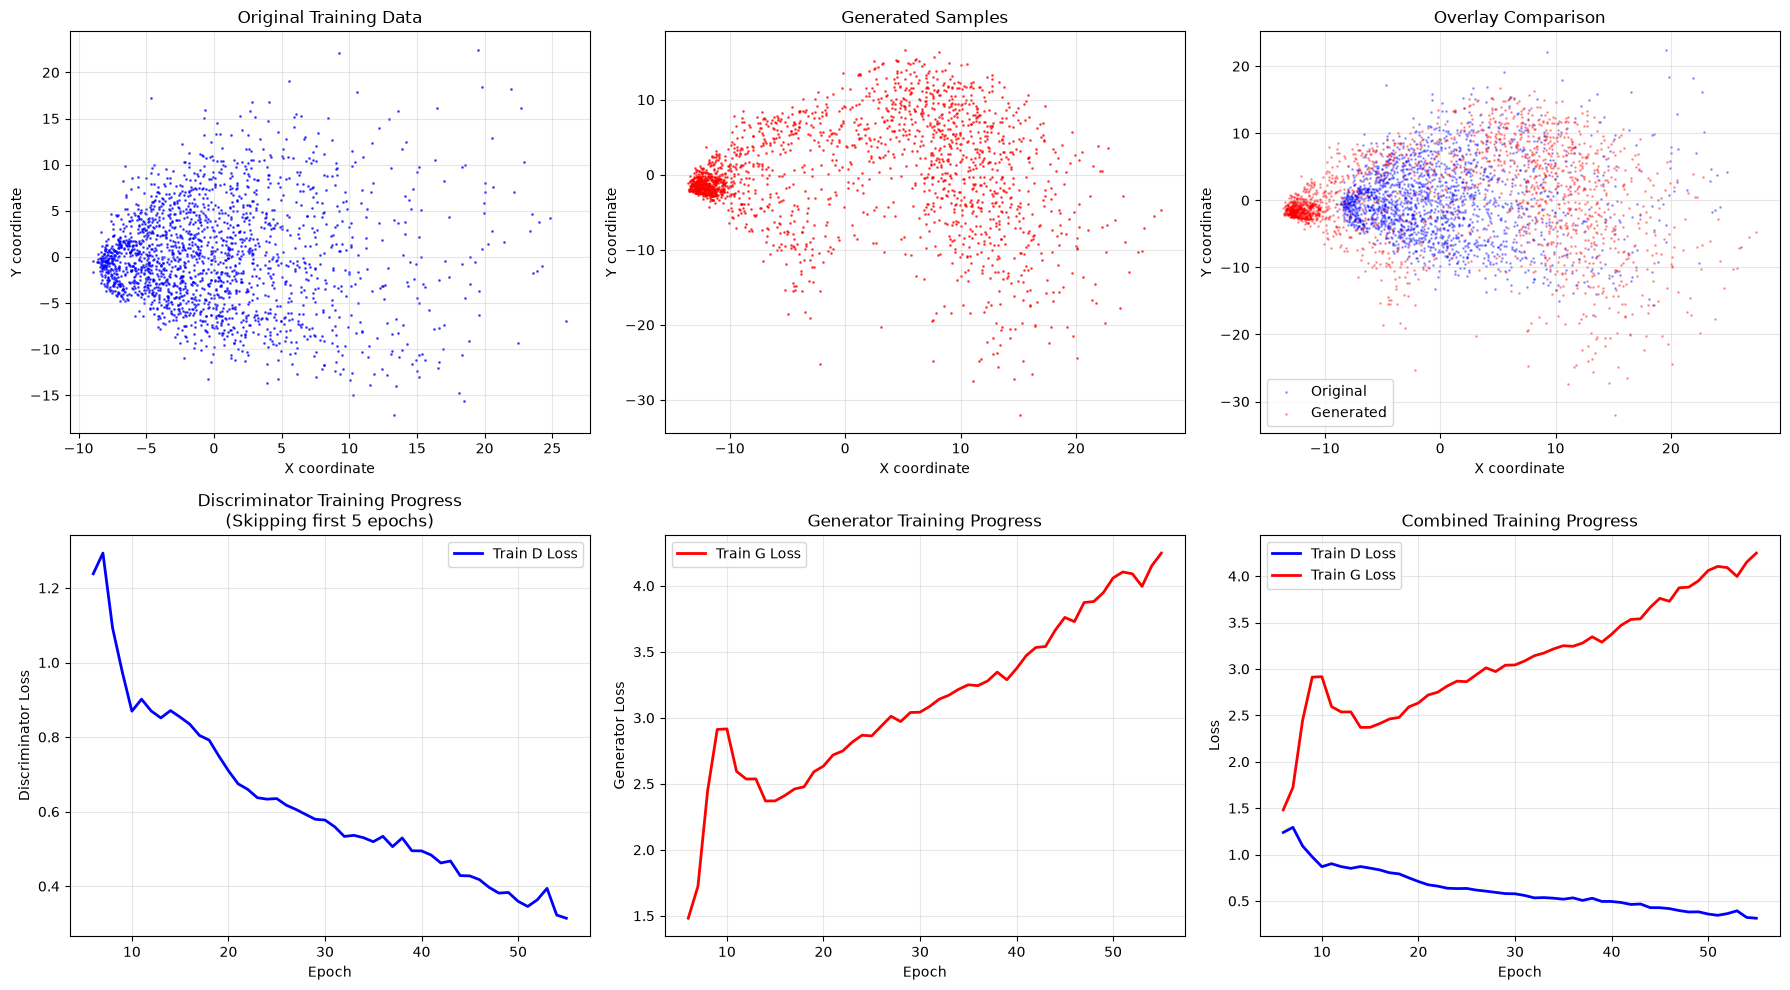

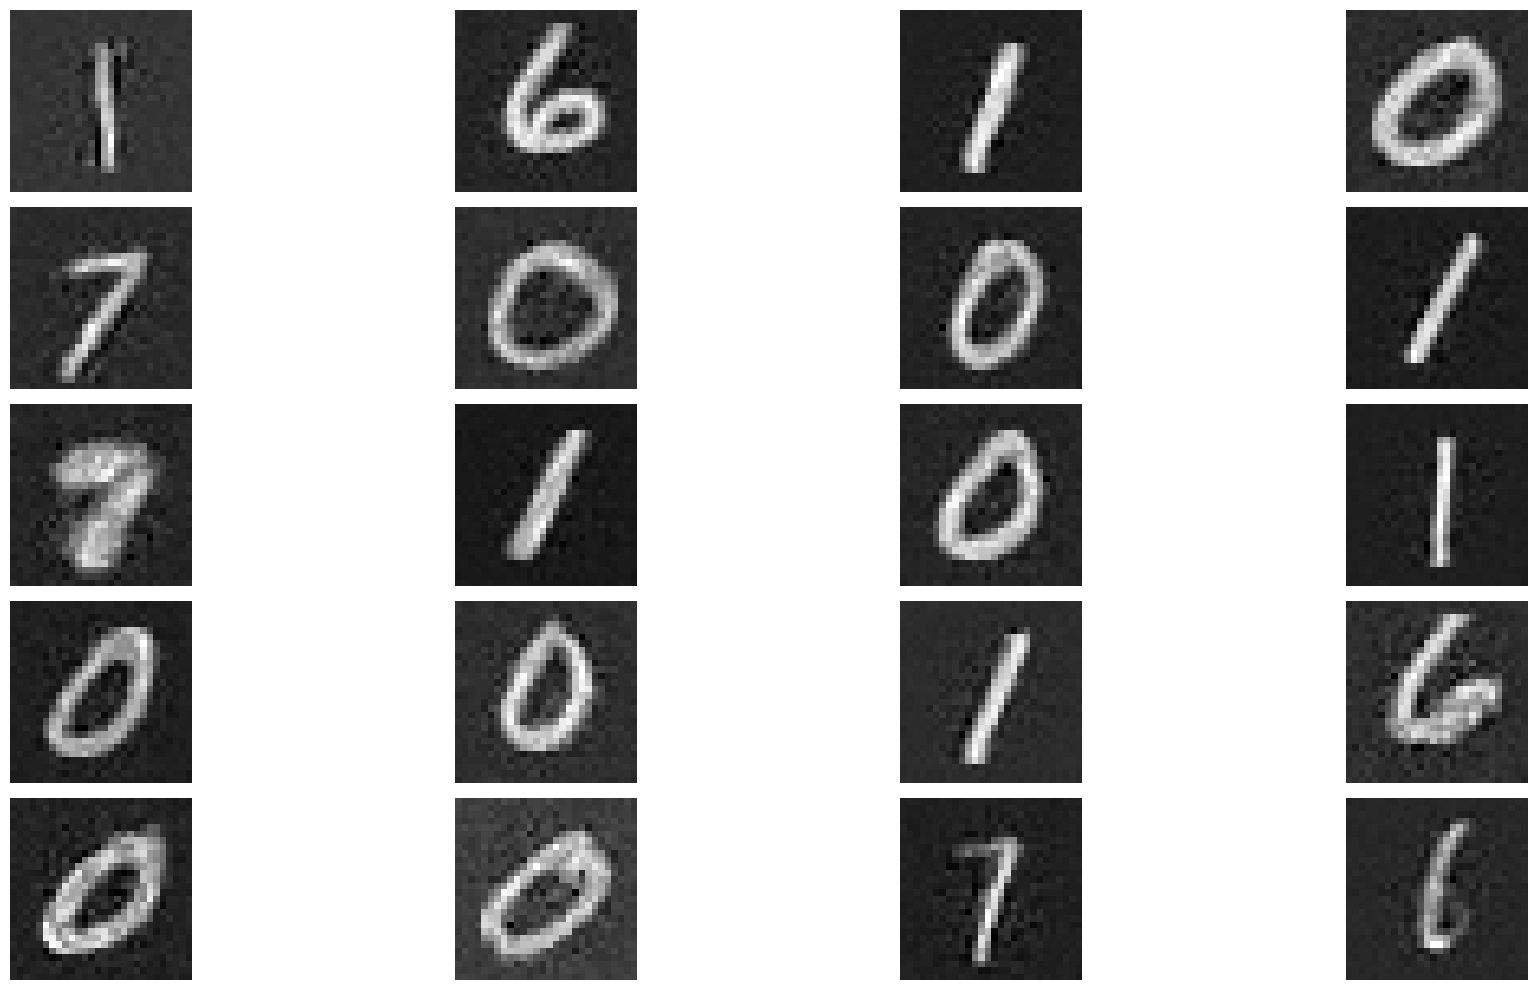

📈 Epoch 55 Summary:
   Train D Loss: 0.3140, Val D Loss: 0.3973
   Train G Loss: 4.2478, Val G Loss: 3.4027

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.331932	G_loss: 6.014002
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.256574	G_loss: 3.815800
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.213709	G_loss: 4.886508
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.317873	G_loss: 4.087380
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.291617	G_loss: 6.986131
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.531135	G_loss: 7.264203
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.362972	G_loss: 4.111238
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.366123	G_loss: 4.026091
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.323942	G_loss: 3.671554
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.219643	G_loss: 4.348135
====> Epoch: 56 Train D_loss: 0.3244, Train G_loss: 4.3104
====> Epoch: 56 Val D_loss: 0.2914, Val G_loss: 3.9253
📈 Epoch 56 Summary:
   Train D Loss: 0.3244, Val D Loss: 0.2914
   Train G Loss: 4.3104

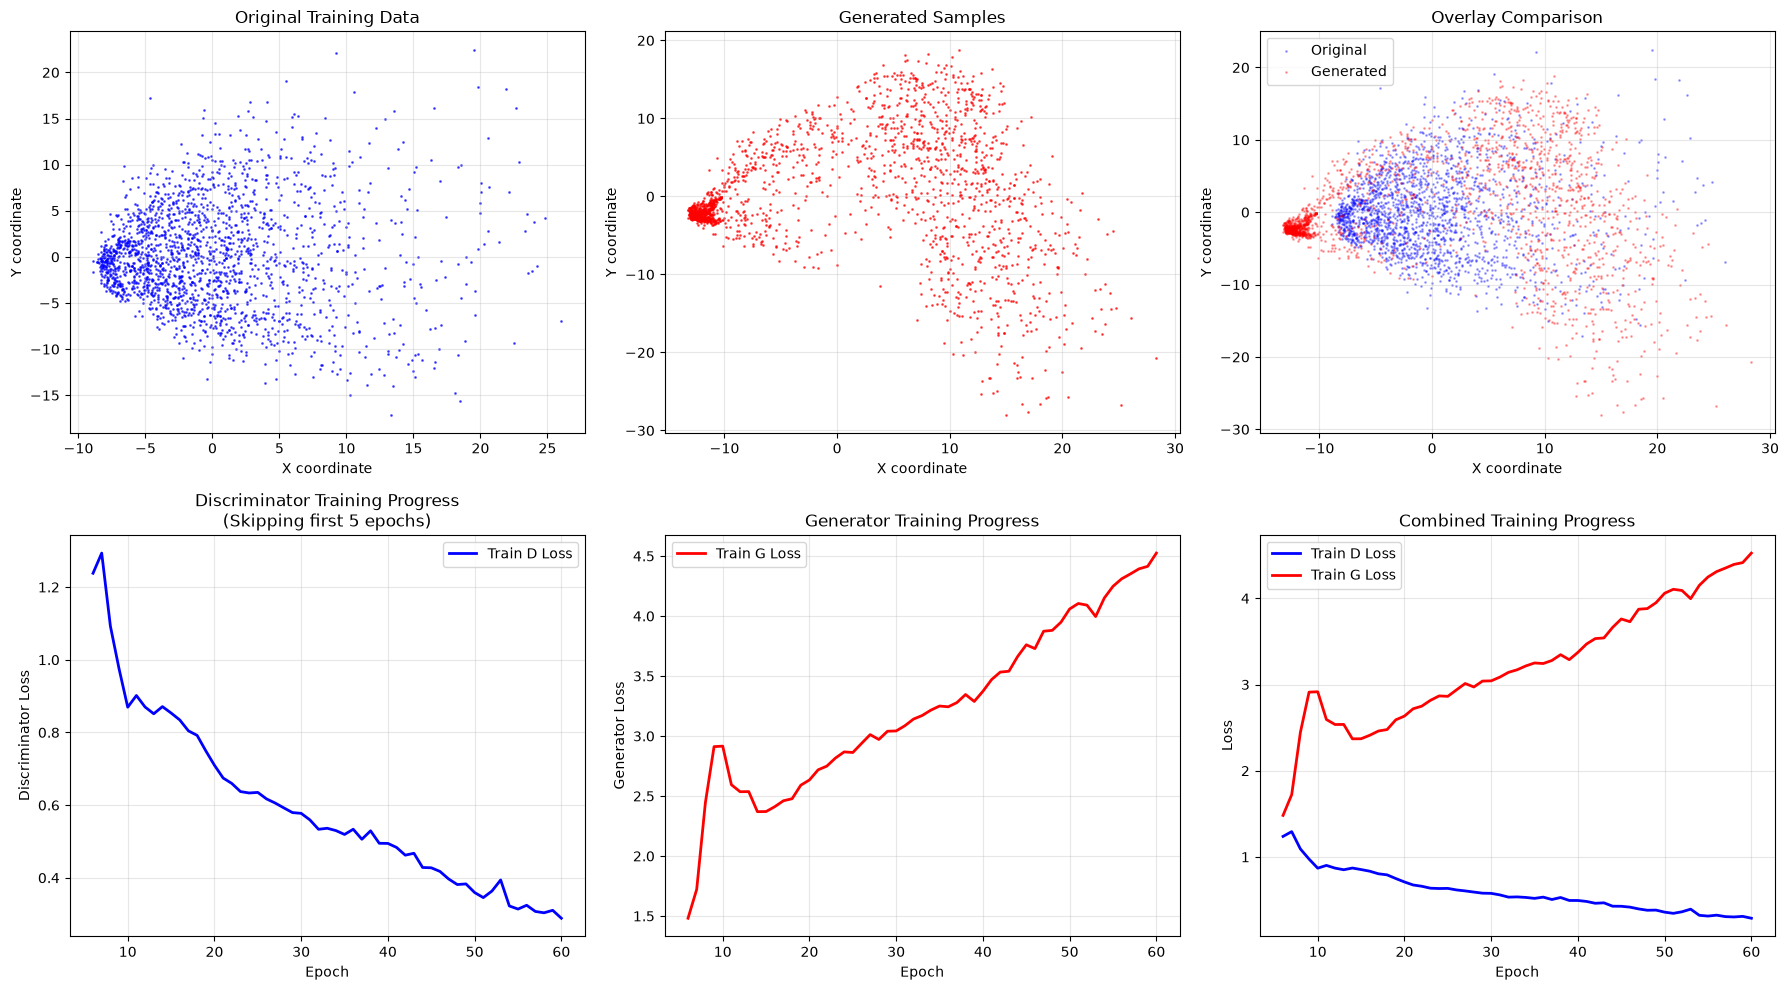

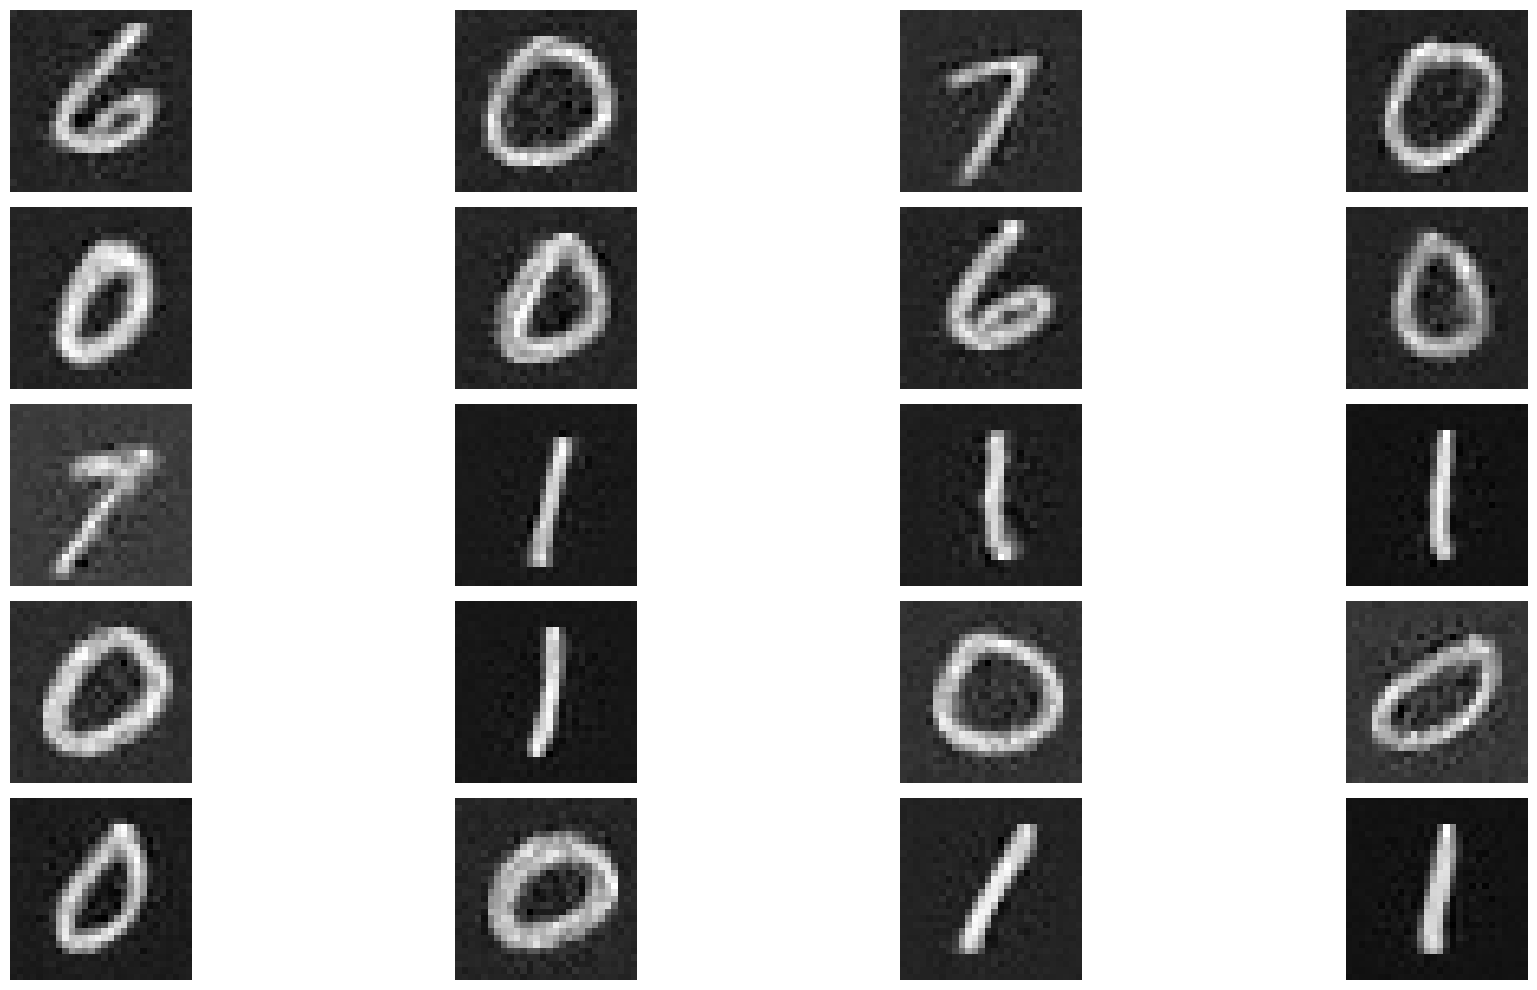

📈 Epoch 60 Summary:
   Train D Loss: 0.2887, Val D Loss: 0.3986
   Train G Loss: 4.5247, Val G Loss: 3.2092

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.302364	G_loss: 4.582546
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.269862	G_loss: 2.861519
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.270844	G_loss: 6.057508
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.305334	G_loss: 4.001434
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.132696	G_loss: 4.111754
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.160201	G_loss: 5.229138
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.261740	G_loss: 5.422080
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.278712	G_loss: 6.088488
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.430807	G_loss: 3.119651
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.217255	G_loss: 3.319913
====> Epoch: 61 Train D_loss: 0.2808, Train G_loss: 4.5665
====> Epoch: 61 Val D_loss: 0.3768, Val G_loss: 5.0085
📈 Epoch 61 Summary:
   Train D Loss: 0.2808, Val D Loss: 0.3768
   Train G Loss: 4.5665

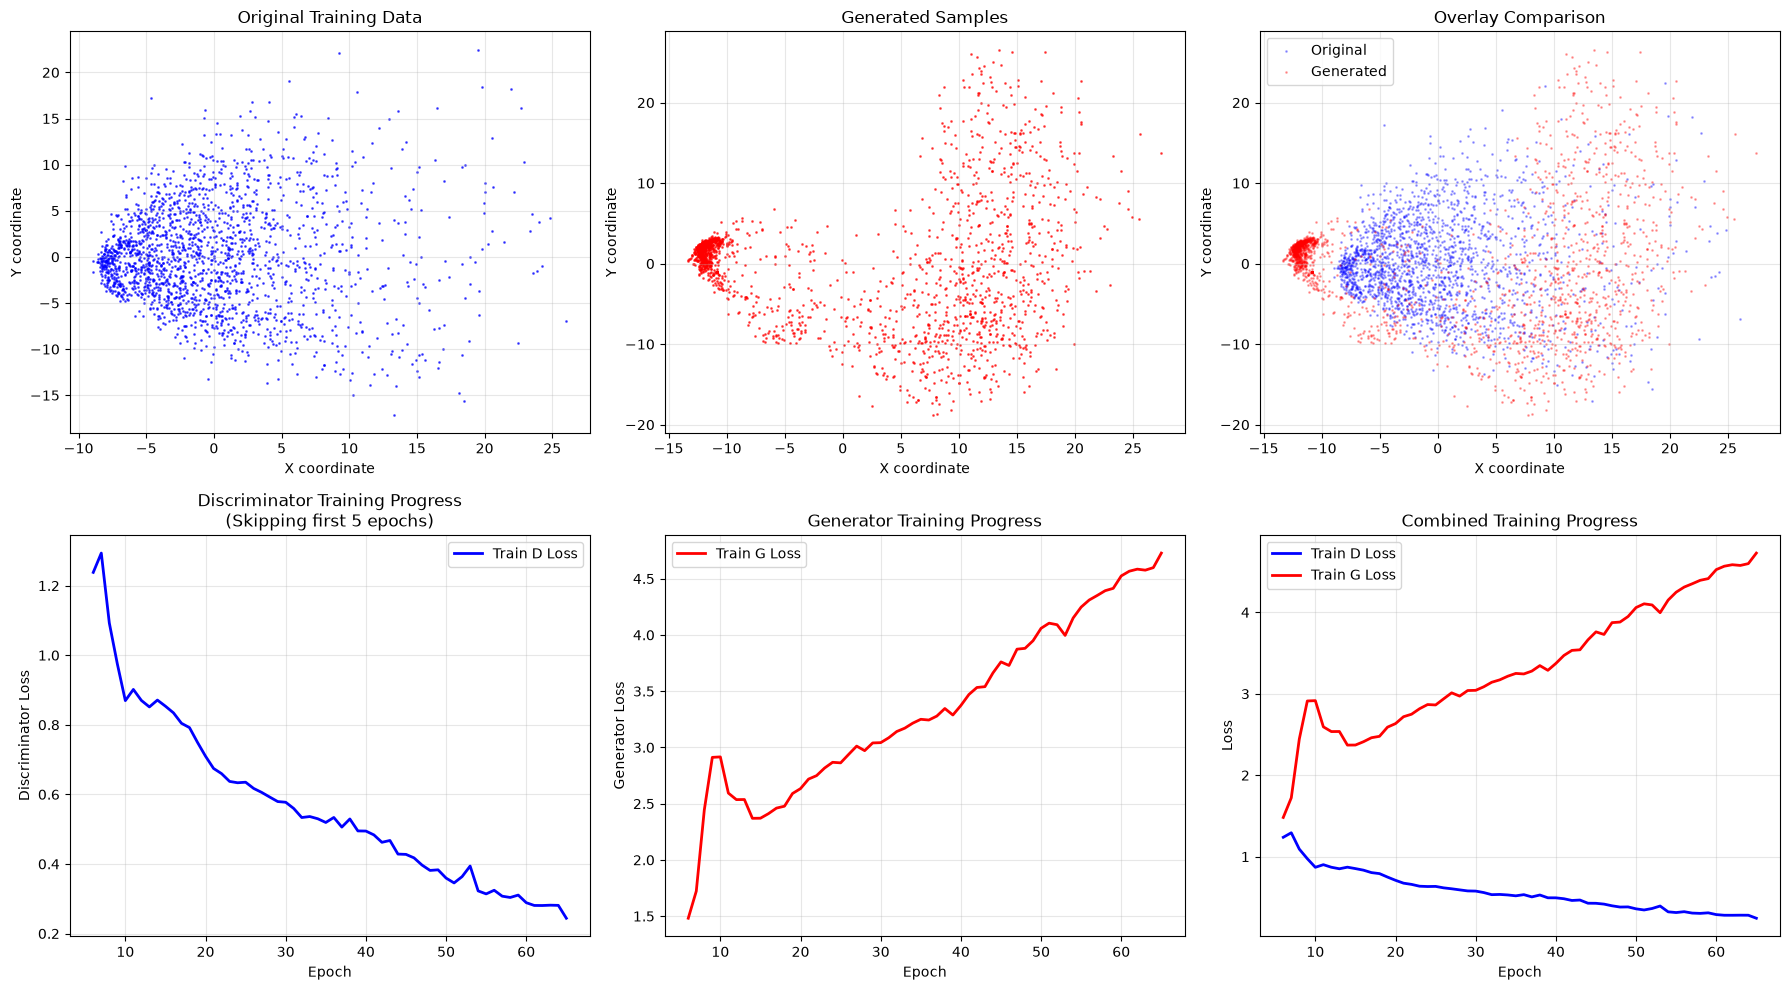

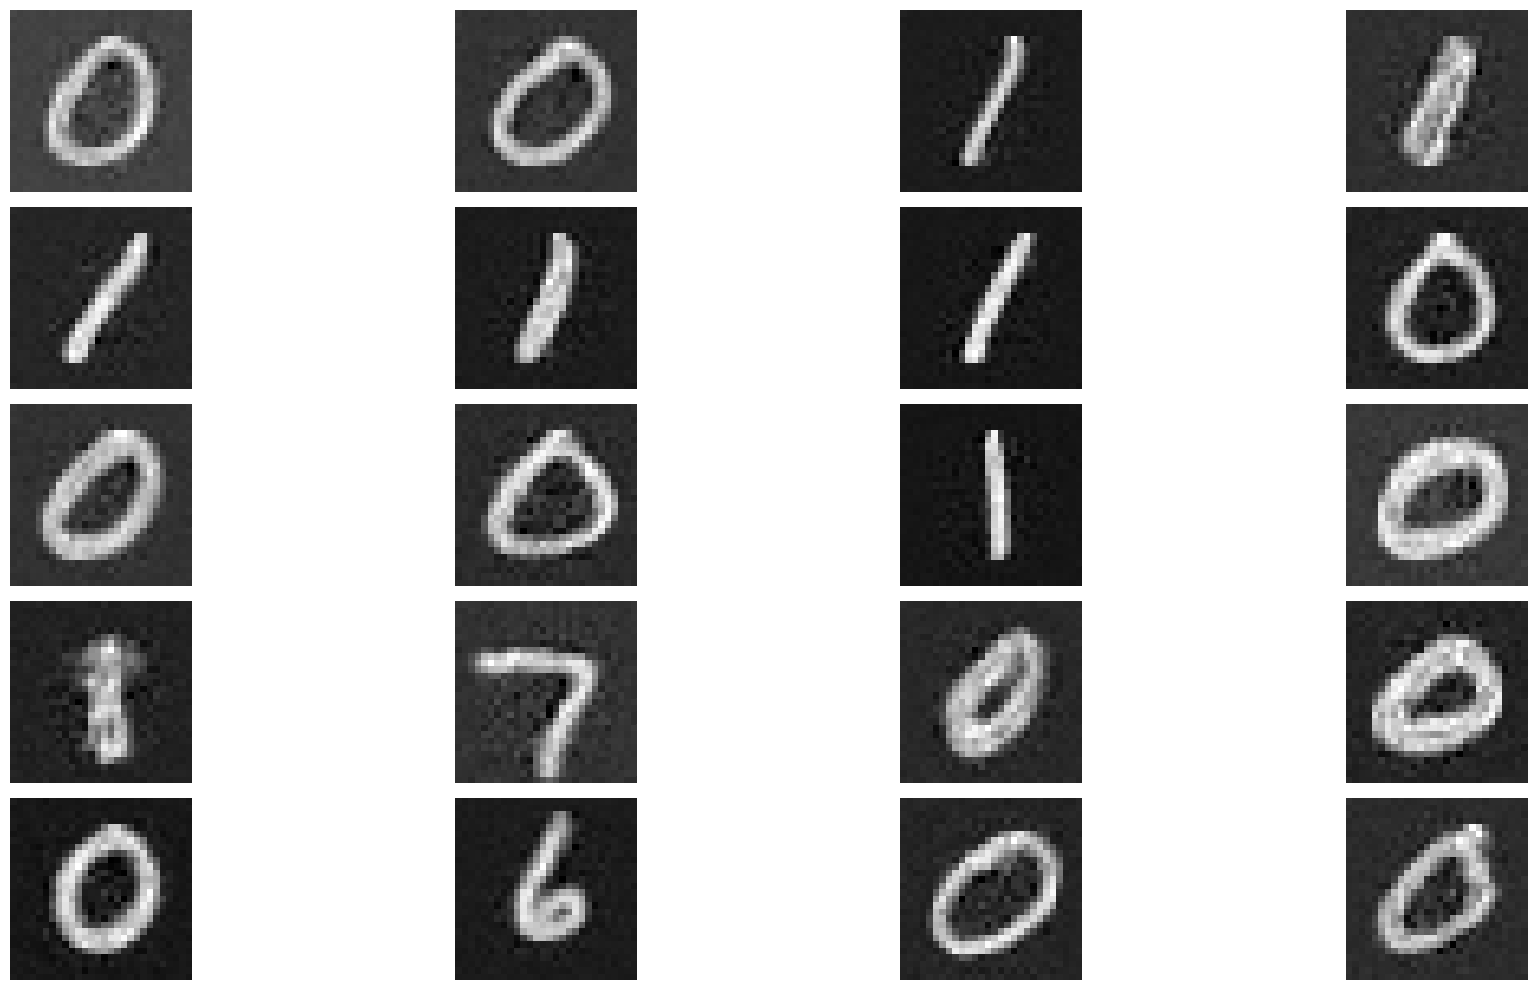

📈 Epoch 65 Summary:
   Train D Loss: 0.2440, Val D Loss: 0.2472
   Train G Loss: 4.7276, Val G Loss: 4.0293

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.234271	G_loss: 3.868676
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.193492	G_loss: 4.843816
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.175103	G_loss: 5.622784
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.264785	G_loss: 6.620292
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.297178	G_loss: 3.344726
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.320240	G_loss: 6.140514
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.169383	G_loss: 5.413641
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.375579	G_loss: 6.885007
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.103617	G_loss: 5.753549
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.202948	G_loss: 4.141003
====> Epoch: 66 Train D_loss: 0.2548, Train G_loss: 4.8104
====> Epoch: 66 Val D_loss: 0.2683, Val G_loss: 3.2406
📈 Epoch 66 Summary:
   Train D Loss: 0.2548, Val D Loss: 0.2683
   Train G Loss: 4.8104

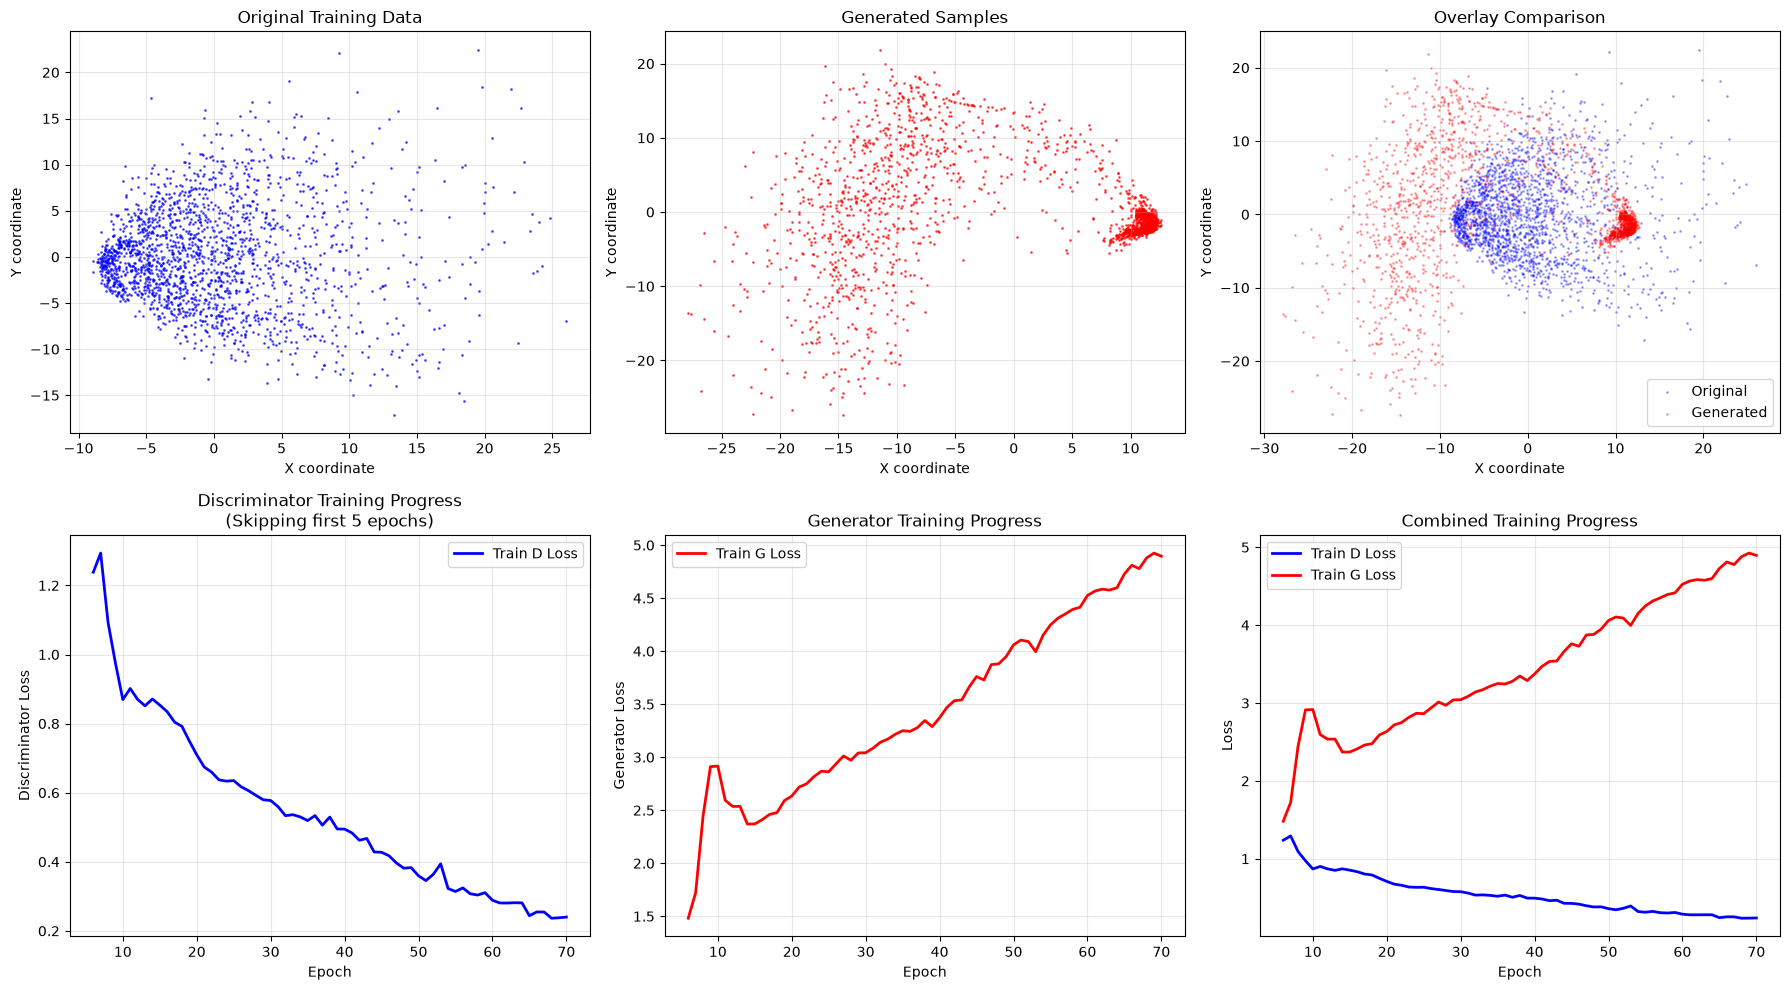

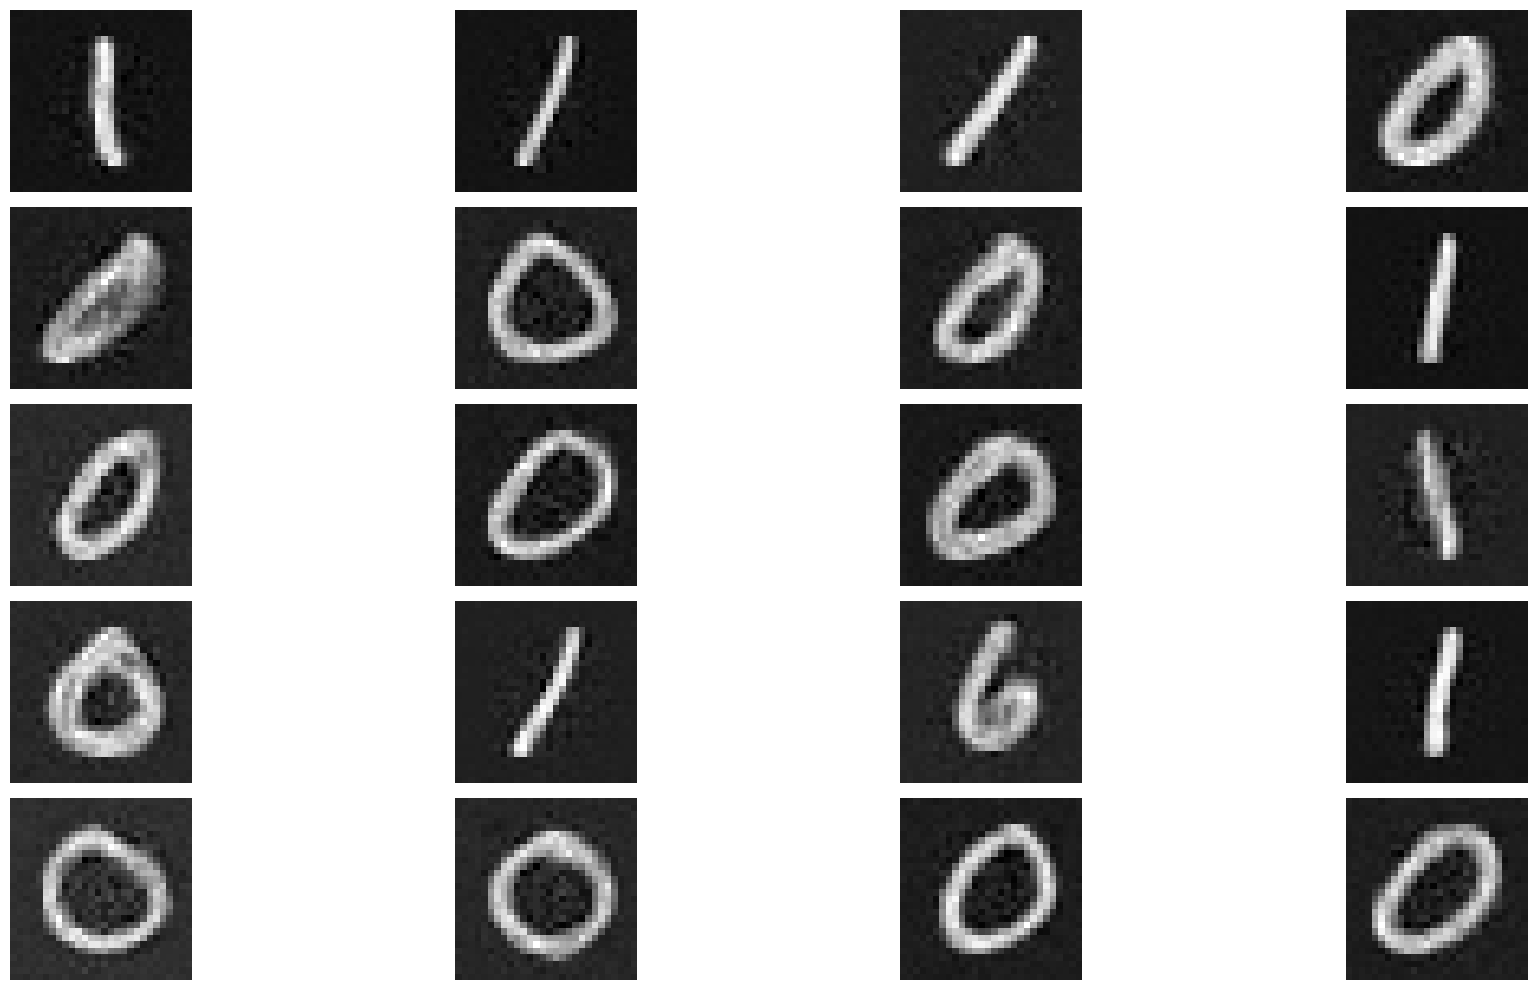

📈 Epoch 70 Summary:
   Train D Loss: 0.2400, Val D Loss: 0.3626
   Train G Loss: 4.8958, Val G Loss: 6.3170

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.234484	G_loss: 5.662482
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.196116	G_loss: 4.618154
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.152864	G_loss: 4.344731
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.166212	G_loss: 4.533202
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.313883	G_loss: 4.675730
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.202803	G_loss: 4.493840
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.239754	G_loss: 5.214562
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.143525	G_loss: 5.293578
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.162278	G_loss: 4.523232
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.166902	G_loss: 4.486984
====> Epoch: 71 Train D_loss: 0.2189, Train G_loss: 5.0382
====> Epoch: 71 Val D_loss: 0.2221, Val G_loss: 4.4160
📈 Epoch 71 Summary:
   Train D Loss: 0.2189, Val D Loss: 0.2221
   Train G Loss: 5.0382

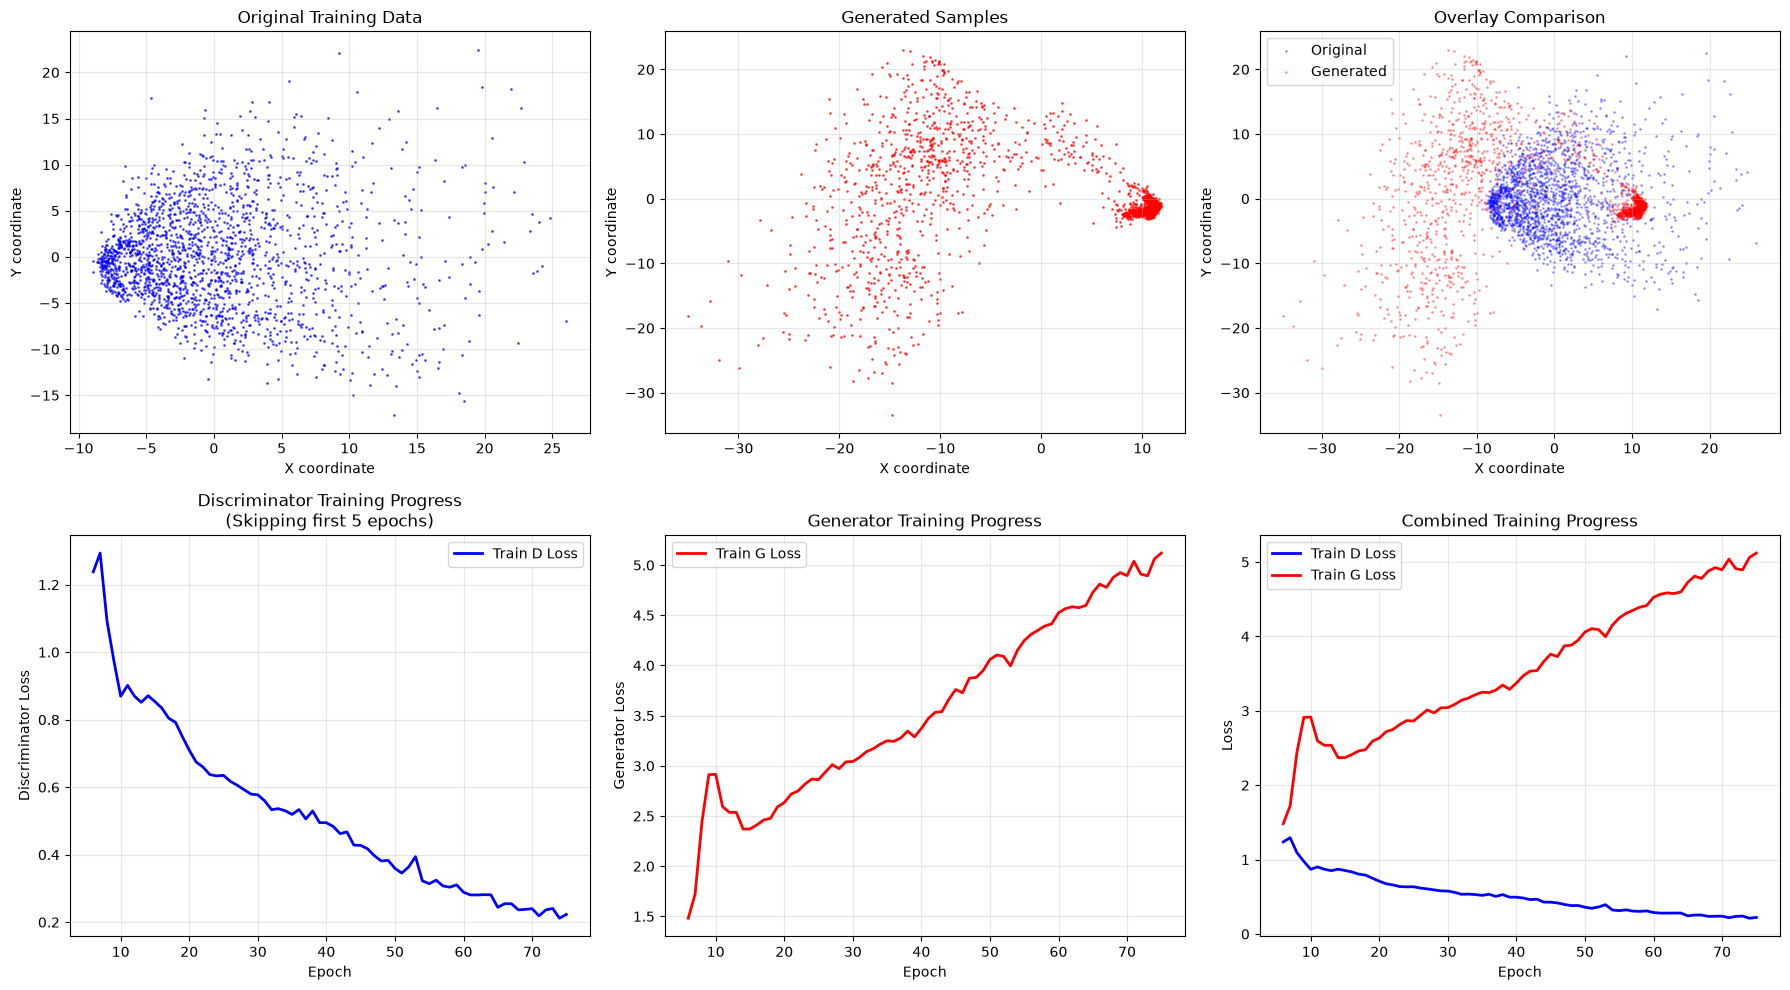

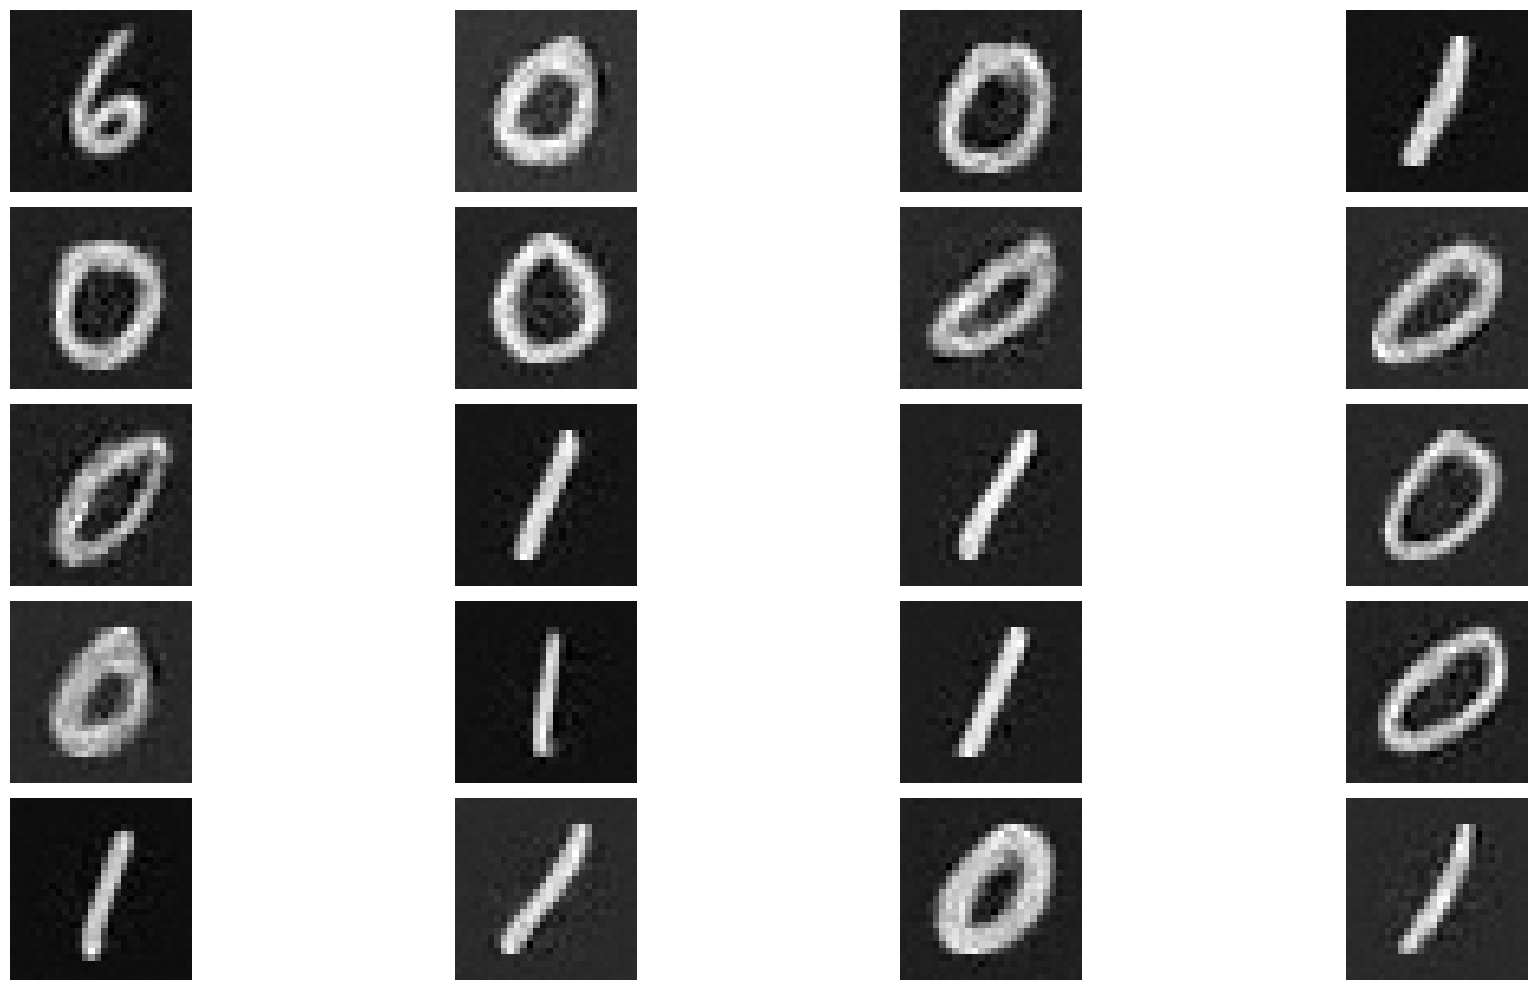

📈 Epoch 75 Summary:
   Train D Loss: 0.2229, Val D Loss: 0.4859
   Train G Loss: 5.1198, Val G Loss: 6.7464

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.298913	G_loss: 6.179543
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.182546	G_loss: 4.191199
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.216830	G_loss: 5.458733
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.276264	G_loss: 4.066671
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.170072	G_loss: 4.974427
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.182783	G_loss: 5.314371
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.216226	G_loss: 4.103254
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.360629	G_loss: 4.357099
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.341391	G_loss: 7.195249
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.249474	G_loss: 4.058587
====> Epoch: 76 Train D_loss: 0.2191, Train G_loss: 5.0693
====> Epoch: 76 Val D_loss: 0.2670, Val G_loss: 3.7779
📈 Epoch 76 Summary:
   Train D Loss: 0.2191, Val D Loss: 0.2670
   Train G Loss: 5.0693

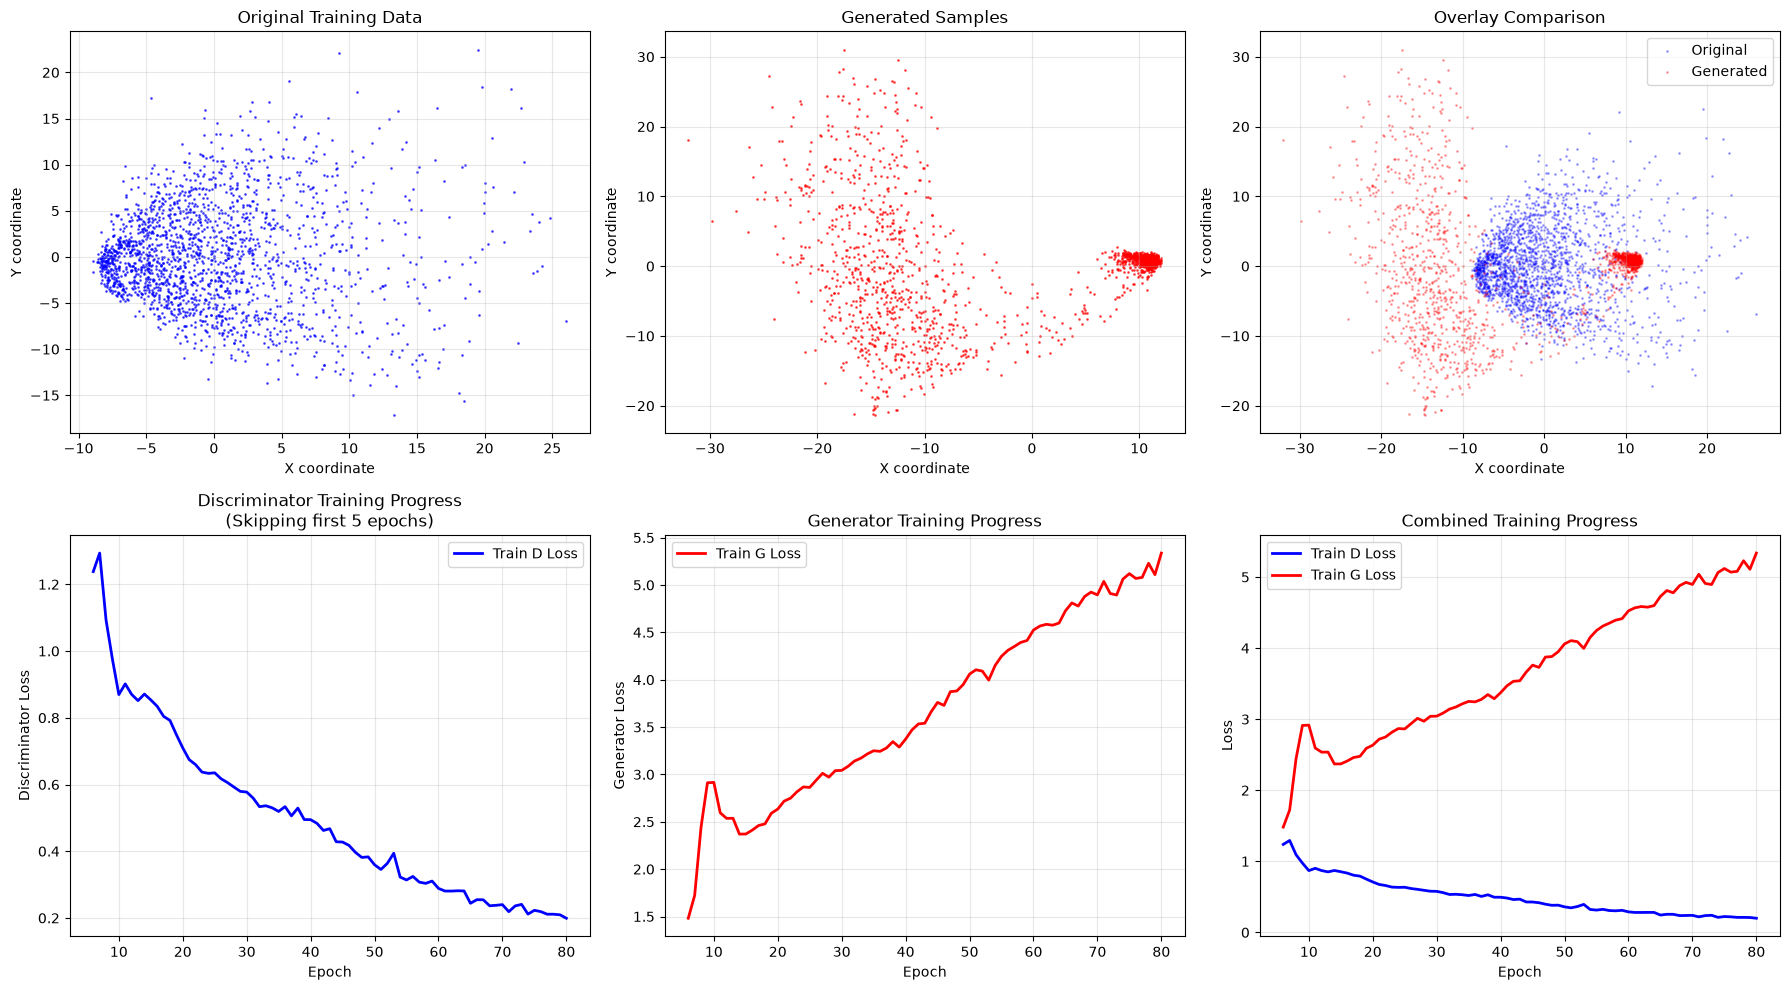

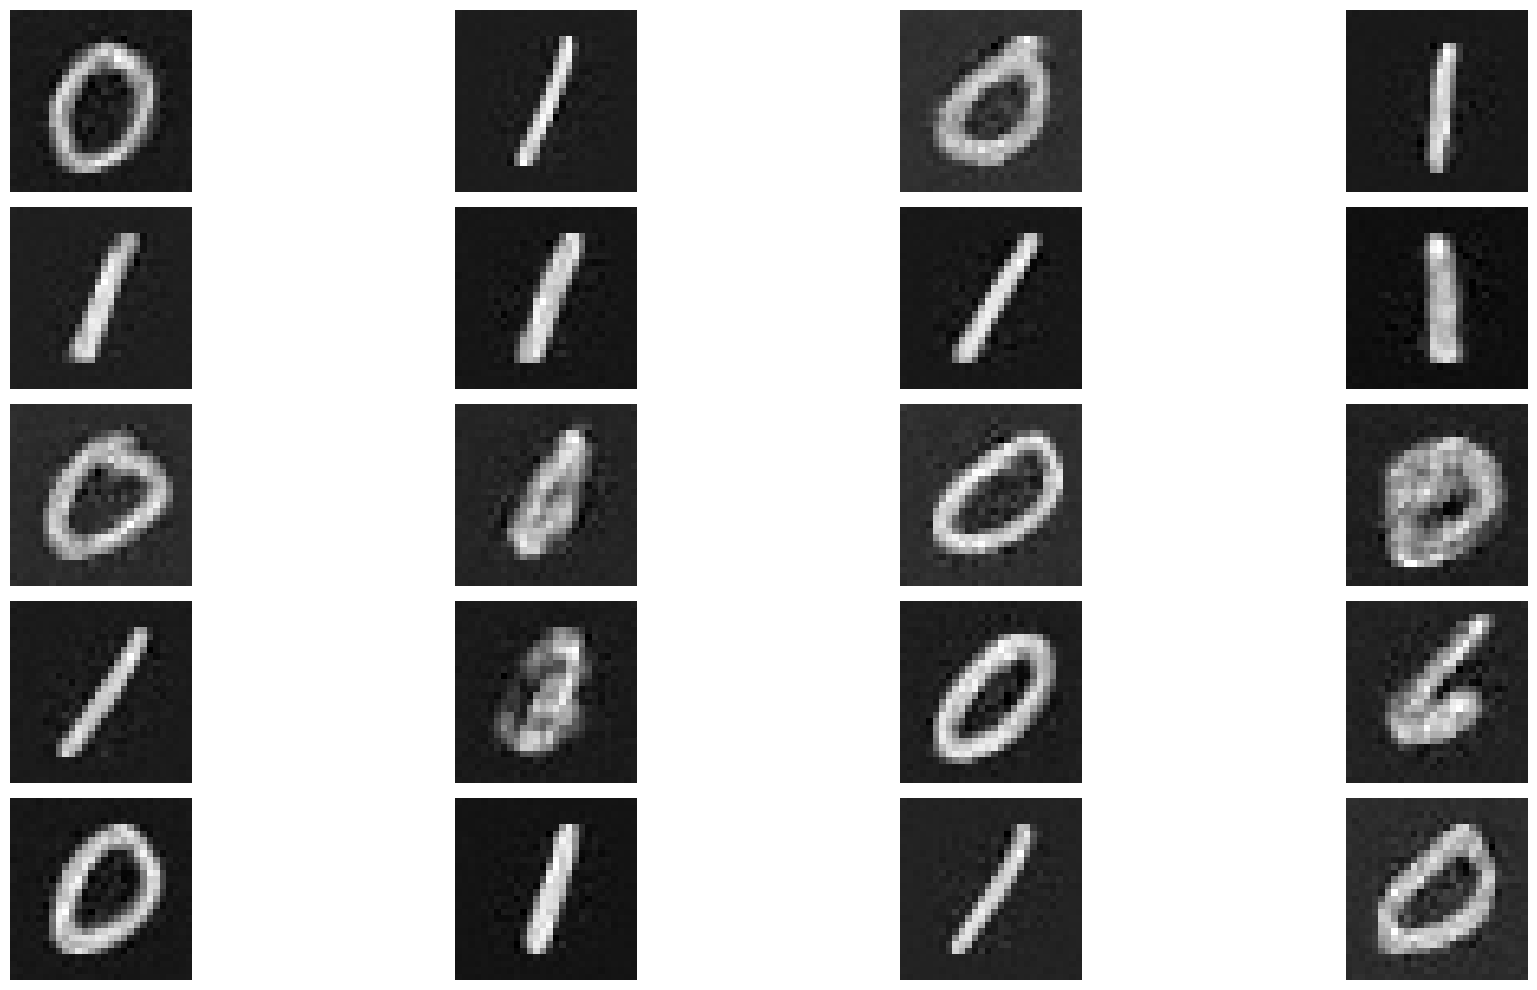

📈 Epoch 80 Summary:
   Train D Loss: 0.1992, Val D Loss: 0.2180
   Train G Loss: 5.3368, Val G Loss: 5.2037

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.131159	G_loss: 5.236883
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.122658	G_loss: 5.893031
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.088105	G_loss: 4.894642
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.088552	G_loss: 5.706763
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.160754	G_loss: 4.685173
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.188866	G_loss: 7.480161
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.220873	G_loss: 3.779233
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.243930	G_loss: 5.397037
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.185607	G_loss: 7.394947
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.463974	G_loss: 5.851988
====> Epoch: 81 Train D_loss: 0.1955, Train G_loss: 5.4781
====> Epoch: 81 Val D_loss: 0.2691, Val G_loss: 4.0025
📈 Epoch 81 Summary:
   Train D Loss: 0.1955, Val D Loss: 0.2691
   Train G Loss: 5.4781

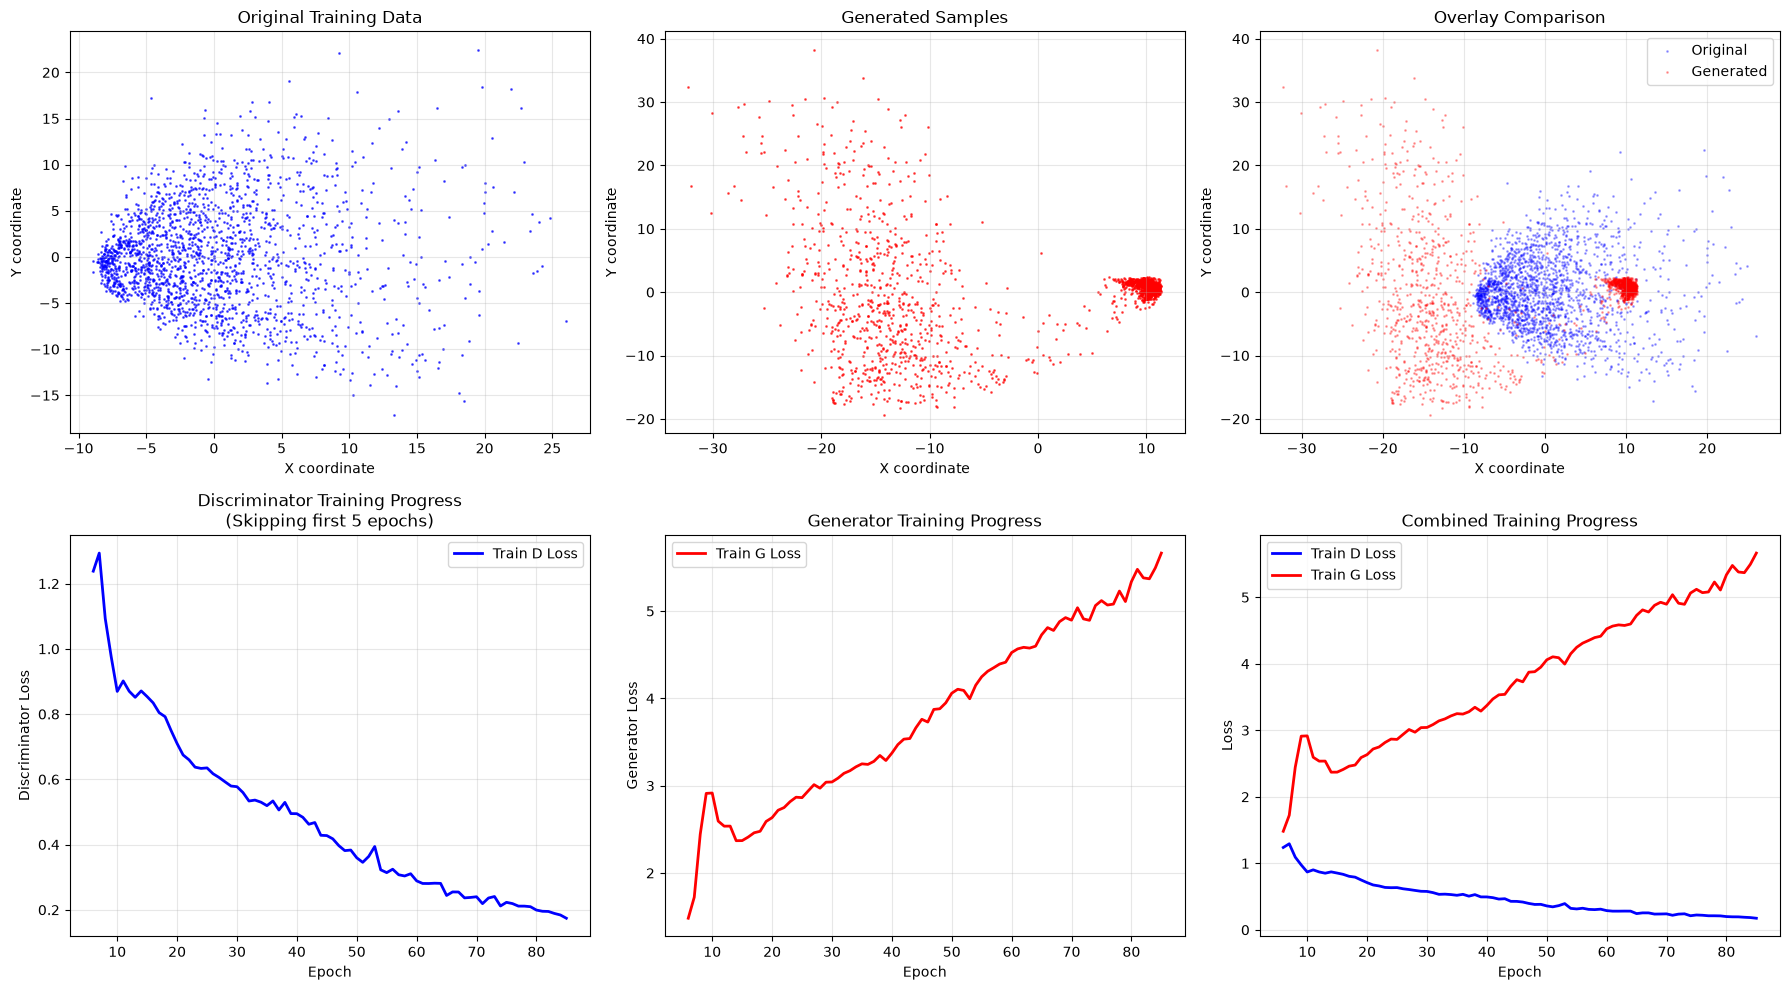

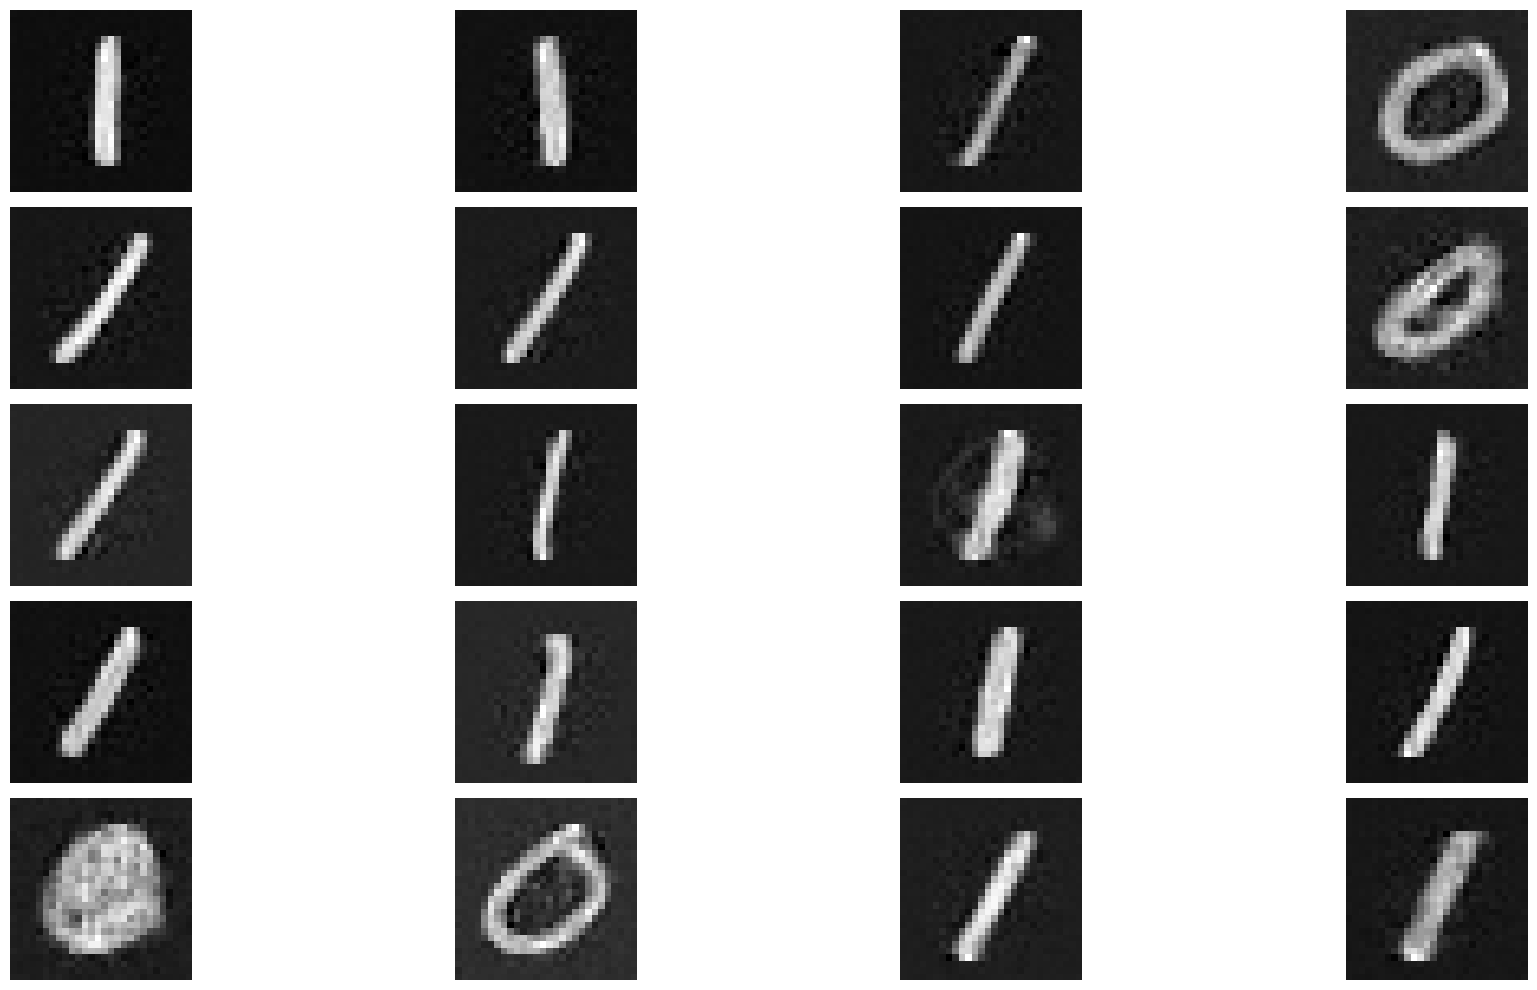

📈 Epoch 85 Summary:
   Train D Loss: 0.1741, Val D Loss: 0.2251
   Train G Loss: 5.6641, Val G Loss: 5.5262

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.138420	G_loss: 8.564271
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.197955	G_loss: 5.024151
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.113144	G_loss: 5.134770
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.165040	G_loss: 7.747673
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.184059	G_loss: 7.937556
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.172945	G_loss: 5.976078
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.134354	G_loss: 4.604063
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.339989	G_loss: 7.799405
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.036915	G_loss: 5.846899
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.197134	G_loss: 7.266653
====> Epoch: 86 Train D_loss: 0.1828, Train G_loss: 5.5754
====> Epoch: 86 Val D_loss: 0.1710, Val G_loss: 5.3094
📈 Epoch 86 Summary:
   Train D Loss: 0.1828, Val D Loss: 0.1710
   Train G Loss: 5.5754

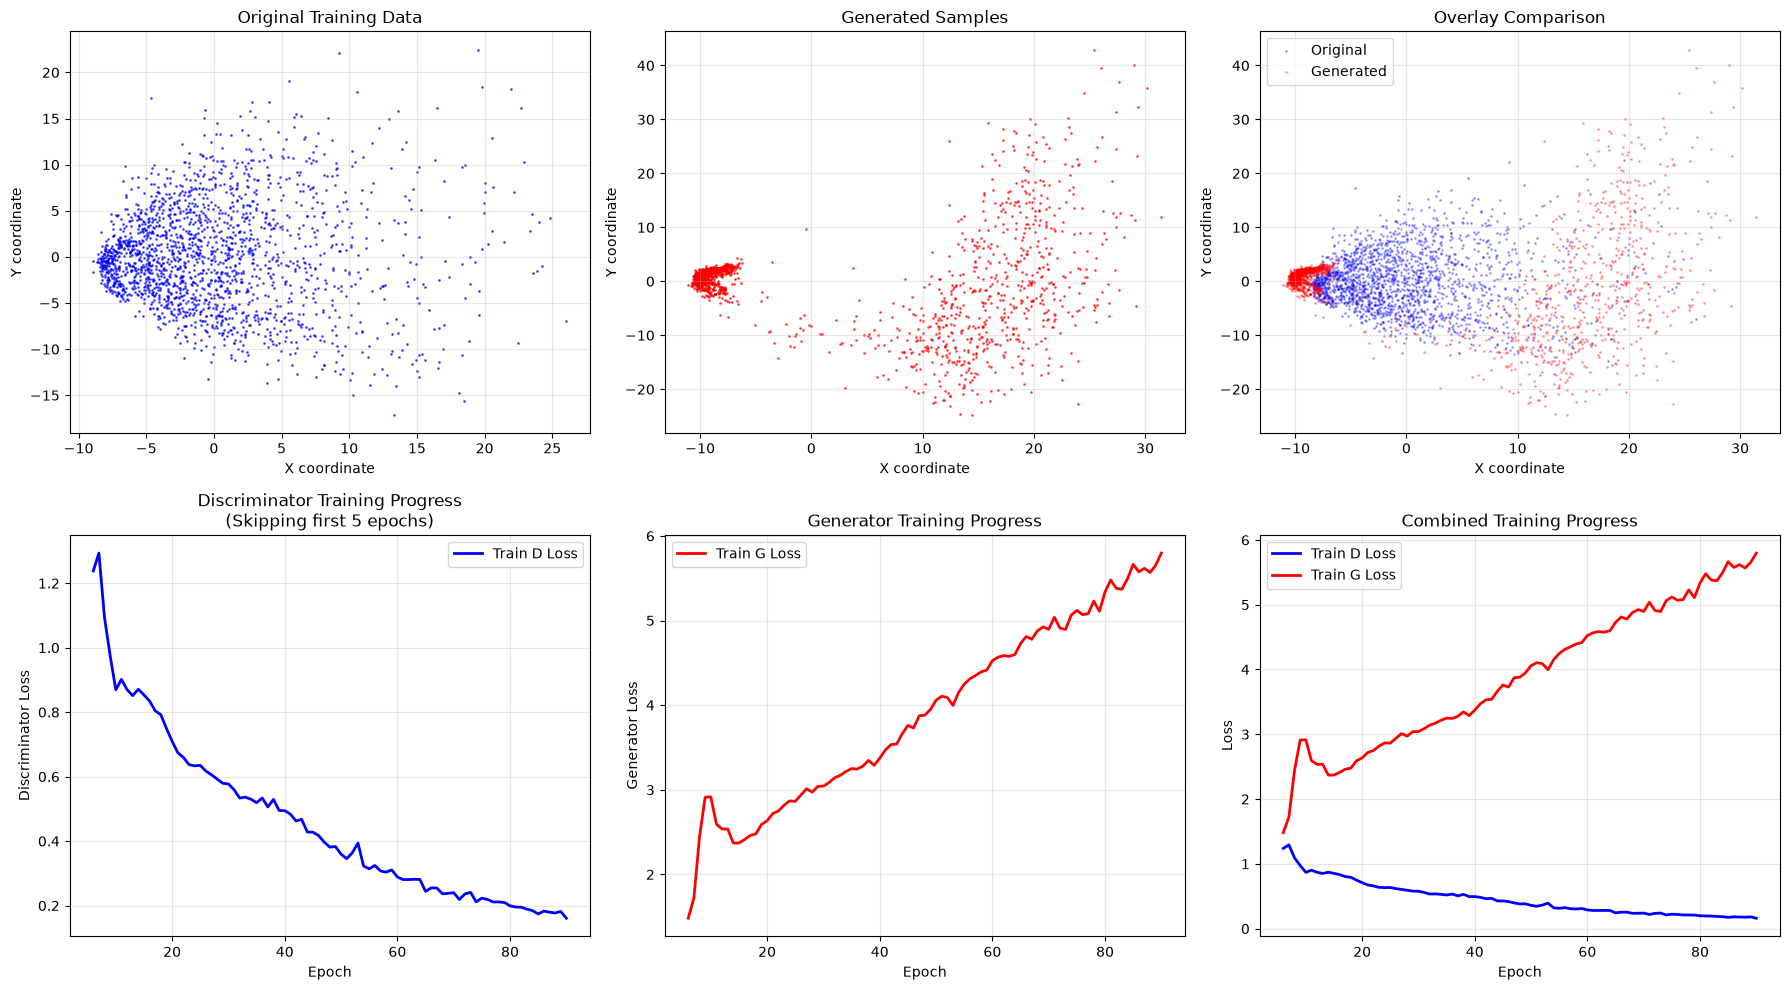

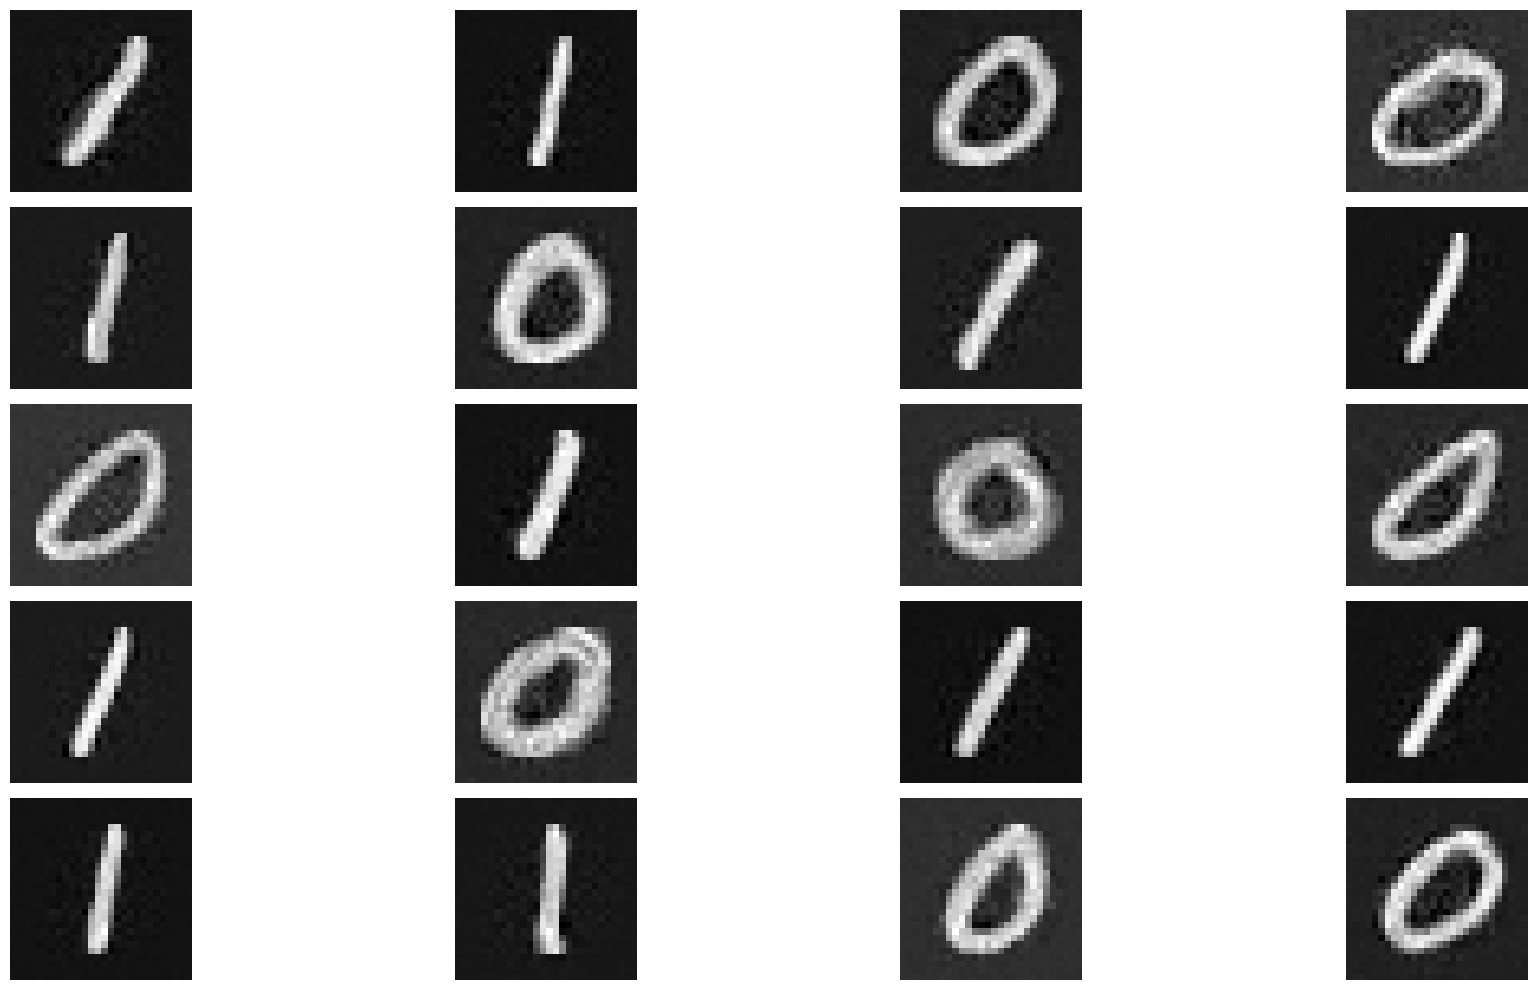

📈 Epoch 90 Summary:
   Train D Loss: 0.1607, Val D Loss: 0.1978
   Train G Loss: 5.7966, Val G Loss: 3.9325

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.218248	G_loss: 7.354915
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.110576	G_loss: 5.180851
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.108752	G_loss: 5.022382
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.170450	G_loss: 5.850808
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.166598	G_loss: 6.666985
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.192912	G_loss: 6.206821
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.103013	G_loss: 7.139325
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.336385	G_loss: 5.383811
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.073729	G_loss: 5.464802
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.204876	G_loss: 4.372077
====> Epoch: 91 Train D_loss: 0.1675, Train G_loss: 5.8996
====> Epoch: 91 Val D_loss: 0.2726, Val G_loss: 4.0094
📈 Epoch 91 Summary:
   Train D Loss: 0.1675, Val D Loss: 0.2726
   Train G Loss: 5.8996

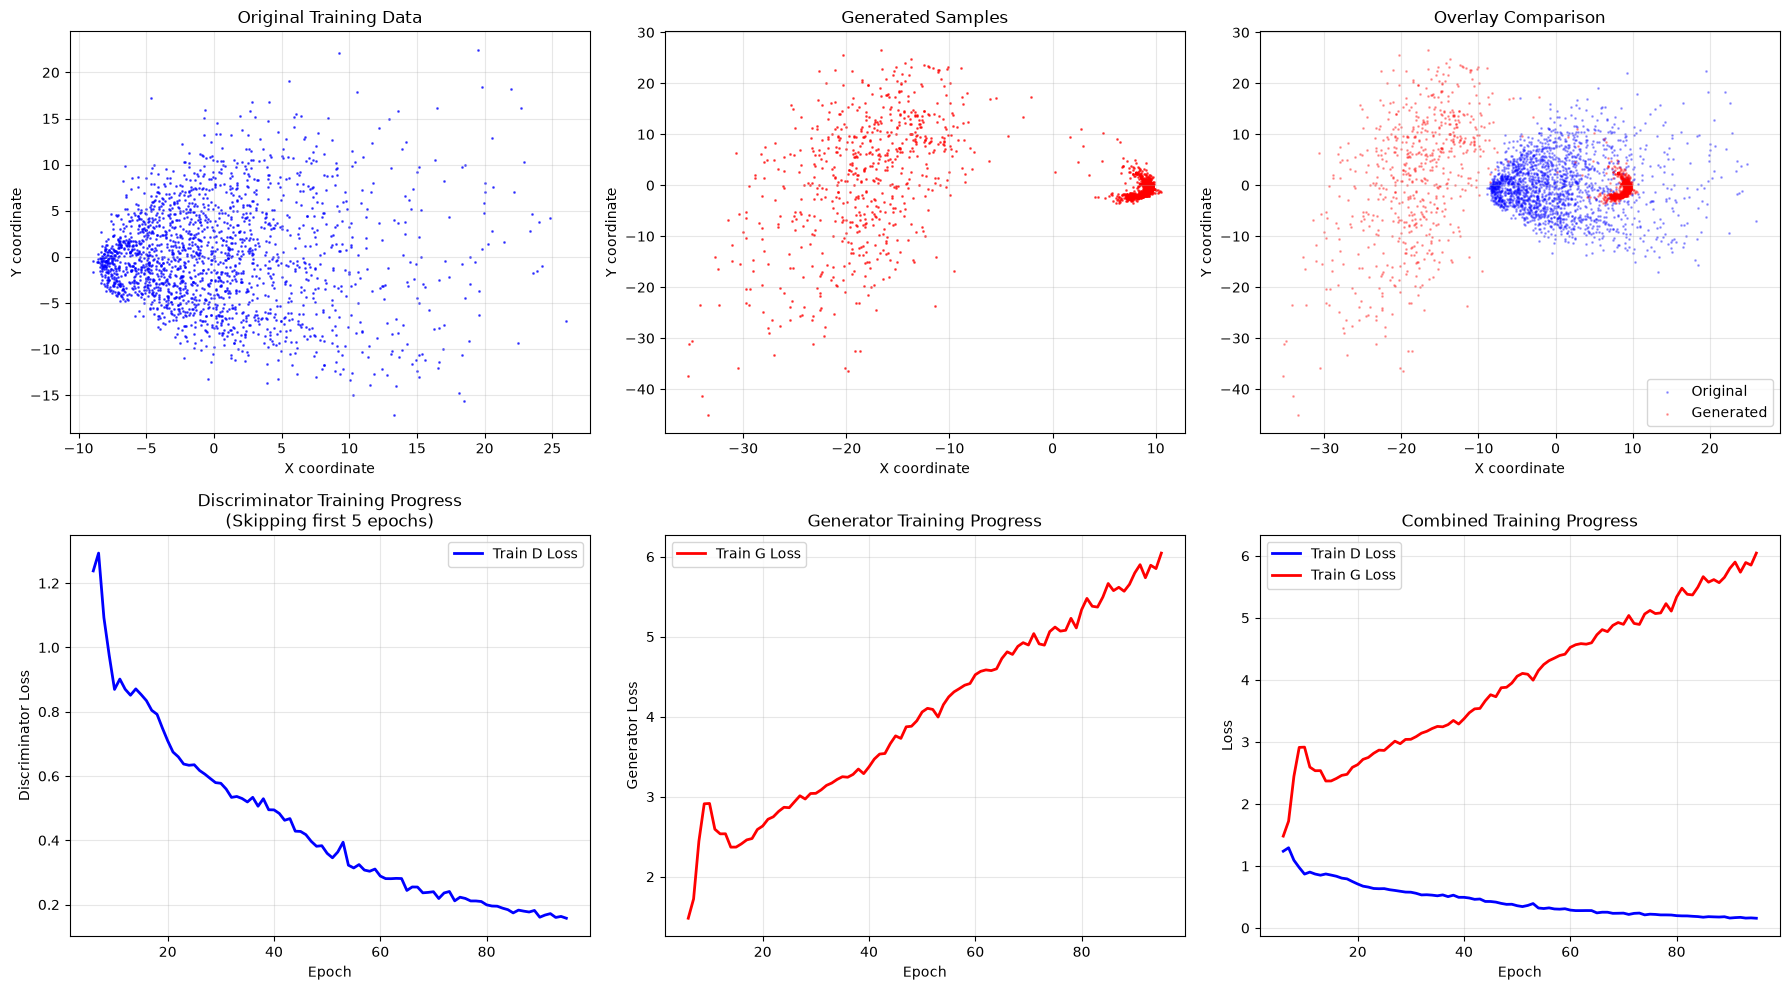

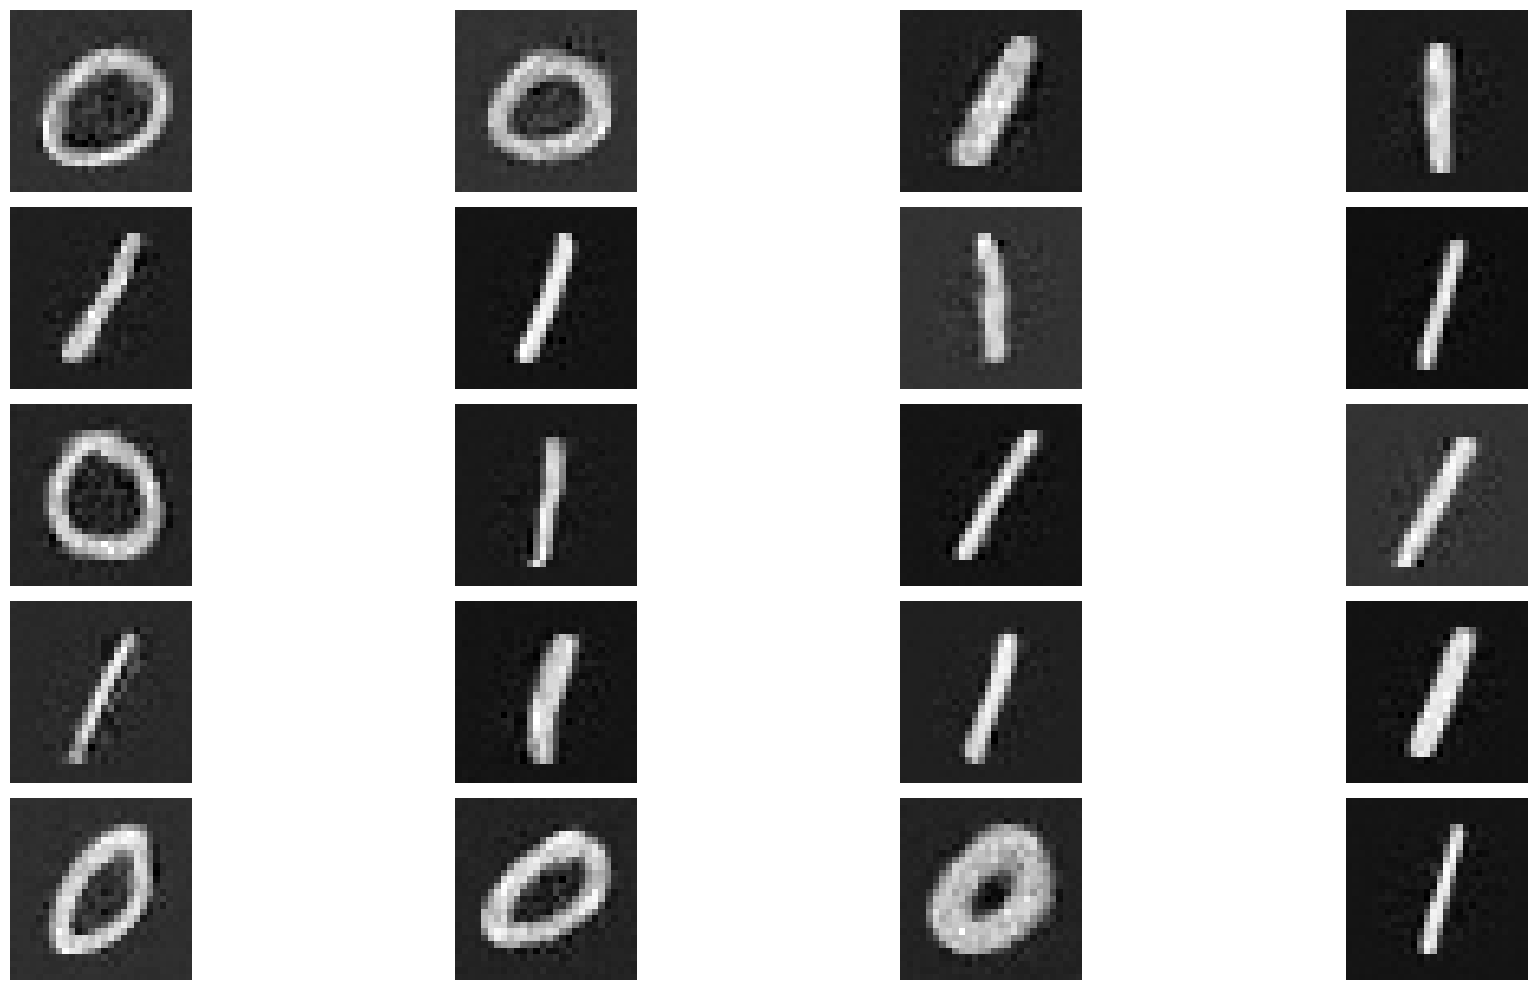

📈 Epoch 95 Summary:
   Train D Loss: 0.1575, Val D Loss: 0.2113
   Train G Loss: 6.0443, Val G Loss: 3.8973

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.210533	G_loss: 4.845013
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.066680	G_loss: 5.992237
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.140626	G_loss: 5.957959
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.063744	G_loss: 5.845795
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.108571	G_loss: 4.749249
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.073231	G_loss: 6.726703
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.213036	G_loss: 6.381646
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.162662	G_loss: 7.348371
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.041555	G_loss: 6.079360
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.105012	G_loss: 4.647790
====> Epoch: 96 Train D_loss: 0.1506, Train G_loss: 6.1273
====> Epoch: 96 Val D_loss: 0.2120, Val G_loss: 6.0762
📈 Epoch 96 Summary:
   Train D Loss: 0.1506, Val D Loss: 0.2120
   Train G Loss: 6.1273

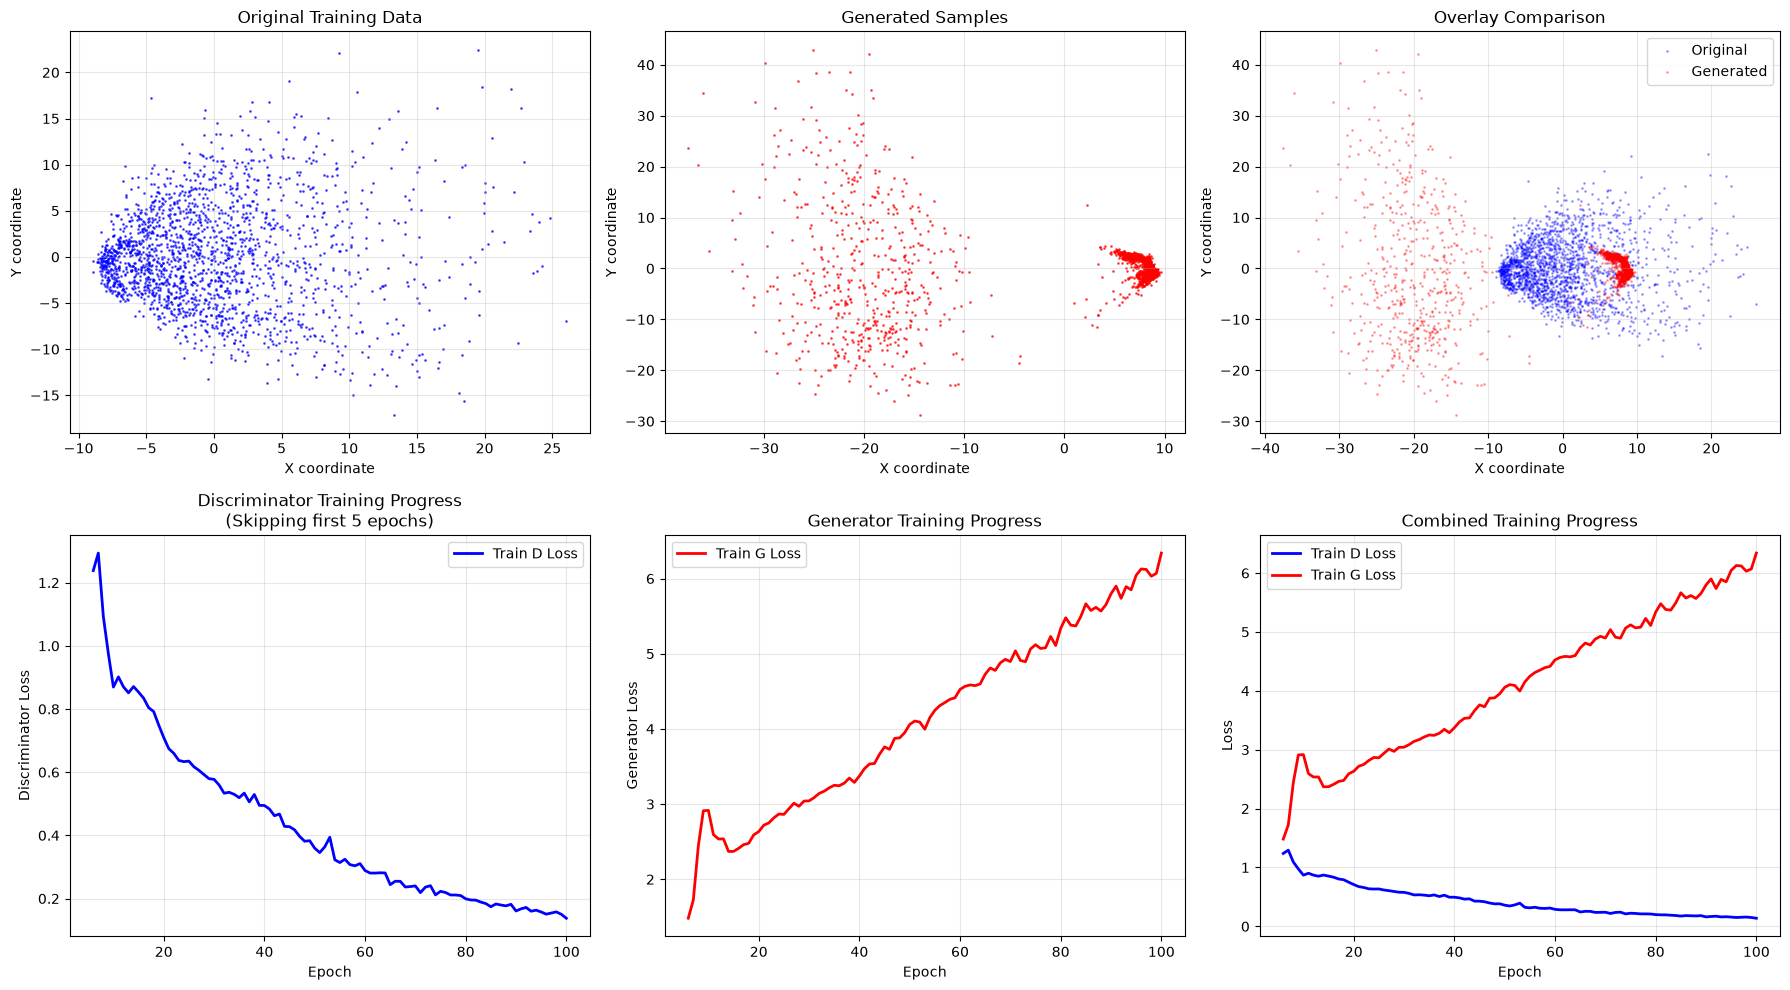

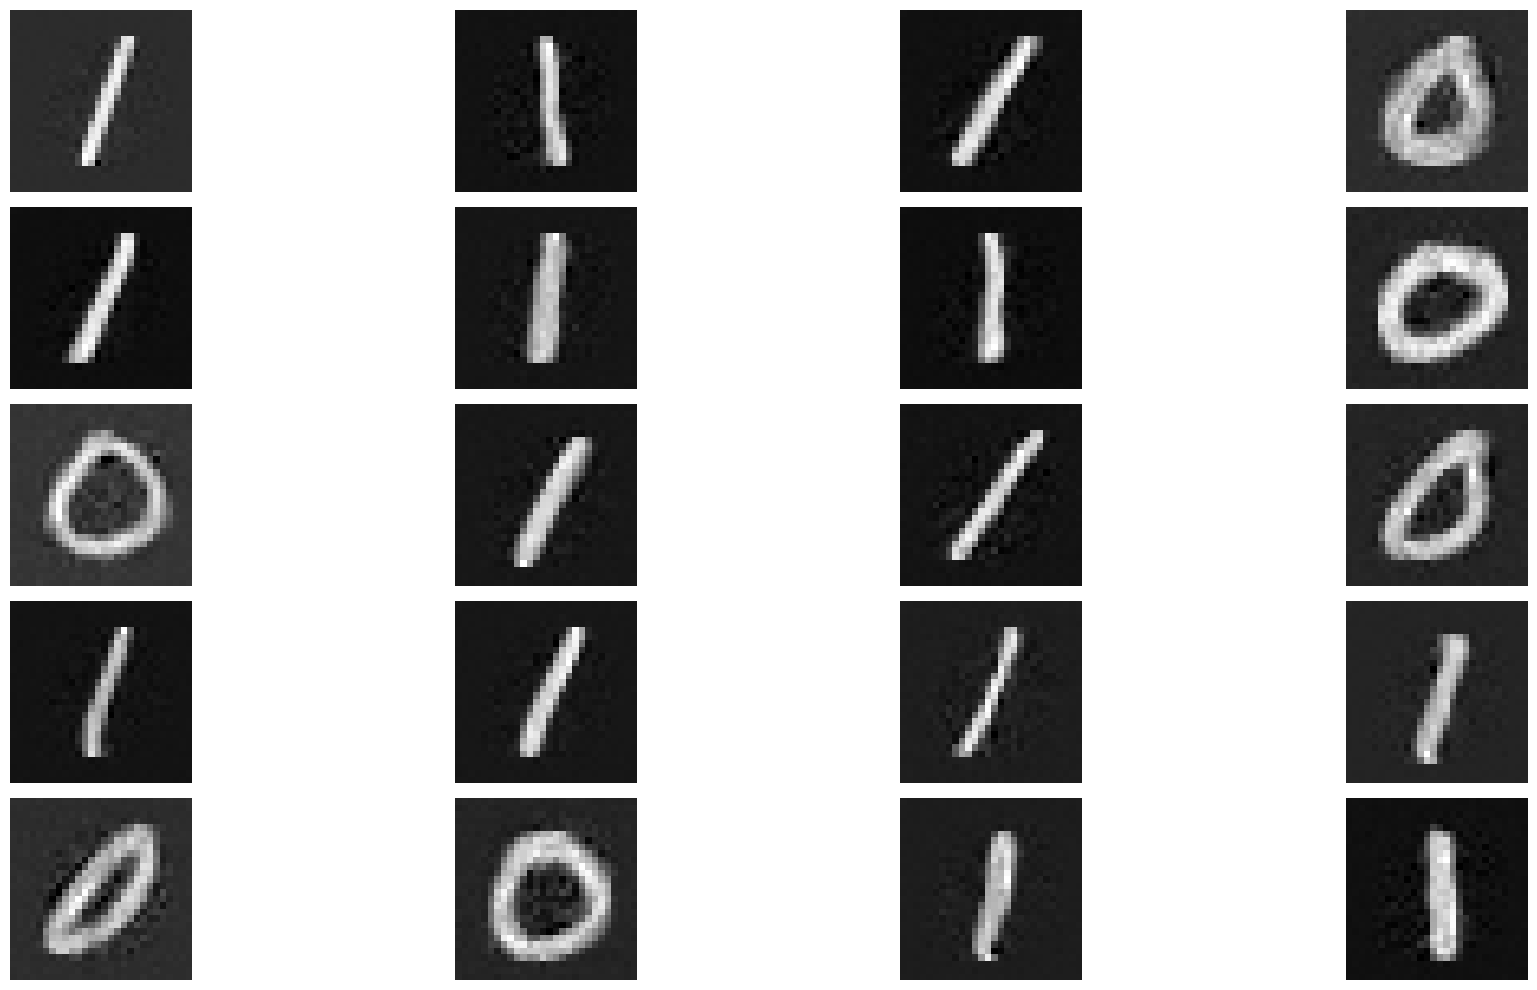

📈 Epoch 100 Summary:
   Train D Loss: 0.1377, Val D Loss: 0.2340
   Train G Loss: 6.3384, Val G Loss: 4.7362

🎉 Training completed!

🎨 Final comprehensive visualization:


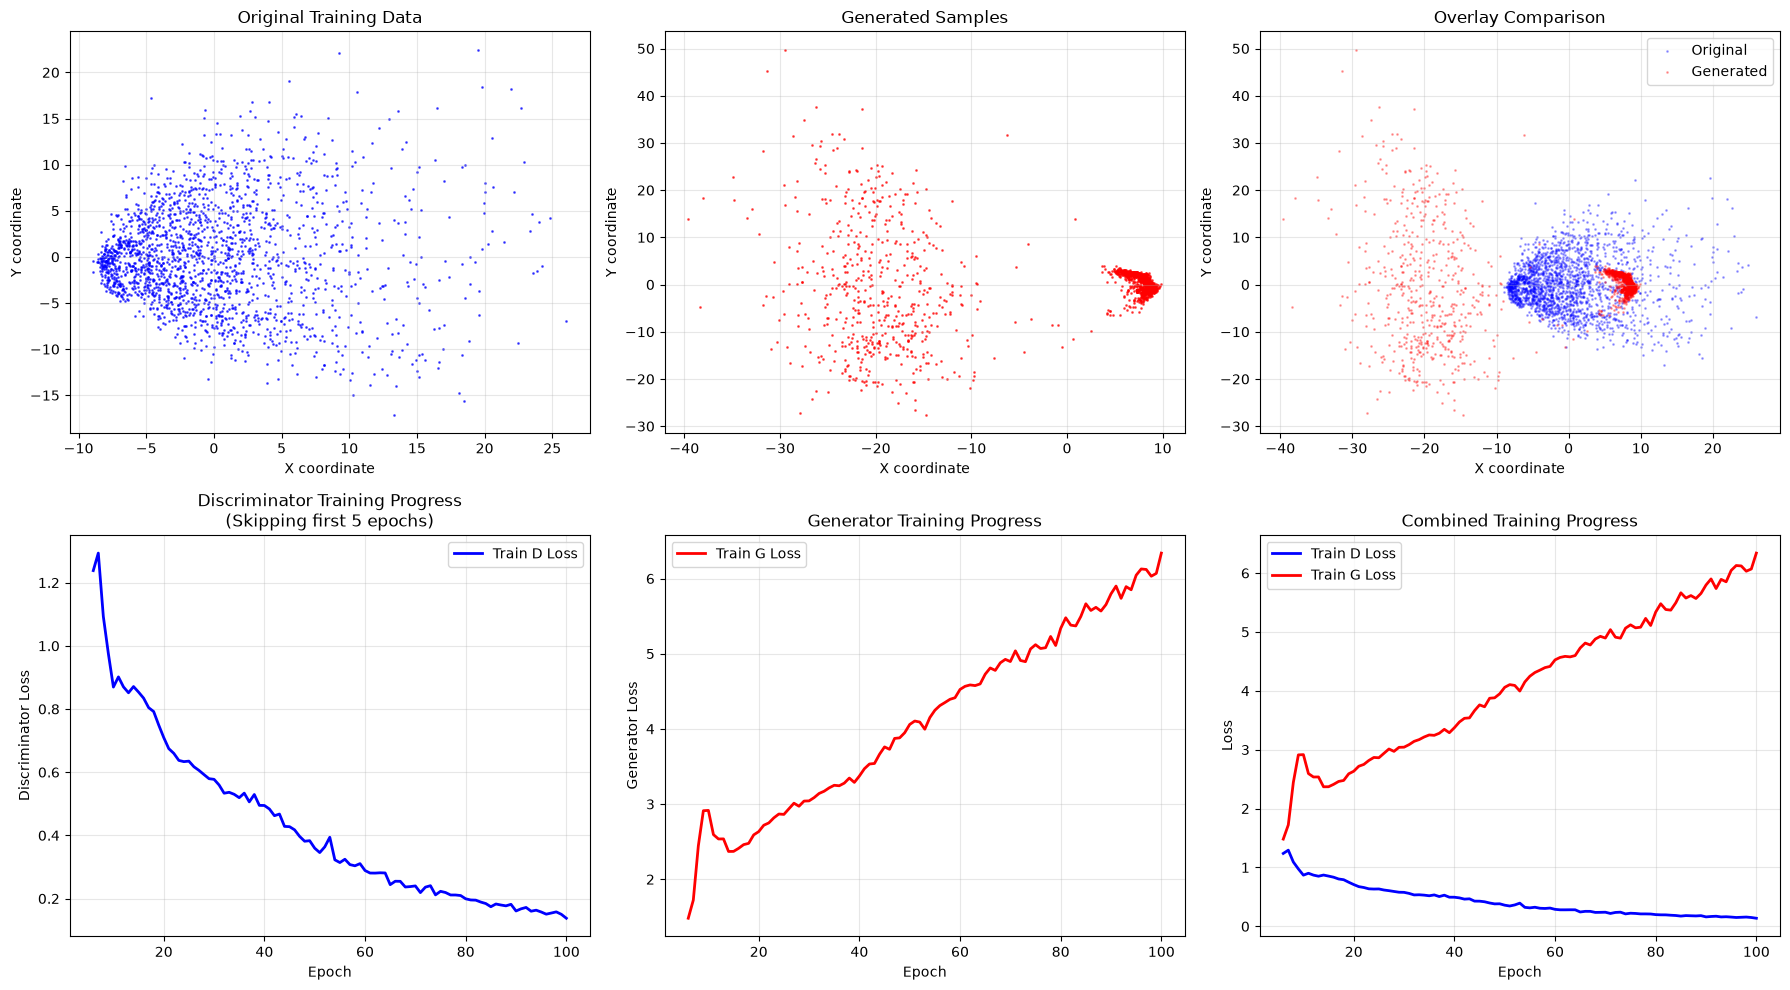

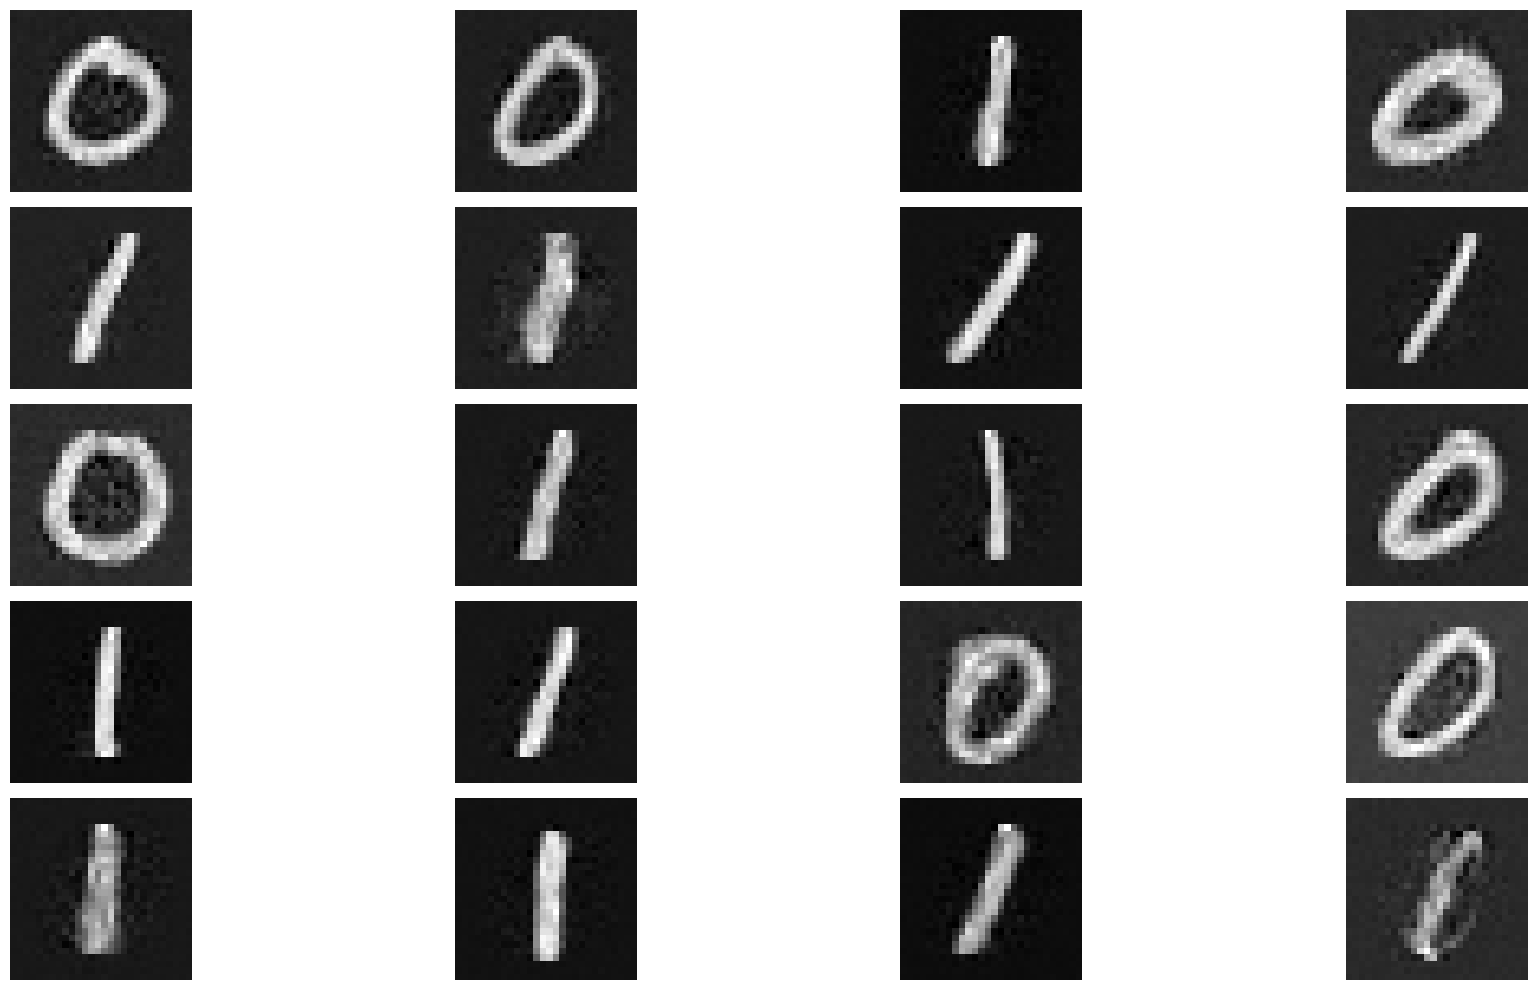

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


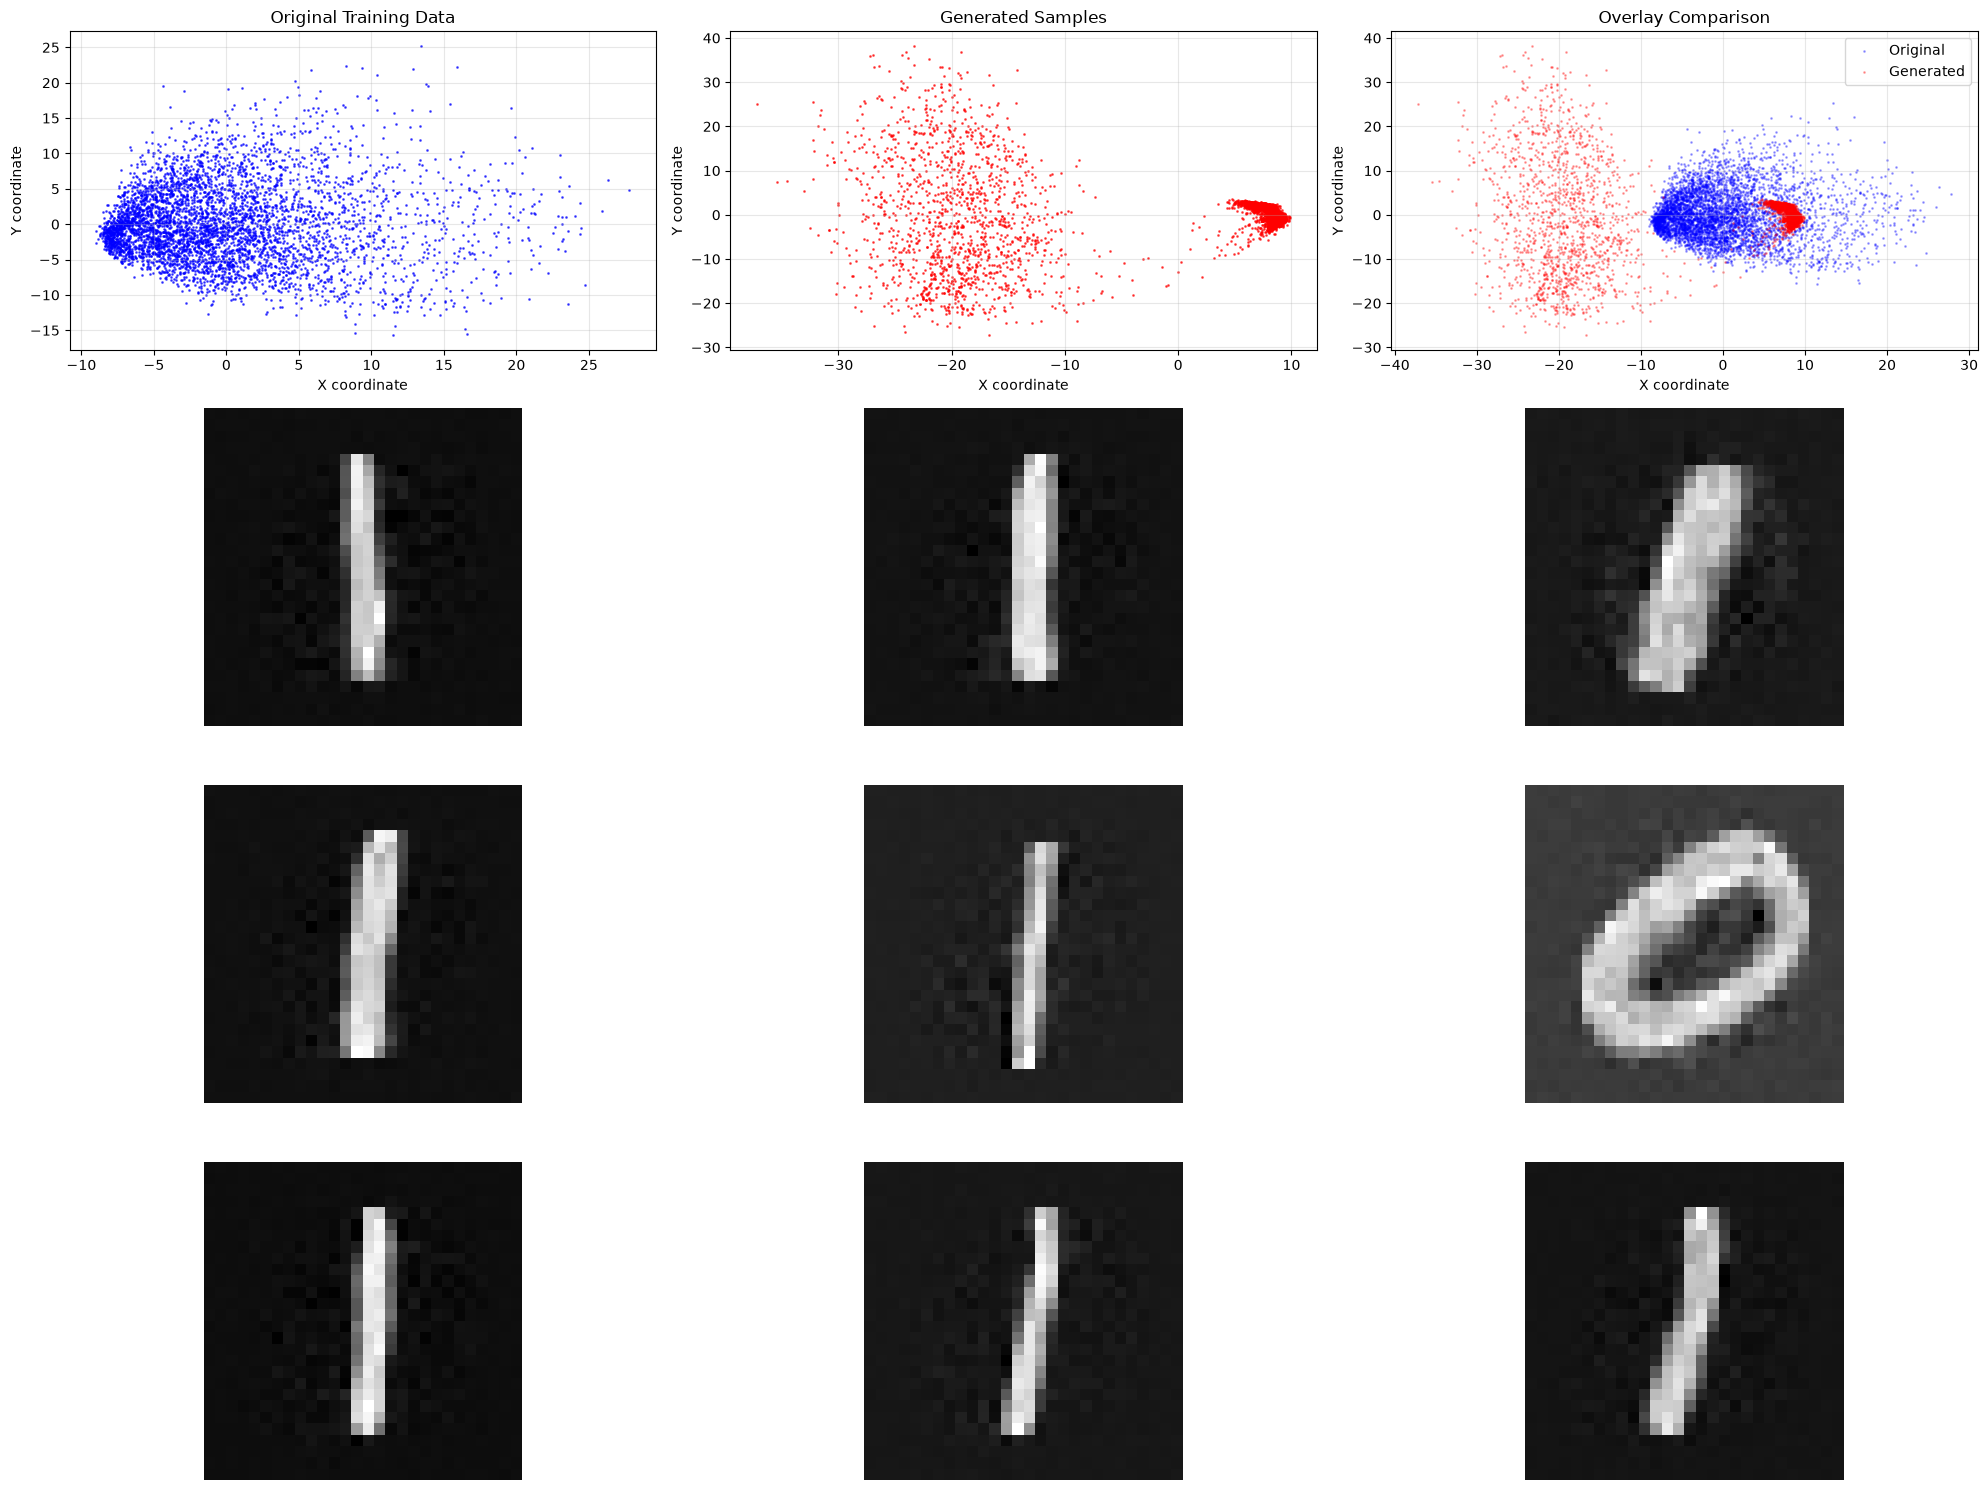

Real data confidence: 0.140
Fake data confidence: 0.083


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].to(device).float()
    real_batch = real_batch.reshape([100, INPUT_DIM])
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
